<h1>RALLY EPISODES IN MEME COIN PERPETUAL FUTURES: A RULE-BASED DETECTION AND DERIVATIVE MARKET CHARACTERISATION</h1>

<h4>LUT University | Master's Programme in Business Analytics | 2026</h4>

<b>Research Overview</b>

This research develops a transparent, rule-based framework for identifying and characterising rally episodes in meme coin perpetual futures markets. Using price movements and time-based criteria, the detection rule identifies rally episodes and divides each episode into four phases: <b>pre-rally, rise, fall, and post-rally</b>, with an additional "outside" class representing observations that do not belong to an identified rally episode.

The analysis then examines the behaviour of four derivative-market variables— <b>open interest, funding rate, long/short ratio, and traded volume </b>across the identified phases. These variables are used as explanatory features in two multinomial logistic regression (MLR) specifications: a <b>same-day descriptive model</b> that examines contemporaneous relationships between derivative-market conditions and rally phases, and a <b>lagged predictive model</b> that evaluates whether historical derivative-market observations contain information useful for classifying subsequent phases. Price-derived variables are intentionally excluded from both regression specifications to distinguish the information provided by derivatives-market activity from the price movements used to establish the phase labels.

The analysis covers <b>April 2022 to April 2026</b>, drawing on CoinGecko for meme coin universe identification and Coinalyze for perpetual futures market data. Because rally phases are labelled retrospectively using price information, the predictive analysis evaluates the classification of historically identified phases and should not be interpreted as a validated real-time rally detection or trading signal.

<b>Notebook Contents</b>
<ol>
    <li>Unoverse Definition</li>
    <li>Data Collection</li>
    <li>Rally Detection Rule</li>
    <li>Data Modelling Multinomial Logistic Reression</li>
    <li>Future Work: Google trend Integration</li>
    <li>Data Quality Issues and Resolution notes</li>
</ol>

<b>Full Master's Thesis</b>

The complete thesis, including the theoretical framework, literature review, detailed methodology, empirical findings, discussion, and limitations, is available through LUT University's institutional publication repository. 
<a href="https://urn.fi/URN:NBN:fi-fe20260708110050"> Thesis Link</a>


<h4 style="color:green;">Required Libraries, Shared Constant and Helper Declaration.</h4>
This section establishes the computational environment and shared configurations required for the analysis. It imports the Python libraries used for data collection, manipulation, statistical modelling, validation, and visualisation, while defining common constants and helper functions used throughout the notebook.

To ensure consistency across the analytical workflow, the setup defines a fixed random seed, the five rally-phase labels, and the feature specifications used in the descriptive and predictive multinomial logistic regression models. The predictive specification incorporates derivative-market features observed at lags of one, three, and seven days.

Additionally, centralised file paths and reusable functions are defined to standardise the saving of figures, tables, and analytical outputs. These configurations support reproducibility, maintain consistency across notebook sections, and simplify the execution of the analysis across different computing environments.
The Google Trends integration, presented in Section 5 as an extension for future research, is kept separate from the dependencies required for the core analysis.

In [4]:
# Setup: imports, shared constants, and helpers

# Everything declared here is reused across the notebook. Downstream cells assume these names are in scope, so always run this cell first 
# after a kernel restart.

#!pip install pycoingecko requests pandas numpy scipy statsmodels scikit-learn matplotlib pytrends

# Core libraries
from pycoingecko import CoinGeckoAPI # Connects to the CoinGecko API
import requests # Sends HTTP requests to APIs
import pandas as pd # Data manipulation
import numpy as np  # Numerical operations
import time # Execution timing
import pickle # Save / load model objects
import random  #used in the reproducibility code line
from datetime import datetime, timezone

# Stats and modelling
import statsmodels.api as sm # statistics inference (coefficients, p-values)
from scipy import stats # Normal-distribution tables for CIs
from scipy.signal import find_peaks # Local-peak detector for rally rule

# sklearn (out-of-sample evaluation + walk-forward CV)
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import (classification_report, confusion_matrix,
                             f1_score, accuracy_score)
from statsmodels.stats.outliers_influence import variance_inflation_factor #used to implement correlation analysis

# Plotting
import matplotlib.pyplot as plt #Used for Data Visualisation

# Reproducibility
random.seed(42)
np.random.seed(42)


# Shared constants used by multiple cells

PHASE_NAMES     = {0: "outside", 1: "pre_rally", 2: "rise",
                   3: "fall",    4: "post_rally"}
PHASE_ORDER     = ["outside", "pre_rally", "rise", "fall", "post_rally"]
PHASE_CODES     = [0, 1, 2, 3, 4]
NON_REF_CLASSES = [1, 2, 3, 4]
PHASE_COLORS    = {
    "outside"   : "#d4d4d4",
    "pre_rally" : "#fde047",
    "rise"      : "#22c55e",
    "fall"      : "#ef4444",
    "post_rally": "#737373",
}

# Derivative-market feature lists (built once, reused everywhere)
BASE_FEATURES = [
    "oi_log_z",  "oi_logdiff_z",  "oi_dev14_z",
    "fr_level_z", "fr_cum7_z",    "fr_sign",
    "lsr_level_z", "lsr_dev14_z",
    "vol_log_z",  "vol_logdiff_z",
]
T0_FEATURES = [
    "oi_log_z_t0",  "oi_logdiff_z_t0",  "oi_dev14_z_t0",
    "fr_level_z_t0", "fr_cum7_z_t0",    "fr_sign_t0",
    "lsr_level_z_t0", "lsr_dev14_z_t0",
    "vol_log_z_t0",  "vol_logdiff_z_t0",
    "lsr_observed",
]
LAGS            = [1, 3, 7]                              # Predictive model lags
LAGGED_FEATURES = [f"{f}_t{lag}" for lag in LAGS for f in BASE_FEATURES]
PREDICTORS      = LAGGED_FEATURES + ["lsr_observed"]


# Small utilities

def sig_stars(p):
    """Significance stars for coefficient tables."""
    if p < 0.001: return "***"
    if p < 0.01:  return "** "
    if p < 0.05:  return "*  "
    if p < 0.10:  return ".  "
    return "   "


def ensure_tz_naive(df, date_col="date"):
    """Return a copy with the date column converted to tz-naive Timestamps."""
    out = df.copy()
    s = pd.to_datetime(out[date_col])
    if s.dt.tz is not None:
        s = s.dt.tz_localize(None)
    out[date_col] = s
    return out


<h4 style="color:green;">API Setup and Jupyter Notebook Integration</h4>


This section establishes the connections to CoinGecko and Coinalyze, the two external data providers used in the research. CoinGecko's public API is accessed through the `pycoingecko` library, while Coinalyze is accessed through authenticated HTTP requests to retrieve perpetual futures market data.

The code includes connection checks to verify access to both services before data collection. For public sharing on GitHub, the original API credentials have been removed. Researchers wishing to reproduce the analysis must provide their own valid credentials and configure their local environment accordingly.

In [5]:
#Your API Keys 

#apikey_gecko="Add your CoinGecko API"
#apikey_alyze="Add your Coinalyze API"

# CoinGecko Client 
# Modified to use the free API endpoint instead of Pro API
cg = CoinGeckoAPI()

# Coinalyze Client
COINALYZE_BASE_URL = 'https://api.coinalyze.net/v1'
COINALYZE_HEADERS = {'api_key': apikey_alyze}

# Test Both Connections 
print("CoinGecko:", cg.ping())
r = requests.get(f'{COINALYZE_BASE_URL}/exchanges', headers=COINALYZE_HEADERS)
print("Coinalyze Status:", r.status_code)


CoinGecko: {'gecko_says': '(V3) To the Moon!'}
Coinalyze Status: 200


In [6]:
# Coinalyze API requires integer Unix timestamps for the `from`/`to` parameters.
# pandas Timestamps are kept alongside them for display, plotting, and date arithmetic.
WINDOW_START    = int(datetime(2022, 4, 1,  tzinfo=timezone.utc).timestamp())
WINDOW_END      = int(datetime(2026, 4, 30, tzinfo=timezone.utc).timestamp())
WINDOW_START_DT = pd.Timestamp(WINDOW_START, unit="s", tz="UTC").tz_localize(None)
WINDOW_END_DT   = pd.Timestamp(WINDOW_END,   unit="s", tz="UTC").tz_localize(None)
INTERVAL = "daily"

#Having an idea of what the data looks like in the coingecko platform. No so much to get on perpetual data.
#cg.get_coins_markets(
                #vs_currency='usd',
                #category='meme-token',
                #order='market_cap_desc',
                #per_page=250,
                #sparkline=False
            #)

<h3 style ="color:blue;"> Universe Definition.</h3>

In this section, we define the set of meme coins that will be used throughout the analysis. CoinGecko lists a wide range of meme coins, but to keep the research manageable and limit the size of the universe, we apply a market capitalization filter of more than $5 million. This helps ensure that the sample includes coins with sufficient market interest.

In [4]:
# Filtration Process: Fetching Meme Coins From CoinGecko based on the selected Filter.

# MIN_MARKET_CAP = 5_000_000
#  
# all_coins = []
# page      = 1
# 
# print("Fetching meme coins from CoinGecko...") # Keep us updated on the coin collection process.
# 
# while True:
#     batch = cg.get_coins_markets(
#         vs_currency = "usd",
#         category    = "meme-token",
#         order       = "market_cap_desc",
#         per_page    = 250,
#         page        = page,
#         sparkline   = False,
#     )
#     if not batch:
#         break
#     all_coins.extend(batch)
#     print(f"  Page {page}: {len(batch)} coins fetched")
#     if len(batch) < 250:
#         break
#     page += 1
#     time.sleep(1.5)
# 
# # Build the raw frame (every coin returned by CoinGecko above the cap)
# df_raw = pd.DataFrame([
#     {
#         "name"          : c["name"],
#         "symbol"        : c["symbol"].upper(),
#         "coingecko_id"  : c["id"],
#         "market_cap_usd": c["market_cap"],
#     }
#     for c in all_coins
#     if c.get("market_cap") and c["market_cap"] >= MIN_MARKET_CAP  # Filter being used
# ]).sort_values("market_cap_usd", ascending=False).reset_index(drop=True)
# 
# # Resolve ticker collisions explicitly: when two CoinGecko entries share a
# # ticker (e.g. several tokens called "DOG"), keep the one with the largest
# # market cap and log the rejected duplicates so the audit trail is clear.
# 
# dup_mask = df_raw.duplicated(subset="symbol", keep="first")
# df_dup_rejected = df_raw[dup_mask].copy()
# df_meme_coins = df_raw[~dup_mask].reset_index(drop=True)
# 
# df_meme_coins.to_csv("meme_coins_filtered.csv",         index=False)
# df_dup_rejected.to_csv("meme_coins_dup_rejected.csv",   index=False)
# 
# print(f"\nMeme coins above ${MIN_MARKET_CAP:,} cap         : {len(df_raw)}")
# print(f"Unique tickers (kept for matching)         : {len(df_meme_coins)}")
# print(f"Duplicate-ticker entries rejected          : {len(df_dup_rejected)}")
# 
# if not df_dup_rejected.empty:
#     print(f"\n  Rejected duplicates (lower market cap of each ticker):")
#     for _, row in df_dup_rejected.iterrows():
#         # Show what we kept for the same ticker
#         kept = df_meme_coins[df_meme_coins["symbol"] == row["symbol"]].iloc[0]
#         print(f"    {row['symbol']:<10} dropped: '{row['name']}' "
#               f"(${row['market_cap_usd']/1e6:.1f}M, id={row['coingecko_id']})")
#         print(f"    {' '*10} kept   : '{kept['name']}' "
#               f"(${kept['market_cap_usd']/1e6:.1f}M, id={kept['coingecko_id']})")
# 
# print(f"\n  Saved → meme_coins_filtered.csv      ({len(df_meme_coins)} rows)")
# print(f"  Saved → meme_coins_dup_rejected.csv  ({len(df_dup_rejected)} rows)")
# print(f"\nPreview:")
# print(df_meme_coins.head(10).to_string(index=False))
# 
# # Final results are saved as "meme_coins_filtered" in csv file where all duplicate coins are taken out.

In [5]:
df_meme_coins = pd.read_csv("meme_coins_filtered_final.csv")
df_dup_rejected = pd.read_csv("meme_coins_dup_rejected_final.csv")

df_meme_coins
df_dup_rejected

,name,symbol,coingecko_id,market_cap_usd
0,Binance-Peg Dogecoin,DOGE,binance-peg-dogecoin,262878537
1,Binance-Peg SHIB,SHIB,binance-peg-shib,51851580
2,Asteroid The Space Shiba Inu,ASTEROID,asteroid-the-space-shiba-inu,14105629
3,LandWolf,WOLF,landwolf-0x67,7879251
4,Wojak,WOJAK,wojak-4,7608768
5,Own The Doge,DOG,the-doge-nft,6312026
6,Tron Bull,BULL,tron-bull,5514600
7,Broccoli,BROCCOLI,broccoli-3,5159164


The filtering process yielded 204 meme coins listed on CoinGecko with a market capitalization above $5 million.

Having identified the full set of meme coins, the next step is data retrieval from Coinalyze. Coinalyze provides perpetual and spot market data for a wide range of cryptocurrencies, including meme coins, across multiple trading (exchange) platforms.

It is important to note that some widely traded coins, such as Dogecoin, are listed on many exchange platform, while newer coins may be available on only one. To collect perpetual data for a given coin, it must be matched to an exchange identifier recognized by the Coinalyze API. For example, .A corresponds to Binance.

The next API request retrieves the exchange platforms available on Coinalyze, along with their corresponding codes.

In [6]:
# Get the official list of supported exchanges from Coinalyze
r = requests.get(
    f"{COINALYZE_BASE_URL}/exchanges",
    headers=COINALYZE_HEADERS
)
print(f"Status: {r.status_code}")
print(r.json())


Status: 200
[{'name': 'Poloniex', 'code': 'P'}, {'name': 'Polymarket', 'code': 'O'}, {'name': 'Bitforex', 'code': 'D'}, {'name': 'Kraken', 'code': 'K'}, {'name': 'Bithumb', 'code': 'U'}, {'name': 'Bitstamp', 'code': 'B'}, {'name': 'Hyperliquid', 'code': 'H'}, {'name': 'BitFlyer', 'code': 'L'}, {'name': 'BtcMarkets', 'code': 'M'}, {'name': 'Bit2c', 'code': 'I'}, {'name': 'MercadoBitcoin', 'code': 'E'}, {'name': 'Independent Reserve', 'code': 'N'}, {'name': 'Gemini', 'code': 'G'}, {'name': 'Gate.io', 'code': 'Y'}, {'name': 'Deribit', 'code': '2'}, {'name': 'OKX', 'code': '3'}, {'name': 'Coinbase', 'code': 'C'}, {'name': 'Bitfinex', 'code': 'F'}, {'name': 'Luno', 'code': 'J'}, {'name': 'BitMEX', 'code': '0'}, {'name': 'Phemex', 'code': '7'}, {'name': 'WOO X', 'code': 'W'}, {'name': 'Huobi', 'code': '4'}, {'name': 'dYdX', 'code': '8'}, {'name': 'Bybit', 'code': '6'}, {'name': 'Binance', 'code': 'A'}, {'name': 'Lighter', 'code': 'T'}, {'name': 'Aster', 'code': 'S'}]


With the exchange platform list identified, the next step was to collect perpetual data for the rally detection rule creation and phase characterisation.

<span style="color:green;"> Note </span>: The first attempt exposed a symbol formatting issue. Each coin symbol had to be constructed correctly using the right ticker symbol, the trading currency, USDT in this case, the perpetual suffix, and the exchange code. The exact symbol format differs across exchanges, for example, DOGEUSDT_PERP.A retrieves Dogecoin perpetual data on Binance, while DOGE_USDT.Y is used on Gate.io. A sample request therefore had to be run first to determine how symbols are named across the different exchange platforms.

In addition, coins with multipliers in their names, such as 1000 or 1000000, also had to be handled carefully during symbol construction.

<h4 style="color: green;">Matching Coins from Coingecko with their Perpetual Listing data on Coinalyze & Selecting the main Exchange platform for data collection</h4>

With the coins list gotten from CoinGecko and stored in df_meme_coins and the previously discussed issues which have been accessed, the next step will be to find which coins actually have perpetual listing on the Coinalyze and choose the exchange platform whose code will be used to extract the required data through a simple priority rule. This task will be conducted as follows.
<ul>
    <li>Firstly, with the proper symbol of the coin including the perpetual part, each coin will be searched through the Coinalyze platform and the number of listings (exchange platform the coin is found on) through a lookup function and the results are recorded (df_all_listings)</li>
    <li>After doing the above, a list of coins with perpetual data will be returned. Now that all the coins with perpetual data have been selected with their respective exchange platforms, a priority rule for the exchange platforms need to be developed to select a convevient platform for each coin's data collection.</li>
    <li>The initial priority rule was based on the exchange platforms' distribution on the collected coins. The platform that had the most coin listed was ranked the highest and so on. Once the first priority rule was adopted for derivatives collection, a second-order question surfaced: whether the exchange chosen at the matching stage is the right one. The original rule ranked exchanges by the number of meme coins they listed and walked that ranking down per coin. Under this rule, Gate.io became the primary venue for most majors (DOGE, SHIB, PEPE, FLOKI, BONK) because it carries the broadest meme-coin catalogue. Cross-checking against Coinalyze aggregate statistics revealed that these same coins concentrate the bulk of their derivative activity elsewhere for instance,  DOGE open interest, for instance, sits at roughly 429 million dollar on Binance against 86–165 million dollar at Bybit, OKX, and Hyperliquid combined, with Gate.io contributing a small fraction. Anchoring the entire analysis to Gate.io for these coins risks describing positioning at a non-representative venue.

As a result, the rule was replaced with a per-coin liquidity criterion. For each coin, the primary exchange is defined as the USDT perpetual venue with the highest median daily quote volume over the most recent 90 days of available data, with ties within a 25 percent band broken by historical coverage. This choice selects Binance or Bybit for the major coins and Gate.io for much of the long tail, better reflecting where each coin actually trades.
Liquidity is a standard methodological anchor in market microstructure research, and it is derived directly from the data already collected through Coinalyze. It also aligns with the downstream analyses, including tighter spreads, deeper open interest pools, and longer histories on the selected venue. The main cost is additional API calls during the matching stage, since OHLCV data must be queried for each candidate listing before the primary exchange is fixed.</li>
</ul>

The output of this execution will be the following:
    <ul>
        <li>A dataframe for coins with perpetual futures on Coinalyze and the chosen exchange platform(keep)</li>
        <li>Another dataframe for coins with no perpetual futures found (dropped)</li>
    </ul> 

In [ ]:
# Phase A: Discover all USDT perpetual listings per coin (df_all_listings)
# Phase B: Query OHLCV for each candidate listing, score by 90-day median
#           quote volume, select the winning exchange per coin
# Phase C: Write df_matched (one row per coin) and df_excluded (no listing)

# OHLCV pulled here is cached in OHLCV_CACHE so Phase 1 does not re-fetch.

 
EXCHANGE_NAMES = {
    "A": "Binance",    "6": "Bybit",        "3": "OKX",
    "4": "Huobi",      "K": "Kraken",        "Y": "Gate.io",
    "W": "WOO X",      "S": "Aster",         "P": "Poloniex",
    "0": "BitMEX",     "F": "Bitfinex",      "2": "Deribit",
    "7": "Phemex",     "8": "dYdX",          "H": "Hyperliquid",
    "V": "Vertex",     "C": "Coinbase",      "G": "Gemini",
    "D": "Bitforex",   "U": "Bithumb",       "B": "Bitstamp",
    "L": "BitFlyer",   "M": "BtcMarkets",    "T": "Lighter",
    "I": "Bit2c",      "E": "MercadoBitcoin","N": "Independent Reserve",
}
 
LIQUIDITY_WINDOW_DAYS = 90    # window for the median quote volume score
TIE_BAND_PCT          = 25    # ties resolved by history if scores within ± this
PAUSE_OHLCV           = 1.0   # seconds between OHLCV calls during scoring
MAX_RETRY_PASSES      = 2     # extra passes for coins where every candidate failed
 
OHLCV_CACHE = {}              # cz_symbol → DataFrame
 
 
def fetch_daily_ohlcv(coinalyze_symbol: str) -> pd.DataFrame:
    """
    Fetches daily OHLCV from Coinalyze for one symbol over the full window.
    Returns DataFrame with all 9 fields, or empty DataFrame on failure.
 
    Successful results are memoised in OHLCV_CACHE so repeat calls are free.
    Failures (transient errors, rate limits, empty responses) are NOT cached
    so the next caller can retry. The retry loop handles 429s with exponential
    backoff and tolerates one transient non-200 response.
    """
    if coinalyze_symbol in OHLCV_CACHE:
        return OHLCV_CACHE[coinalyze_symbol]
 
    url    = f"{COINALYZE_BASE_URL}/ohlcv-history"
    params = {
        "symbols" : coinalyze_symbol,
        "interval": INTERVAL,
        "from"    : WINDOW_START,
        "to"      : WINDOW_END,
    }
 
    last_status = None
    for attempt in range(5):
        try:
            resp = requests.get(url, headers=COINALYZE_HEADERS,
                                params=params, timeout=30)
            last_status = resp.status_code
 
            if resp.status_code == 429:
                # Rate limit — back off. Retry-After can be fractional
                # (e.g. "6.105"), so parse via float before int().
                retry_after_raw = resp.headers.get("Retry-After")
                try:
                    wait = max(1, int(float(retry_after_raw)) + 1)
                except (TypeError, ValueError):
                    wait = 10 * (attempt + 1)
                print(f"\n    ⏳ Rate limited on {coinalyze_symbol} — "
                      f"waiting {wait}s...", end="  ")
                time.sleep(wait)
                continue
 
            if 500 <= resp.status_code < 600:
                # Transient server error — short backoff and retry
                time.sleep(2 ** attempt)
                continue
 
            if resp.status_code != 200:
                # Genuine failure (e.g. 400 bad symbol). Do not cache.
                return pd.DataFrame()
 
            data = resp.json()
 
        except requests.RequestException as e:
            time.sleep(2 ** attempt)
            continue
 
        # 200 OK — parse and cache
        if not data or not isinstance(data, list):
            # Empty response after success: cache as empty (genuinely no data)
            OHLCV_CACHE[coinalyze_symbol] = pd.DataFrame()
            return OHLCV_CACHE[coinalyze_symbol]
 
        history = data[0].get("history", [])
        if not history:
            OHLCV_CACHE[coinalyze_symbol] = pd.DataFrame()
            return OHLCV_CACHE[coinalyze_symbol]
 
        df = pd.DataFrame(history).rename(columns={
            "t" : "timestamp",
            "o" : "open",
            "h" : "high",
            "l" : "low",
            "c" : "close",
            "v" : "base_volume",
            "bv": "taker_buy_base_volume",
            "tx": "num_trades",
            "btx": "taker_buy_trades",
        })
        df["date"] = pd.to_datetime(df["timestamp"], unit="s",
                                     utc=True).dt.normalize()
        df = df[[
            "date", "timestamp",
            "open", "high", "low", "close",
            "base_volume", "taker_buy_base_volume",
            "num_trades", "taker_buy_trades",
        ]]
        OHLCV_CACHE[coinalyze_symbol] = df
        return df
 
    # All retries exhausted — do not cache, let the caller retry later
    print(f"\n    ✗ Exhausted retries for {coinalyze_symbol} "
          f"(last status: {last_status})")
    return pd.DataFrame()
 
 
def liquidity_score(df_ohlcv: pd.DataFrame) -> tuple:
    """
    Computes the median daily quote volume over the most recent
    LIQUIDITY_WINDOW_DAYS of available data.
    Returns (median_quote_volume, n_days_total) — both 0 if empty.
    """
    if df_ohlcv.empty:
        return 0.0, 0
 
    df = df_ohlcv.sort_values("date").tail(LIQUIDITY_WINDOW_DAYS)
    quote_vol = (df["base_volume"] * df["close"]).dropna()
    if quote_vol.empty:
        return 0.0, len(df_ohlcv)
    return float(quote_vol.median()), len(df_ohlcv)
 
 
def step2_phaseA_discover(df_coins):
    """Build df_all_listings: every USDT perpetual on Coinalyze per coin."""
    # Defensive check — Step 1 should have already deduplicated by ticker.
    # If it didn't, complain loudly rather than silently dropping rows.
    n_dups = df_coins.duplicated(subset="symbol").sum()
    if n_dups > 0:
        raise ValueError(
            f"df_coins contains {n_dups} duplicate ticker(s). "
            f"Run Step 1 deduplication before calling this function."
        )
 
    df_coins = df_coins.reset_index(drop=True)
    total    = len(df_coins)
 
    print("=" * 65)
    print("STEP 2 / Phase A — Discovering USDT perpetual listings")
    print("=" * 65)
    print(f"  Input coins from Step 1: {total}")
 
    r = requests.get(f"{COINALYZE_BASE_URL}/future-markets",
                     headers=COINALYZE_HEADERS, timeout=30)
    if r.status_code != 200:
        raise RuntimeError(f"Failed: {r.status_code} {r.text[:200]}")
 
    all_futures = r.json()
    print(f"  Total futures on Coinalyze   : {len(all_futures)}")
 
    usdt_perps = [
        f for f in all_futures
        if f.get("is_perpetual") is True
        and f.get("quote_asset", "").upper() == "USDT"
        and f.get("has_ohlcv_data") is True
    ]
    print(f"  USDT perpetuals (OHLCV only) : {len(usdt_perps)}")
 
    # Index by both prefixed and stripped base_asset
    perp_lookup = {}
    for c in usdt_perps:
        base = c["base_asset"].upper()
        perp_lookup.setdefault(base, []).append(c)
        if base.startswith("1000000"):
            perp_lookup.setdefault(base[7:], []).append(c)
        elif base.startswith("1000"):
            perp_lookup.setdefault(base[4:], []).append(c)
 
    print(f"\n  Matching {total} coins to listings...")
    print("─" * 65)
 
    rows = []
    for idx, row in df_coins.iterrows():
        ticker    = row["symbol"].upper()
        contracts = perp_lookup.get(ticker, [])
 
        # Deduplicate (same contract may sit under multiple keys)
        seen = set()
        unique = []
        for c in contracts:
            if c["symbol"] in seen:
                continue
            seen.add(c["symbol"])
            unique.append(c)
        contracts = unique
 
        if not contracts:
            print(f"  [{idx+1:>3}/{total}] {ticker:<14} ❌ no USDT perpetual")
            continue
 
        for c in contracts:
            code = c["exchange"]
            base = c["base_asset"].upper()
            if base.startswith("1000000"):
                prefix = "1000000"
            elif base.startswith("1000"):
                prefix = "1000"
            else:
                prefix = "none"
 
            rows.append({
                "name"             : row["name"],
                "symbol"           : ticker,
                "coingecko_id"     : row["coingecko_id"],
                "market_cap_usd"   : row["market_cap_usd"],
                "coinalyze_symbol" : c["symbol"],
                "base_asset"       : base,
                "exchange_code"    : code,
                "exchange"         : EXCHANGE_NAMES.get(code, f"Exchange_{code}"),
                "multiplier_prefix": prefix,
                "has_lsr_data"     : c["has_long_short_ratio_data"],
            })
 
        syms = ", ".join(c["symbol"] for c in contracts)
        print(f"  [{idx+1:>3}/{total}] {ticker:<14} ✅ {len(contracts)} listing(s)")
 
    df_all = pd.DataFrame(rows)
    df_all.to_csv("step2_phase1_all_listings.csv", index=False)
 
    n_matched = df_all["symbol"].nunique() if len(df_all) > 0 else 0
    print(f"\n  Coins matched : {n_matched} / {total}")
    print(f"  Total listings: {len(df_all)}")
    print(f"  Saved → step2_phase1_all_listings.csv")
    return df_all
 
 
def _score_one_coin(ticker, coin_listings):
    """
    Scores every candidate listing for one coin.
    Returns a list of dicts: [{listing, score, n_days}, ...].
    Empty entries (n_days == 0) are kept so the caller can detect failures.
    """
    candidates = []
    for _, listing in coin_listings.iterrows():
        sym = listing["coinalyze_symbol"]
        df_ohlcv = fetch_daily_ohlcv(sym)
        time.sleep(PAUSE_OHLCV)
        score, n_days = liquidity_score(df_ohlcv)
        candidates.append({
            "listing": listing,
            "score"  : score,
            "n_days" : n_days,
            "symbol" : sym,
        })
    return candidates
 
 
def step2_phaseB_score_and_select(df_all, df_original):
    """
    Phase B — score each candidate by 90-day median quote volume and
    select the winner per coin. Ties (within TIE_BAND_PCT %) go to the
    listing with the longest OHLCV history.
 
    Implementation:
      Pass 1 — score every coin.
      Passes 2..N — for any coin where ALL candidates returned 0 days
        (i.e. every fetch failed transiently), re-score after a cooldown.
        This protects against rate-limit bursts wiping out genuine data.
    """
    print("\n" + "=" * 65)
    print("STEP 2 / Phase B — Scoring listings by liquidity")
    print("=" * 65)
    print(f"  Score window: {LIQUIDITY_WINDOW_DAYS}-day median quote volume")
    print(f"  Tie band    : ± {TIE_BAND_PCT}% (resolved by OHLCV history)")
    print(f"  Pause       : {PAUSE_OHLCV}s between calls")
    print("─" * 65)
 
    matched   = []
    excluded  = []
    score_log = []
 
    all_tickers = df_original["symbol"].str.upper().values
    only_listed = [t for t in all_tickers
                   if not df_all[df_all["symbol"] == t].empty]
    no_listing  = [t for t in all_tickers
                   if df_all[df_all["symbol"] == t].empty]
 
    # Coins with no listing at all → straight to excluded
    for ticker in no_listing:
        orig = df_original[
            df_original["symbol"].str.upper() == ticker
        ].iloc[0]
        excluded.append({
            "name"          : orig["name"],
            "symbol"        : ticker,
            "coingecko_id"  : orig["coingecko_id"],
            "market_cap_usd": orig["market_cap_usd"],
            "reason"        : "no USDT perpetual",
        })
 
    # Score the listed coins, with retry passes for transient failures
    pending = list(only_listed)
    coin_results = {}        # ticker → list of candidate dicts
 
    for pass_idx in range(MAX_RETRY_PASSES + 1):
        if not pending:
            break
 
        if pass_idx > 0:
            print(f"\n  Retry pass {pass_idx}: "
                  f"{len(pending)} coin(s) had no valid OHLCV in pass {pass_idx}.")
            print(f"  Cooling down 30s before retrying...")
            time.sleep(30)
            # Force-evict the empty cache entries so retries actually re-hit the API
            for t in pending:
                listings = df_all[df_all["symbol"] == t]
                for sym in listings["coinalyze_symbol"]:
                    if sym in OHLCV_CACHE and OHLCV_CACHE[sym].empty:
                        del OHLCV_CACHE[sym]
 
        still_failed = []
        for n_done, ticker in enumerate(pending, 1):
            coin_listings = df_all[df_all["symbol"] == ticker]
            candidates = _score_one_coin(ticker, coin_listings)
            coin_results[ticker] = candidates
 
            valid = [c for c in candidates if c["n_days"] > 0]
            if not valid:
                still_failed.append(ticker)
                if pass_idx == 0:
                    print(f"  [{n_done:>3}/{len(pending)}] {ticker:<14} "
                          f"⏸  no OHLCV — will retry")
                continue
 
            # Pick top scorer; resolve ties via history
            valid.sort(key=lambda c: c["score"], reverse=True)
            top = valid[0]
            tie_floor = top["score"] * (1 - TIE_BAND_PCT / 100.0)
            tied = [c for c in valid if c["score"] >= tie_floor]
            if len(tied) > 1:
                tied.sort(key=lambda c: c["n_days"], reverse=True)
                chosen_c = tied[0]
                tie_note = f"  [tie: {len(tied)} venues, picked by history]"
            else:
                chosen_c = top
                tie_note = ""
 
            chosen = chosen_c["listing"]
            matched.append({
                "name"             : chosen["name"],
                "symbol"           : chosen["symbol"],
                "coingecko_id"     : chosen["coingecko_id"],
                "market_cap_usd"   : chosen["market_cap_usd"],
                "coinalyze_symbol" : chosen["coinalyze_symbol"],
                "base_asset"       : chosen["base_asset"],
                "exchange_code"    : chosen["exchange_code"],
                "exchange"         : chosen["exchange"],
                "multiplier_prefix": chosen["multiplier_prefix"],
                "has_lsr_data"     : chosen["has_lsr_data"],
                "selection_score"  : chosen_c["score"],
                "selection_n_days" : chosen_c["n_days"],
                "n_exchanges_found": len(coin_listings),
                "all_exchanges"    : ", ".join(coin_listings["exchange"].tolist()),
            })
 
            score_str = (f"${chosen_c['score']/1e6:>7.2f}M"
                         if chosen_c["score"] >= 1e6
                         else f"${chosen_c['score']/1e3:>7.1f}K")
            tag = " (retry)" if pass_idx > 0 else ""
            print(f"  [{n_done:>3}/{len(pending)}] {ticker:<14} → "
                  f"{chosen['exchange']:<14} {score_str}  "
                  f"({chosen_c['n_days']} days){tie_note}{tag}")
 
        pending = still_failed
 
    # Anything still failing after all passes → excluded
    for ticker in pending:
        orig = df_original[
            df_original["symbol"].str.upper() == ticker
        ].iloc[0]
        excluded.append({
            "name"          : orig["name"],
            "symbol"        : ticker,
            "coingecko_id"  : orig["coingecko_id"],
            "market_cap_usd": orig["market_cap_usd"],
            "reason"        : f"OHLCV unavailable after {MAX_RETRY_PASSES + 1} passes",
        })
        print(f"  ❌ {ticker:<14} excluded — no OHLCV after retries")
 
    # Build score log from coin_results for audit
    for ticker, candidates in coin_results.items():
        for c in candidates:
            score_log.append({
                "symbol"           : ticker,
                "exchange"         : c["listing"]["exchange"],
                "coinalyze_symbol" : c["symbol"],
                "median_quote_vol" : c["score"],
                "n_days"           : c["n_days"],
            })
 
    df_matched   = pd.DataFrame(matched)
    df_excluded  = pd.DataFrame(excluded)
    df_score_log = pd.DataFrame(score_log)
 
    df_matched.to_csv("step2_matched_coins.csv",   index=False)
    df_excluded.to_csv("step2_excluded_coins.csv",  index=False)
    df_score_log.to_csv("step2_liquidity_scores.csv", index=False)
 
    return df_matched, df_excluded, df_score_log
 
 
# RUN Step 2
df_all_listings = step2_phaseA_discover(df_meme_coins)
df_matched, df_excluded, df_score_log = step2_phaseB_score_and_select(
    df_all_listings, df_meme_coins
)
 
n_total = len(df_meme_coins)
print(f"\n{'='*65}")
print(f"STEP 2 COMPLETE")
print(f"{'='*65}")
print(f"  Total coins   : {n_total}")
print(f"  ✅ Matched    : {len(df_matched)}")
print(f"  ❌ Excluded   : {len(df_excluded)}")
 
if len(df_matched) > 0:
    print(f"\n  Selected exchange breakdown:")
    for exc, count in df_matched["exchange"].value_counts().items():
        print(f"    {exc:<20} : {count} coins")


From the 204 meme coins collected from CoinGecko, only 67 of them had perpetual data listing on the Coinalyze platform. After getting that information, we subsequently had to check which exchange platform on which the 66 coins were listed on was the best to collect the respective data nneeded for this research based on the liquidity priority rule we had created during the process. 


<h3 style ="color:blue;">Data Collection: Collecting the Required Perpetual Future Data for Analysis from Coinalyze</h3>

In this part, we aim to collect:
<ul>
   <li>Future Price and related features</li>
   <li>Funding rate</li>
   <li>Open interest</li>
   <li>Long/Short Ratio</li>
</ul>

Before doing so, we need to define the time frame from which the data will be collected.

The objective is to define a sufficiently broad time window for collecting price, volume, and derivative variables used to build the rally-detection rules and the subsequent classification task. The window is designed to include both well-known historical rally episodes and more recent market surges, so that the phase characterisation step is grounded in patterns observed across different market regimes. 

To preserve the quality of the sample, we also impose a minimum history requirement, meaning that each coin must have enough available observations within the selected window to support reliable analysis. This prevents newly listed or sparsely traded coins from introducing noise and ensures that the resulting dataset is comparable across assets and robust enough for identifying rally structures
<ul>
   <li>Time frame window: 1 April 2022 to 30 April 2026. Note: Drop all ongoing rally episodes, as done previously.</li> 
   <li>Minimum threshold: 90 days, because we were unable to identify anything consistent within a month in the previous analysis.</li>
   <li>Time granularity interval of 1 day will be used.</li>
</ul>

<h4 style="color:green;">Perpetual Future Price</h4>
The perpetual future price will be collected in order to apply the rally detection rule.

In [ ]:
# Daily OHLCV Collection (uses OHLCV_CACHE from Step 2)
 
MIN_DAYS = 90
 
print("Daily Futures OHLCV Collection")

print(f"  Coins to collect : {len(df_matched)}")
print(f"  Window           : 2021-01-01 → 2026-04-30")
print(f"  Min days filter  : {MIN_DAYS} days")
print(f"  Source           : OHLCV_CACHE (populated in Step 2)")

 
all_rows  = []
p1_excl   = []
 
for idx, row in df_matched.iterrows():
    ticker    = row["symbol"]
    cz_symbol = row["coinalyze_symbol"]
    exchange  = row["exchange"]
 
    df_coin = OHLCV_CACHE.get(cz_symbol, pd.DataFrame())
    if df_coin.empty:
        # Fallback: cache miss (shouldn't happen, but defensive)
        df_coin = fetch_daily_ohlcv(cz_symbol)
 
    if df_coin.empty:
        print(f"  [{idx+1:>3}/{len(df_matched)}] {ticker:<14} "
              f" no data  [EXCLUDED]")
        p1_excl.append({
            "name": row["name"], "symbol": ticker,
            "coinalyze_symbol": cz_symbol, "exchange": exchange,
            "reason": "API returned no data",
        })
        continue
 
    n_days = len(df_coin)
    if n_days < MIN_DAYS:
        print(f"  [{idx+1:>3}/{len(df_matched)}] {ticker:<14} "
              f" {n_days} days  [EXCLUDED — below {MIN_DAYS}-day floor]")
        p1_excl.append({
            "name": row["name"], "symbol": ticker,
            "coinalyze_symbol": cz_symbol, "exchange": exchange,
            "reason": f"only {n_days} days",
        })
        continue
 
    df_coin = df_coin.copy()
    df_coin["name"]              = row["name"]
    df_coin["symbol"]            = ticker
    df_coin["coinalyze_symbol"]  = cz_symbol
    df_coin["exchange"]          = exchange
    df_coin["multiplier_prefix"] = row["multiplier_prefix"]
    df_coin["market_cap_usd"]    = row["market_cap_usd"]
 
    all_rows.append(df_coin)
    print(f"  [{idx+1:>3}/{len(df_matched)}] {ticker:<14} ✅ {n_days} days")
 
if all_rows:
    df_ohlcv = pd.concat(all_rows, ignore_index=True)
    df_ohlcv = df_ohlcv[[
        "name", "symbol", "coinalyze_symbol", "exchange",
        "multiplier_prefix", "market_cap_usd",
        "date", "timestamp",
        "open", "high", "low", "close",
        "base_volume", "taker_buy_base_volume",
        "num_trades", "taker_buy_trades",
    ]].sort_values(["symbol", "date"]).reset_index(drop=True)
else:
    df_ohlcv = pd.DataFrame()
 
df_p1_excluded = pd.DataFrame(p1_excl)
df_ohlcv.to_csv("phase1_ohlcv.csv",       index=False)
df_p1_excluded.to_csv("phase1_excluded.csv", index=False)
 
n_retained = df_ohlcv["symbol"].nunique() if not df_ohlcv.empty else 0
print(f"\n{'='*65}")
print(f"PHASE 1 COMPLETE")
print(f"{'='*65}")
print(f"  Coins queried  : {len(df_matched)}")
print(f"  ✅ Retained    : {n_retained}")
print(f"  ❌ Excluded    : {len(df_p1_excluded)}")
if not df_ohlcv.empty:
    print(f"  Total rows     : {len(df_ohlcv):,}")
    print(f"  Date range     : {df_ohlcv['date'].min().date()} → "
          f"{df_ohlcv['date'].max().date()}")


Given tha time frame and the minimum availabilibility days parameters, 64 meme coins' perpetual future prices were collected.

<h3 style="color:blue;">Data Preprocessing Phase</h3>
    
<h4 style="color:green;">Part 1: Rally Detection Rule</h4>

<p>
Now that we have succeeded in collecting the perpetual data in terms of price and other features related to price data in the crypto market, we could move to the rule detection phase which could be considered as the data preparation for this thesis. The rule is strictly price and time based. We aim at detecting rally episodes that happened to meme coins within the past 5 years. These rally episodes will further be split into four phases namely; the Start, Rise, Fall, and the End.
</p>

<ul>
    <li>Start: The pre-rally trough and consolidation period. The local minimum identified within the lookback window before the detected peak, from which prices begin to move upward.</li>
    <li>Rise: Price movement from the trough to the peak. The peak corresponds to the local maximum identified in the detection step and represents the highest price observed during the rally episode.</li>
    <li>Fall: Price movement from the peak to the post-rally trough.</li>
    <li>End: The stabilisation that closes the event, determined once the drawdown from the peak crosses the defined threshold.</li>
</ul>

<p>The simple rule designed for this task goes as follows:</p>

<ul>
    <li>To determine the start of a rally episode, a series of local peaks need to be found with a minimum of 5 days separation between each peak. That is, we assume a new rally is allowed to start five days after the prior peak has been identified, preventing the same price move from being counted as multiple distinct episodes.</li>
    <li>After getting the series of local peaks, the rule is designed to have a 24-day lookback for each peak identified to find the lowest close price within that window. This local minimum serves as the trough, defining the Start of the candidate rally and the beginning of the Rise phase.</li>
    <li>In this part we determine if, for each peak with its found trough, the log return — computed as ln(Close<sub>peak</sub> / Close<sub>trough</sub>) — is greater than or equal to 35%. If yes then we have found the start of the rally episode.</li>
    <li>The final step of this detection phase is to find the end of the episode, which is determined by looking forward 24 bars (days) from the peak and identifying the first bar where the drawdown from the peak — computed as ln(Close<sub>peak</sub> / Close<sub>t</sub>) — reaches or exceeds 25%. If no such bar is found within the 24-day window, the episode end is set at the final bar of that window.</li>
</ul>

<p>
Once episodes are fully defined by their Start, Rise, Fall, and End boundaries, each trading day that falls within a confirmed rally episode is assigned a binary label of 1. All remaining days receive a label of 0. This row-level labelling is what the classification models are trained to predict from the engineered feature set.
</p>

<p>The following code block utilises the base principle explained above.</p>

In [ ]:
# Rally Episode Detection

LOOKBACK_DAYS    = 24
LOOKFORWARD_DAYS = 24
MIN_RISE_PCT     = 35.0
MIN_DRAWDOWN_PCT = 25.0
PEAK_DISTANCE    = 5
 
 
def deduplicate_episodes(episodes: list) -> list:
    if len(episodes) <= 1:
        return episodes
    episodes = sorted(episodes, key=lambda e: e["peak_idx"])
    kept = [episodes[0]]
    for ep in episodes[1:]:
        last = kept[-1]
        if ep["trough_idx"] <= last["end_idx"]:
            if ep["rise_pct"] > last["rise_pct"]:
                kept[-1] = ep
        else:
            kept.append(ep)
    return kept
 
 
def detect_episodes_for_coin(df_coin: pd.DataFrame) -> list:
    df    = df_coin.sort_values("date").reset_index(drop=True)
    close = df["close"].values.astype(float)
    dates = df["date"].values
    n     = len(df)
    episodes = []
 
    peak_indices, _ = find_peaks(close, distance=PEAK_DISTANCE)
 
    for p_idx in peak_indices:
        peak_price = close[p_idx]
        peak_date  = dates[p_idx]
 
        lb_start = max(0, p_idx - LOOKBACK_DAYS)
        lb_slice = close[lb_start:p_idx]
        if len(lb_slice) == 0:
            continue
 
        trough_offset = int(np.argmin(lb_slice))
        t_idx         = lb_start + trough_offset
        trough_price  = close[t_idx]
        trough_date   = dates[t_idx]
 
        rise_pct = np.log(peak_price / trough_price) * 100
        if rise_pct < MIN_RISE_PCT:
            continue
 
        lf_end   = min(n, p_idx + 1 + LOOKFORWARD_DAYS)
        lf_slice = close[p_idx + 1 : lf_end]
        if len(lf_slice) == 0:
            continue
 
        drawdown_pct = (peak_price - lf_slice) / peak_price * 100
        hit          = np.where(drawdown_pct >= MIN_DRAWDOWN_PCT)[0]
        if len(hit) == 0:
            continue
 
        e_offset  = int(hit[0])
        e_idx     = p_idx + 1 + e_offset
        end_price = close[e_idx]
        end_date  = dates[e_idx]
        fall_pct  = (peak_price - end_price) / peak_price * 100
 
        episodes.append({
            "trough_idx"  : t_idx,
            "peak_idx"    : p_idx,
            "end_idx"     : e_idx,
            "trough_date" : pd.Timestamp(trough_date),
            "trough_price": trough_price,
            "peak_date"   : pd.Timestamp(peak_date),
            "peak_price"  : peak_price,
            "rise_pct"    : rise_pct,
            "rise_days"   : int(p_idx - t_idx),
            "end_date"    : pd.Timestamp(end_date),
            "end_price"   : end_price,
            "fall_pct"    : fall_pct,
            "fall_days"   : int(e_idx - p_idx),
        })
 
    return deduplicate_episodes(episodes)
 
 

print("Rally Episode Detection")

print(f"  Look-back / look-forward : {LOOKBACK_DAYS} / {LOOKFORWARD_DAYS} days")
print(f"  Minimum rise             : {MIN_RISE_PCT}% (log return)")
print(f"  Minimum drawdown         : {MIN_DRAWDOWN_PCT}% (required)")
print(f"  Peak separation          : ≥ {PEAK_DISTANCE} days")
print("─" * 65)
 
all_episodes = []
n_coins      = df_ohlcv["symbol"].nunique() if not df_ohlcv.empty else 0
 
if n_coins > 0:
    for i, (ticker, df_coin) in enumerate(df_ohlcv.groupby("symbol"), 1):
        coin_name = df_coin["name"].iloc[0]
        exchange  = df_coin["exchange"].iloc[0]
        episodes  = detect_episodes_for_coin(df_coin)
        for j, ep in enumerate(episodes, 1):
            ep["name"]       = coin_name
            ep["symbol"]     = ticker
            ep["exchange"]   = exchange
            ep["episode_id"] = f"{ticker}_EP{j:02d}"
            all_episodes.append(ep)
        marker = "✅" if episodes else "⚪"
        print(f"  [{i:>2}/{n_coins}] {ticker:<14} {marker} "
              f"{len(episodes)} episode(s)")
 
if all_episodes:
    df_episodes = pd.DataFrame(all_episodes)[[
        "name", "symbol", "exchange", "episode_id",
        "trough_date", "trough_price",
        "peak_date",   "peak_price",  "rise_pct", "rise_days",
        "end_date",    "end_price",   "fall_pct", "fall_days",
    ]].sort_values(["symbol", "peak_date"]).reset_index(drop=True)
else:
    df_episodes = pd.DataFrame()
 
df_episodes.to_csv("phase2_episodes.csv", index=False)
 
print(f"\n{'='*65}")
print(f"PHASE 2 COMPLETE")
print(f"{'='*65}")
print(f"  Coins scanned       : {n_coins}")
print(f"  Coins with episodes : "
      f"{df_episodes['symbol'].nunique() if not df_episodes.empty else 0}")
print(f"  Total episodes      : {len(df_episodes)}")


Respecting the conditions and parameters designed for the rule, out of the 64 meme coins, 62 of them experienced a total of 363 rally episodes with GRIFFAIN and WIF having the highest number of episodes 12.

Now that the rally episodes have been detected, the next step will be to define the grounds on which these episodes will be splitted into the four phases which will later be characterised using the Multinomial Logistic Regression Classifier on the Derivative features.

<h4 style="color:green;">Rally Phase Decomposition</h4>

According to this research, a rally is divided into four phases based on the following: 
<ul>
    <li>Start: The pre-rally trough and consolidation period</li>
    <li>Rise: The movement from trough to peak</li>
    <li>Fall: The movement from peak to post-rally trough</li>
    <li>End: The stabilisation that closes the event</li>
</ul>
Below this is implemented using the following algorithm.

In [ ]:
#Rally Stage Decomposition (Start / Rise / Fall / End)

# Each detected rally is partitioned into four sequential stages along the
# price trajectory, with everything outside forming an implicit fifth
# "outside" baseline class for the multinomial classifier:

#   start : trough_date − 24 days to trough_date − 1
#   rise: trough_date to peak_date
#   fall: peak_date + 1 to end_date
#   end : end_date + 1 to end_date + 24 days

# Window length matches LOOKBACK_DAYS / LOOKFORWARD_DAYS so the pre/post

# Overlap resolution (encoded via multi-pass labelling, each pass only
# writes to NaN cells):
#   Pass 1 — rise and fall (in-episode, highest priority)
#   Pass 2 — pre_rally, iterating LATER troughs first so the closer
#            trough wins pre-pre ties
#   Pass 3 — post_rally, iterating EARLIER ends first so the closer
#            end wins post-post ties; pre already wins pre-post ties
#            because pass 2 ran first.

# Output:
#   df_stages           — one row per (episode, stage); 4 rows per episode
#   df_panel_with_stage — daily panel with a 'stage' column carrying one
#                         of {pre_rally, rise, fall, post_rally} or NaN
#                         (NaN = outside / baseline class)

PRE_WINDOW_DAYS  = LOOKBACK_DAYS     # 24 — mirrors detection lookback
POST_WINDOW_DAYS = LOOKFORWARD_DAYS  # 24 — mirrors detection lookforward
STAGES = ["pre_rally", "rise", "fall", "post_rally"]

def stage_bounds_for_episode(trough_date, peak_date, end_date) -> dict:
    """Returns {stage: (start, end)} with inclusive boundaries.
    The trough day belongs to rise (first day of going up).
    The peak day belongs to rise (last day of going up).
    The end day belongs to fall (last day of falling)."""
    trough = pd.Timestamp(trough_date)
    peak   = pd.Timestamp(peak_date)
    end    = pd.Timestamp(end_date)
    return {
        "pre_rally":  (trough - pd.Timedelta(days=PRE_WINDOW_DAYS),
                       trough - pd.Timedelta(days=1)),
        "rise":       (trough, peak),
        "fall":       (peak + pd.Timedelta(days=1), end),
        "post_rally": (end + pd.Timedelta(days=1),
                       end + pd.Timedelta(days=POST_WINDOW_DAYS)),
    }

print("Rally Stage Decomposition (Start / Rise / Fall / End)")

print(f"  Episodes to decompose : {len(df_episodes)}")
print(f"  Pre window            : {PRE_WINDOW_DAYS} days before trough")
print(f"  Post window           : {POST_WINDOW_DAYS} days after end")
print(f"  Overlap rule          : in-episode > pre > post; closer anchor wins")
print("─" * 65)

# -----------------------------------------------------------------------------
# Build df_stages: one row per (episode, stage) — theoretical bounds only.
# Panel labelling below truncates these naturally at coin data boundaries.
# -----------------------------------------------------------------------------
stage_rows = []
if not df_episodes.empty:
    for _, ep in df_episodes.iterrows():
        bounds = stage_bounds_for_episode(
            ep["trough_date"], ep["peak_date"], ep["end_date"]
        )
        for stage in STAGES:
            s_start, s_end = bounds[stage]
            stage_rows.append({
                "episode_id" : ep["episode_id"],
                "name"       : ep["name"],
                "symbol"     : ep["symbol"],
                "exchange"   : ep["exchange"],
                "stage"      : stage,
                "stage_start": s_start,
                "stage_end"  : s_end,
                "stage_days" : (s_end - s_start).days + 1,
            })

df_stages = pd.DataFrame(stage_rows)
df_stages.to_csv("phase2b_stages.csv", index=False)

# Build df_panel_with_stage: daily panel with stage label per row

df_panel_with_stage = df_ohlcv[[
    "name", "symbol", "exchange", "date",
    "open", "high", "low", "close", "base_volume",
]].copy()

# Normalise the date column to tz-naive so it matches the episode bounds
_dates = pd.to_datetime(df_panel_with_stage["date"])
if _dates.dt.tz is not None:
    _dates = _dates.dt.tz_localize(None)
df_panel_with_stage["date"] = _dates

df_panel_with_stage["episode_id"] = None
df_panel_with_stage["stage"]      = None

def label_stage_pass(eps_iter, stage_name, only_unlabelled=True):
    """Label every panel row falling inside `stage_name` of any episode in
    eps_iter. If only_unlabelled is True, skip rows already labelled."""
    for _, ep in eps_iter:
        bounds = stage_bounds_for_episode(
            ep["trough_date"], ep["peak_date"], ep["end_date"]
        )
        s_start, s_end = bounds[stage_name]
        mask = (
            (df_panel_with_stage["symbol"] == ep["symbol"])
            & (df_panel_with_stage["date"] >= s_start)
            & (df_panel_with_stage["date"] <= s_end)
        )
        if only_unlabelled:
            mask = mask & df_panel_with_stage["stage"].isna()
        df_panel_with_stage.loc[mask, "stage"]      = stage_name
        df_panel_with_stage.loc[mask, "episode_id"] = ep["episode_id"]

if not df_episodes.empty:
    # Pass 1 — rise and fall (in-episode, highest priority)
    label_stage_pass(df_episodes.iterrows(), "rise",  only_unlabelled=True)
    label_stage_pass(df_episodes.iterrows(), "fall",  only_unlabelled=True)

    # Pass 2 — pre_rally, later troughs first so closer trough wins ties
    label_stage_pass(
        df_episodes.sort_values("trough_date", ascending=False).iterrows(),
        "pre_rally", only_unlabelled=True,
    )

    # Pass 3 — post_rally, earlier ends first so closer end wins ties
    label_stage_pass(
        df_episodes.sort_values("end_date", ascending=True).iterrows(),
        "post_rally", only_unlabelled=True,
    )

df_panel_with_stage.to_csv("phase2b_panel_labelled.csv", index=False)

# Summary

n_panel = len(df_panel_with_stage)
n_labelled = df_panel_with_stage["stage"].notna().sum()
pct_lab = n_labelled / n_panel * 100 if n_panel else 0

print(f"\n  Stage rows generated : {len(df_stages)} "
      f"(should equal episodes × 4 = {len(df_episodes) * 4})")
print(f"  Labelled panel rows  : {n_labelled:,} / {n_panel:,} ({pct_lab:.1f}%)")
print(f"  Outside (baseline)   : {n_panel - n_labelled:,} ({100 - pct_lab:.1f}%)")

if not df_stages.empty:
    print(f"\n  Stage frequency in labelled panel:")
    counts = (df_panel_with_stage["stage"].value_counts()
              .reindex(STAGES, fill_value=0))
    for s in STAGES:
        n = counts[s]
        pct = n / n_panel * 100
        print(f"    {s:<11} : {n:>5}  ({pct:>4.1f}% of panel)")

    # Sanity: a coin's stage days should never exceed its OHLCV days
    coverage = (df_panel_with_stage.dropna(subset=["stage"])
                                   .groupby("symbol").size()
                                   .rename("stage_days"))
    total = df_panel_with_stage.groupby("symbol").size().rename("total_days")
    audit = pd.concat([coverage, total], axis=1).fillna(0)
    audit["pct"] = (audit["stage_days"] / audit["total_days"] * 100).round(1)
    extreme = audit[audit["pct"] > 95].index.tolist()
    if extreme:
        print(f"\n   {len(extreme)} coin(s) have >95% of days labelled — review: "
              f"{', '.join(extreme[:5])}{'...' if len(extreme) > 5 else ''}")

    print(f"\n  Saved → phase2b_stages.csv (one row per episode-stage)")
    print(f"  Saved → phase2b_panel_labelled.csv (daily panel with stage column)")


<h4 style= "color:green;">Derivative Data Collection</h4>
Collecting the remaining derivative features that is Open Interest, Long/Short Ratio, and funding rate.


In [ ]:
# Derivative Variables (single-exchange rule, no fallback).
# Per-coin derivative data is collected exclusively from the exchange
# selected in Step 2 by the liquidity rule. If the primary exchange does
# not carry a particular metric for a particular coin, that metric stays
# empty for that coin. No alternative venues are consulted.

# Rationale: cross-metric coherence within a single coin requires that
# OHLCV, OI, FR, and LSR all describe the same trading venue. Fallback
# substitution would mix venues, contaminating per-coin inference.

 
API_BASE  = COINALYZE_BASE_URL
HEADERS   = COINALYZE_HEADERS
P3_FROM   = WINDOW_START
P3_TO     = WINDOW_END
RETRIES   = 5
PAUSE_SEC = 0.5
 
METRIC_SPEC = {
    "open_interest"   : ("open-interest-history",     "c", {"convert_to_usd": "true"}),
    "funding_rate"    : ("funding-rate-history",      "c", None),
    "long_short_ratio": ("long-short-ratio-history",  "r", None),
}
 
 
def fetch_history(endpoint, symbol, extra_params=None):
    """Robust fetcher: retries 429 (Retry-After) and 5xx; returns []
    on genuine 4xx or after exhausting retries."""
    url = f"{API_BASE}/{endpoint}"
    params = {
        "symbols" : symbol,
        "interval": "daily",
        "from"    : P3_FROM,
        "to"      : P3_TO,
    }
    if extra_params:
        params.update(extra_params)
 
    for attempt in range(RETRIES):
        try:
            resp = requests.get(url, headers=HEADERS, params=params, timeout=30)
            sc = resp.status_code
 
            if sc == 200:
                payload = resp.json()
                if payload and isinstance(payload, list):
                    return payload[0].get("history", [])
                return []
 
            if sc == 429:
                retry_after_raw = resp.headers.get("Retry-After")
                try:
                    wait = max(1, int(float(retry_after_raw)) + 1)
                except (TypeError, ValueError):
                    wait = 2 ** attempt
                time.sleep(wait)
                continue
 
            if 500 <= sc < 600:
                time.sleep(2 ** attempt)
                continue
 
            return []
 
        except requests.RequestException:
            time.sleep(2 ** attempt)
            continue
    return []
 
 
def history_to_series(history, value_field):
    if not history:
        return pd.Series(dtype=float)
    rows = [
        (pd.Timestamp(h["t"], unit="s").normalize(), h[value_field])
        for h in history
        if h.get("t") is not None and h.get(value_field) is not None
    ]
    if not rows:
        return pd.Series(dtype=float)
    return pd.Series(dict(rows)).sort_index()
 
 
def fetch_metric_primary_only(metric_key, primary_symbol):
    """Single-exchange fetch. Returns Series; may be empty."""
    endpoint, value_field, extra_params = METRIC_SPEC[metric_key]
    history = fetch_history(endpoint, primary_symbol, extra_params)
    return history_to_series(history, value_field)
 
 
def collect_one_coin(row):
    primary_symbol = row["coinalyze_symbol"]
    series = {}
    for metric_key in ("funding_rate", "open_interest", "long_short_ratio"):
        series[metric_key] = fetch_metric_primary_only(metric_key, primary_symbol)
        time.sleep(PAUSE_SEC)
    return series
 
 
def metric_provenance(s):
    valid = s.dropna()
    if valid.empty:
        return None, None, 0
    return valid.index.min(), valid.index.max(), len(valid)
 
 
# Filter to coins that produced rally episodes

if not df_episodes.empty:
    episode_symbols = df_episodes["symbol"].unique()
    df_target = df_matched[
        df_matched["symbol"].isin(episode_symbols)
    ].reset_index(drop=True)
else:
    df_target = pd.DataFrame()
 
print("Derivative Variables Collection (single-exchange rule)")

print(f"  Window     : {pd.Timestamp(P3_FROM, unit='s').date()} → "
      f"{pd.Timestamp(P3_TO, unit='s').date()}")
print(f"  Granularity: daily")
print(f"  Coins      : {len(df_target)}")
print(f"  Rule       : all metrics from Phase 1 exchange; missing → NaN")
print("─" * 70)
 
all_rows3   = []
provenance  = []
 
for i, row in enumerate(df_target.itertuples(index=False), 1):
    row_d  = row._asdict()
    sym    = row_d["coinalyze_symbol"]
    name   = row_d["name"]
    tkr    = row_d["symbol"]
    ex     = row_d["exchange"]
    mcap   = row_d["market_cap_usd"]
 
    series = collect_one_coin(row_d)
 
    df_coin = pd.concat({
        "open_interest"   : series["open_interest"],
        "funding_rate"    : series["funding_rate"],
        "long_short_ratio": series["long_short_ratio"],
    }, axis=1)
 
    if not df_coin.empty:
        df_coin = df_coin.reset_index().rename(columns={"index": "date"})
        df_coin["name"]             = name
        df_coin["symbol"]           = tkr
        df_coin["exchange"]         = ex
        df_coin["coinalyze_symbol"] = sym
        all_rows3.append(df_coin)
 
    oi_first, oi_last, oi_n = metric_provenance(series["open_interest"])
    fr_first, fr_last, fr_n = metric_provenance(series["funding_rate"])
    ls_first, ls_last, ls_n = metric_provenance(series["long_short_ratio"])
 
    provenance.append({
        "name"            : name,
        "symbol"          : tkr,
        "primary_exchange": ex,
        "coinalyze_symbol": sym,
        "market_cap_usd"  : mcap,
        "oi_first_date"   : oi_first,  "oi_last_date" : oi_last,  "oi_n_days" : oi_n,
        "fr_first_date"   : fr_first,  "fr_last_date" : fr_last,  "fr_n_days" : fr_n,
        "lsr_first_date"  : ls_first,  "lsr_last_date": ls_last,  "lsr_n_days": ls_n,
    })
 
    flags = []
    if oi_n == 0: flags.append("OI=NaN")
    if fr_n == 0: flags.append("FR=NaN")
    if ls_n == 0: flags.append("LSR=NaN")
    flag_tag = f"  ⚠ {', '.join(flags)}" if flags else ""
    print(f"  [{i:>2}/{len(df_target)}] {tkr:<14} ({ex:<10}) "
          f"OI:{oi_n:>4} FR:{fr_n:>4} LSR:{ls_n:>4}{flag_tag}")
 

# Assemble panel + provenance

if all_rows3:
    df_derivatives = pd.concat(all_rows3, ignore_index=True)
    df_derivatives = df_derivatives[[
        "name", "symbol", "exchange", "coinalyze_symbol",
        "date", "open_interest", "funding_rate", "long_short_ratio",
    ]].sort_values(["symbol", "date"]).reset_index(drop=True)
else:
    df_derivatives = pd.DataFrame()
df_derivatives.to_csv("phase3_derivatives.csv", index=False)
 
df_provenance = pd.DataFrame(provenance)
if not df_provenance.empty:
    for col in ["oi_first_date", "oi_last_date",
                "fr_first_date", "fr_last_date",
                "lsr_first_date", "lsr_last_date"]:
        df_provenance[col] = pd.to_datetime(df_provenance[col]).dt.strftime("%Y-%m-%d")
    df_provenance = df_provenance.sort_values(
        "market_cap_usd", ascending=False
    ).reset_index(drop=True)
df_provenance.to_csv("phase3_provenance.csv", index=False)
 

# Summary

print("COMPLETE")

print(f"  Coins with data : "
      f"{df_derivatives['symbol'].nunique() if not df_derivatives.empty else 0}")
print(f"  Total rows      : {len(df_derivatives):,}")
 
if not df_derivatives.empty:
    cov = (df_derivatives[["open_interest", "funding_rate", "long_short_ratio"]]
           .notna().mean() * 100)
    print(f"\n  Metric coverage (% non-null rows in panel):")
    print(f"    Open interest    : {cov['open_interest']:>5.1f}%")
    print(f"    Funding rate     : {cov['funding_rate']:>5.1f}%")
    print(f"    Long/short ratio : {cov['long_short_ratio']:>5.1f}%")
 
if not df_provenance.empty:
    n_oi_missing  = (df_provenance["oi_n_days"]  == 0).sum()
    n_fr_missing  = (df_provenance["fr_n_days"]  == 0).sum()
    n_lsr_missing = (df_provenance["lsr_n_days"] == 0).sum()
    print(f"\n  Coins with metric entirely missing on primary exchange:")
    print(f"    OI : {n_oi_missing}")
    print(f"    FR : {n_fr_missing}")
    print(f"    LSR: {n_lsr_missing}")
 
print(f"\n  Saved → phase3_derivatives.csv  (long-format panel)")
print(f"  Saved → phase3_provenance.csv   (per-coin source + date ranges)")


It was noticed that during the derivative collection process, the coins DEGEN, VINE, and GME returned no Open Interest and Long/Short Ratio Values while LUNA did not return the Long/Short ratio. So we had to first run a diagnostic check to verify if the coins even had those derivatives listed on their best exchange platforms but making any conclusions.

<b>Diagnostic Check</b>

In [ ]:
# Diagnostic Check: whether the four coins with missing metrics actually have that data anywhere on Coinalyze.

# For each coin/missing-metric pair:
#   1. Pull /future-markets and list every USDT perpetual that matches the base asset
#      (including 1000- and 1000000-prefixed variants)
#   2. For each listing, try the relevant history endpoint directly
#   3. Print row count and date range
#
# If every row returns 0 rows, the data genuinely doesn't exist on Coinalyze.
# If any row returns >0 rows, the symbol pattern in the main pipeline missed it.

BASE=COINALYZE_BASE_URL;
COINALYZE_HEADERS;

WINDOW_START;
WINDOW_END

EXCHANGE_NAMES = {
    "A": "Binance", "6": "Bybit",   "0": "BitMEX",  "3": "OKX",
    "4": "Huobi",   "K": "Kraken",  "Y": "Gate.io", "W": "WOO X",
    "S": "Aster",   "P": "Poloniex","F": "Bitfinex","2": "Deribit",
    "7": "Phemex",  "8": "dYdX",    "H": "Hyperliquid",
}

# (coin_ticker, missing_metric, endpoint, value_field)
TESTS = [
    ("DEGEN",  "OI",  "open-interest-history",    "o"),
    ("DEGEN",  "LSR", "long-short-ratio-history", "r"),
    ("VINE",   "OI",  "open-interest-history",    "o"),
    ("VINE",   "LSR", "long-short-ratio-history", "r"),
    ("GME",    "OI",  "open-interest-history",    "o"),
    ("GME",    "LSR", "long-short-ratio-history", "r"),
    ("LUNA",   "LSR", "long-short-ratio-history", "r"),
]

def find_listings(base_ticker: str) -> list:
    """Return every USDT perpetual on Coinalyze whose base_asset matches
    base_ticker, 1000{base_ticker}, or 1000000{base_ticker}."""
    r = requests.get(f"{BASE}/future-markets", headers=HEADERS, timeout=30)
    r.raise_for_status()
    markets = r.json()

    targets = {base_ticker, f"1000{base_ticker}", f"1000000{base_ticker}"}
    matches = []
    for m in markets:
        if m.get("quote_asset") != "USDT":
            continue
        if not m.get("is_perpetual"):
            continue
        if m.get("base_asset", "").upper() in targets:
            matches.append(m)
    return matches

def try_history(symbol: str, endpoint: str, value_field: str) -> tuple:
    """Returns (n_rows, first_date, last_date)."""
    params = {
        "symbols" : symbol,
        "interval": "daily",
        "from"    : WINDOW_START,
        "to"      : WINDOW_END,
    }
    r = requests.get(f"{BASE}/{endpoint}", headers=HEADERS,
                     params=params, timeout=30)
    if r.status_code != 200:
        return 0, None, None, f"HTTP {r.status_code}"

    payload = r.json()
    if not payload or not isinstance(payload, list):
        return 0, None, None, "empty payload"

    history = payload[0].get("history", [])
    if not history:
        return 0, None, None, "no history"

    rows = [h for h in history if h.get(value_field) is not None]
    if not rows:
        return 0, None, None, "all values null"

    dates = [pd.Timestamp(h["t"], unit="s") for h in rows]
    return len(rows), min(dates).date(), max(dates).date(), "OK"

print("=" * 75)
print("DIAGNOSTIC — checking whether the 4 missing-metric coins have")
print("              the data on Coinalyze under any listing")
print("=" * 75)

for ticker, metric, endpoint, value_field in TESTS:
    print(f"\n{'─'*75}")
    print(f"  {ticker} — looking for {metric} via /{endpoint}")
    print(f"{'─'*75}")

    listings = find_listings(ticker)
    if not listings:
        print(f"  ❌ No USDT perpetual found for {ticker} on /future-markets.")
        continue

    print(f"  Found {len(listings)} listing(s):")
    for m in listings:
        flag_lsr = "✓" if m.get("has_long_short_ratio_data") else "✗"
        flag_oi  = "✓" if m.get("has_ohlcv_data")            else "✗"
        print(f"    {m['symbol']:<32}  exchange={m['exchange']}  "
              f"OHLCV={flag_oi}  LSR={flag_lsr}")

    # Hit the history endpoint for each candidate symbol
    print(f"\n  Querying /{endpoint} for each listing:")
    found_any = False
    for m in listings:
        sym = m["symbol"]
        n, first, last, status = try_history(sym, endpoint, value_field)
        time.sleep(0.4)
        if n > 0:
            found_any = True
            print(f"    ✅ {sym:<32}  {n:>5} rows  ({first} → {last})")
        else:
            print(f"    ⚪ {sym:<32}  0 rows         ({status})")

    if found_any:
        print(f"\n  → {ticker} {metric} EXISTS on Coinalyze. "
              f"The pipeline missed it; symbol-construction needs review.")
    else:
        print(f"\n  → {ticker} {metric} is genuinely UNAVAILABLE on Coinalyze.")

print(f"\n{'='*75}")
print("Diagnostic complete.")


After the diagnostic, it is noticed that DEGEN, VINE, and GME had Open Interest listing on Coinalyze and VINE had also LSR listing on the same exchange platform as its Open Interest on Coinalyze but not the same as the price collection so we can forgo this one as the aim is for all the data to be collected from one excahnge platform to hold the significance of the information based on a single platfrom. The rest had no LSR data. But we will proceed to collect the found data and still proceed with the missing values.

In [ ]:
# ============================================================
# PHASE 3 PATCHES (STRICT SINGLE-EXCHANGE RULE)
# ============================================================
#
# Rule:
#   A metric may only be patched if the recovered listing belongs
#   to the SAME exchange selected in Phase 1 (df_matched.exchange).
#
#   If the metric exists only on another venue, it remains NaN.
#
# ============================================================

print("=" * 80)
print("STRICT EXCHANGE-CONSISTENT METRIC RECOVERY")
print("=" * 80)

# ------------------------------------------------------------
# Exchange code mapping from Coinalyze symbols
# ------------------------------------------------------------

EXCHANGE_NAMES = {
    "A": "Binance",
    "6": "Bybit",
    "0": "BitMEX",
    "3": "OKX",
    "4": "Huobi",
    "K": "Kraken",
    "Y": "Gate.io",
    "W": "WOO X",
    "S": "Aster",
    "P": "Poloniex",
    "F": "Bitfinex",
    "2": "Deribit",
    "7": "Phemex",
    "8": "dYdX",
    "H": "Hyperliquid",
}


def exchange_from_symbol(coinalyze_symbol):
    """
    Extract exchange name from a Coinalyze symbol.

    Example:
        DEGEN_USDT.Y      -> Gate.io
        VINEUSDT.6        -> Bybit
        GMEUSDT_PERP.4    -> Huobi
    """
    if "." not in coinalyze_symbol:
        return None

    suffix = coinalyze_symbol.split(".")[-1]
    return EXCHANGE_NAMES.get(suffix)


# ------------------------------------------------------------
# Build Phase 1 exchange lookup
# ------------------------------------------------------------

primary_exchange_lookup = (
    df_matched
    .set_index("symbol")["exchange"]
    .to_dict()
)

print("\nPrimary exchange assignments:")
for ticker, ex in sorted(primary_exchange_lookup.items()):
    print(f"   {ticker:<12} -> {ex}")


# ------------------------------------------------------------
# Diagnostic candidates discovered in Phase 3 investigation
# ------------------------------------------------------------

OI_CANDIDATES = [
    ("DEGEN", "DEGEN_USDT.Y"),
    ("VINE",  "VINE_USDT.Y"),
    ("GME",   "GMEUSDT_PERP.4"),
]

LSR_CANDIDATES = [
    ("VINE", "VINEUSDT.6"),
]


# ------------------------------------------------------------
# OI fetch (base currency)
# ------------------------------------------------------------

def fetch_oi_base_currency(coinalyze_symbol):

    history = fetch_history(
        "open-interest-history",
        coinalyze_symbol,
        extra_params=None
    )

    if not history:
        return pd.Series(dtype=float)

    rows = [
        (
            pd.Timestamp(h["t"], unit="s").normalize(),
            h["c"]
        )
        for h in history
        if h.get("t") is not None
        and h.get("c") is not None
    ]

    if not rows:
        return pd.Series(dtype=float)

    return pd.Series(dict(rows)).sort_index()


# ------------------------------------------------------------
# OI conversion
# ------------------------------------------------------------

def convert_oi_to_usd(ticker, coinalyze_symbol):

    oi_base = fetch_oi_base_currency(coinalyze_symbol)

    if oi_base.empty:
        return pd.Series(dtype=float)

    close_df = (
        df_ohlcv.loc[
            df_ohlcv["symbol"] == ticker,
            ["date", "close"]
        ]
        .copy()
    )

    if close_df.empty:
        return pd.Series(dtype=float)

    close_df["date"] = pd.to_datetime(close_df["date"])

    if close_df["date"].dt.tz is not None:
        close_df["date"] = close_df["date"].dt.tz_localize(None)

    close_series = (
        close_df
        .set_index("date")["close"]
        .sort_index()
    )

    common = oi_base.index.intersection(close_series.index)

    if len(common) == 0:
        return pd.Series(dtype=float)

    return (
        oi_base.loc[common]
        * close_series.loc[common]
    ).sort_index()


# ------------------------------------------------------------
# LSR fetch
# ------------------------------------------------------------

def fetch_lsr_direct(coinalyze_symbol):

    history = fetch_history(
        "long-short-ratio-history",
        coinalyze_symbol,
        extra_params=None
    )

    if not history:
        return pd.Series(dtype=float)

    rows = [
        (
            pd.Timestamp(h["t"], unit="s").normalize(),
            h["r"]
        )
        for h in history
        if h.get("t") is not None
        and h.get("r") is not None
    ]

    if not rows:
        return pd.Series(dtype=float)

    return pd.Series(dict(rows)).sort_index()


# ------------------------------------------------------------
# Date preparation
# ------------------------------------------------------------

_dates = pd.to_datetime(df_derivatives["date"])

if _dates.dt.tz is not None:
    _dates = _dates.dt.tz_localize(None)

df_derivatives["_date_naive"] = _dates


# ============================================================
# VALIDATE PATCHES AGAINST PHASE 1 EXCHANGE
# ============================================================

valid_oi_candidates = []
valid_lsr_candidates = []

print("\n" + "-" * 80)
print("VALIDATING OI PATCHES")
print("-" * 80)

for ticker, sym in OI_CANDIDATES:

    primary_exchange = primary_exchange_lookup.get(ticker)
    candidate_exchange = exchange_from_symbol(sym)

    if primary_exchange == candidate_exchange:

        print(
            f"  ACCEPT  {ticker:<8}"
            f" primary={primary_exchange:<12}"
            f" candidate={candidate_exchange}"
        )

        valid_oi_candidates.append((ticker, sym))

    else:

        print(
            f"  REJECT  {ticker:<8}"
            f" primary={primary_exchange:<12}"
            f" candidate={candidate_exchange}"
        )


print("\n" + "-" * 80)
print("VALIDATING LSR PATCHES")
print("-" * 80)

for ticker, sym in LSR_CANDIDATES:

    primary_exchange = primary_exchange_lookup.get(ticker)
    candidate_exchange = exchange_from_symbol(sym)

    if primary_exchange == candidate_exchange:

        print(
            f"  ACCEPT  {ticker:<8}"
            f" primary={primary_exchange:<12}"
            f" candidate={candidate_exchange}"
        )

        valid_lsr_candidates.append((ticker, sym))

    else:

        print(
            f"  REJECT  {ticker:<8}"
            f" primary={primary_exchange:<12}"
            f" candidate={candidate_exchange}"
        )


# ============================================================
# APPLY OI PATCHES
# ============================================================

oi_patched = []

print("\n" + "-" * 80)
print("APPLYING OI PATCHES")
print("-" * 80)

for ticker, sym in valid_oi_candidates:

    print(f"\n  {ticker} ({sym})")

    oi_series = convert_oi_to_usd(ticker, sym)

    if oi_series.empty:
        print("     no usable OI returned")
        continue

    coin_mask = df_derivatives["symbol"] == ticker

    df_derivatives.loc[
        coin_mask,
        "open_interest"
    ] = (
        df_derivatives
        .loc[coin_mask, "_date_naive"]
        .map(oi_series)
    )

    oi_patched.append(ticker)

    print(f"     patched {len(oi_series)} rows")


# ============================================================
# APPLY LSR PATCHES
# ============================================================

lsr_patched = []

print("\n" + "-" * 80)
print("APPLYING LSR PATCHES")
print("-" * 80)

for ticker, sym in valid_lsr_candidates:

    print(f"\n  {ticker} ({sym})")

    lsr_series = fetch_lsr_direct(sym)

    if lsr_series.empty:
        print("     no usable LSR returned")
        continue

    coin_mask = df_derivatives["symbol"] == ticker

    df_derivatives.loc[
        coin_mask,
        "long_short_ratio"
    ] = (
        df_derivatives
        .loc[coin_mask, "_date_naive"]
        .map(lsr_series)
    )

    lsr_patched.append(ticker)

    print(f"     patched {len(lsr_series)} rows")


# ============================================================
# CLEANUP
# ============================================================

df_derivatives.drop(columns=["_date_naive"], inplace=True)

df_derivatives.to_csv(
    "phase3_derivatives.csv",
    index=False
)


# ============================================================
# SUMMARY
# ============================================================

print("\n" + "=" * 80)
print("PATCH COMPLETE")
print("=" * 80)

print(f"\nOI patched : {oi_patched}")
print(f"LSR patched: {lsr_patched}")

remaining_missing = (
    df_derivatives
    .groupby("symbol")
    .agg(
        oi_missing=("open_interest",
                    lambda s: s.notna().sum() == 0),
        lsr_missing=("long_short_ratio",
                     lambda s: s.notna().sum() == 0)
    )
)

print("\nCoins still entirely missing metrics:")
print(remaining_missing[
    remaining_missing["oi_missing"]
    | remaining_missing["lsr_missing"]
])

print("\nSaved -> phase3_derivatives.csv")

<h4 style="color:green;">Descriptive Analysis on Derivative Data (Open Interest, Funding Rate, & Volume)</h4>

With the panel now closed and the missing-metric patch applied, the next two cells produce the descriptive statistics for Table 4.1 of the thesis: a universe summary (coin counts, panel window, episode totals), pooled summaries of the four derivative variables, and the market-cap distribution across the 62-coin sample.


In [ ]:
# Chapter 4 descriptive statistics — patched for actual column names

# Table 4.1.1 — Universe summary
df_universe = pd.read_csv("meme_coins_filtered_final.csv")
universe_summary = pd.DataFrame({
    "Metric": [
        "Candidate coins (CoinGecko meme-token category, market cap > $5M)",
        "Coins retained after 90-day data-availability floor",
        "Coins with at least one detected rally episode",
        "Total detected rally episodes",
        "Panel window start",
        "Panel window end",
    ],
    "Value": [
        len(df_universe),
        df_derivatives["symbol"].nunique(),
        df_episodes["symbol"].nunique(),
        len(df_episodes),
        df_derivatives["date"].min().strftime("%d %B %Y"),
        df_derivatives["date"].max().strftime("%d %B %Y"),
    ],
})
print("=== Universe summary ===")
print(universe_summary.to_string(index=False))
universe_summary.to_csv("section4_1_universe_summary.csv", index=False)

# === Table 4.1.2a — Pooled descriptive statistics of OI, FR, LSR ===
deriv_cols = ["open_interest", "funding_rate", "long_short_ratio"]
deriv_labels = ["Open Interest", "Funding Rate", "Long/Short Ratio"]
deriv_stats = pd.DataFrame({
    "N obs":  [df_derivatives[c].count() for c in deriv_cols],
    "Mean":   [df_derivatives[c].mean() for c in deriv_cols],
    "Std":    [df_derivatives[c].std() for c in deriv_cols],
    "Min":    [df_derivatives[c].min() for c in deriv_cols],
    "P25":    [df_derivatives[c].quantile(0.25) for c in deriv_cols],
    "Median": [df_derivatives[c].median() for c in deriv_cols],
    "P75":    [df_derivatives[c].quantile(0.75) for c in deriv_cols],
    "Max":    [df_derivatives[c].max() for c in deriv_cols],
}, index=deriv_labels)
print("\n=== Pooled descriptives: OI, FR, LSR ===")
print(deriv_stats.round(4))
deriv_stats.to_csv("section4_1_derivative_descriptives.csv")

# === Table 4.1.2b — Market-cap distribution across the universe ===
mcap_stats = pd.DataFrame({
    "Statistic": ["Mean", "Std", "Min", "P25", "Median", "P75", "Max"],
    "Market cap (USD)": [
        df_universe["market_cap_usd"].mean(),
        df_universe["market_cap_usd"].std(),
        df_universe["market_cap_usd"].min(),
        df_universe["market_cap_usd"].quantile(0.25),
        df_universe["market_cap_usd"].median(),
        df_universe["market_cap_usd"].quantile(0.75),
        df_universe["market_cap_usd"].max(),
    ],
})
print("\n=== Market-cap distribution across the 64-coin universe ===")
print(mcap_stats.to_string(index=False))
mcap_stats.to_csv("section4_1_market_cap_distribution.csv", index=False)

# === Table 4.3 — Episode characteristic descriptives ===
df_episodes["total_duration"] = df_episodes["rise_days"] + df_episodes["fall_days"]
ep_cols = ["rise_pct", "fall_pct", "rise_days", "fall_days", "total_duration"]
ep_labels = [
    "Rise (% from trough to peak)",
    "Drawdown (% from peak to end)",
    "Rise duration (days)",
    "Fall duration (days)",
    "Total episode duration (days)",
]
episode_stats = pd.DataFrame({
    "N":      [df_episodes[c].count() for c in ep_cols],
    "Mean":   [df_episodes[c].mean() for c in ep_cols],
    "Std":    [df_episodes[c].std() for c in ep_cols],
    "Min":    [df_episodes[c].min() for c in ep_cols],
    "P25":    [df_episodes[c].quantile(0.25) for c in ep_cols],
    "Median": [df_episodes[c].median() for c in ep_cols],
    "P75":    [df_episodes[c].quantile(0.75) for c in ep_cols],
    "Max":    [df_episodes[c].max() for c in ep_cols],
}, index=ep_labels)
print("\n=== Episode characteristic descriptives ===")
print(episode_stats.round(2))
episode_stats.to_csv("section4_3_episode_descriptives.csv")

# === Episodes per coin ===
ep_per_coin = df_episodes.groupby("symbol").size()
print("\n=== Episodes per coin ===")
print(f"Coins with at least one episode: {ep_per_coin.count()}")
print(f"Mean: {ep_per_coin.mean():.2f}, Median: {ep_per_coin.median():.0f}, "
      f"Min: {ep_per_coin.min()}, Max: {ep_per_coin.max()}")


In [ ]:
# Volume + daily-return descriptives
df_ohlcv = df_ohlcv.sort_values(["symbol", "date"]).reset_index(drop=True)
df_ohlcv["log_return"] = df_ohlcv.groupby("symbol")["close"].transform(
    lambda s: np.log(s) - np.log(s.shift(1))
)
df_ohlcv["volume_usd"] = df_ohlcv["base_volume"] * df_ohlcv["close"]

cols = ["base_volume", "volume_usd", "log_return"]
labels = ["Base volume (per day)",
          "USD-equivalent volume (per day)",
          "Daily log return"]
ohlcv_stats = pd.DataFrame({
    "N":      [df_ohlcv[c].count() for c in cols],
    "Mean":   [df_ohlcv[c].mean() for c in cols],
    "Std":    [df_ohlcv[c].std() for c in cols],
    "Min":    [df_ohlcv[c].min() for c in cols],
    "P25":    [df_ohlcv[c].quantile(0.25) for c in cols],
    "Median": [df_ohlcv[c].median() for c in cols],
    "P75":    [df_ohlcv[c].quantile(0.75) for c in cols],
    "Max":    [df_ohlcv[c].max() for c in cols],
}, index=labels)
print("=== Volume and daily-return descriptives ===")
print(ohlcv_stats.round(4))
ohlcv_stats.to_csv("section4_1_volume_return_descriptives.csv")


<h3 style= "color:blue;"> Data Modelling: Multinominal Logistic Regression.</h3>

The classifier used to characterise rally phases is multinomial logistic regression (McFadden, 1974). Each non-reference class is compared to a baseline "outside" class through a separate logit function, yielding coefficients that read directly as the change in log-odds of belonging to a given phase per one-unit change in a predictor. This coefficient-level interpretability is the central reason for preferring multinomial logit to tree-based ensembles such as Random Forest, whose classification gains come at the cost of per-feature inference. The outcome is a five-class problem: pre_rally (Start), rise, fall, post_rally (End), and outside (the baseline).

Feature construction precedes the model and follows one explicit constraint price-derived inputs are excluded, because the rule defining the phases is itself price- and time-based and including price would introduce circularity. The feature pool draws from four derivative-market variables: Open Interest, Funding Rate, Long/Short Ratio, and traded volume. Each variable is engineered into level, change (log-difference), and rolling-deviation forms; all continuous features are then standardised within coin so that coins of widely different market capitalisations remain comparable. A binary "lsr_observed" indicator handles the structural absence of Long/Short Ratio data for the three coins whose available venues do not report it (DEGEN, GME, LUNA), with their missing z-scored LSR features neutralised to zero.

The classifier is fitted under two specifications that share the feature pool but differ in lag structure. The descriptive specification uses contemporaneous features at time t to characterise how derivative variables behave across phases on the same day; the resulting coefficients describe each phase's in-phase signature and constitute the substantive material for the results chapter. The predictive specification uses features lagged at t-1, t-3, and t-7 days to forecast the phase label at time t, testing whether derivative variables observed up to a week in advance carry usable lead information about rally onset, progression, and end. Both
specifications are fitted using a walk-forward (expanding-window) protocol with five chronological folds, which avoids the look-ahead leakage that random k-fold splits would introduce. Class imbalance, with the outside baseline accounting for roughly 44 percent of rows, is handled through inverse-frequency class weighting rather than synthetic oversampling, since techniques like SMOTE fabricate observations and would distort coefficient estimates in an interpretable model.

Evaluation reflects both the multi-class structure and the imbalance. The primary metric is macro-averaged F1, which weights each class equally and so registers performance on minority phases as well as on outside. Macro-F1 is complemented by per-class precision and recall and by confusion matrices; goodness of fit is reported through McFadden's pseudo-R² and the likelihood ratio test against the null (intercepts-only) model. The full coefficient grid with standard errors and Wald p-values supports the inferential discussion. Two robustness checks close the evaluation: an internal validation against a curated registry of well-documented meme rallies (BONK December 2023, WIF early 2024, DOGE November-December 2024, TRUMP and MELANIA January 2025), and a leave-one-coin-out sensitivity check confirming that the reported findings are not driven by any single coin in the 62-coin panel.

<h4 style="color:green;">Feature Engineering</h4>

This cell engineers the model matrix from the merged panel. The ten derivative-market features are built at four lag horizons (t-0 for the descriptive specification; t-1, t-3, t-7 for the predictive) and z-scored within coin so that small-cap and large-cap coins remain comparable. The output, phase4_model_matrix.csv, is the single file every subsequent modelling cell loads.

In [ ]:
# Feature Engineering & Model Matrix

# Inputs : df_panel_with_stage, df_derivatives, df_ohlcv
# Outputs: phase4_raw_panel.csv   — raw values for descriptive tables
#          phase4_model_matrix.csv — 41-column engineered matrix for the
#                                    multinomial fits

# Feature design (10 derivative features + 1 indicator):
#   OI  (3) : oi_log, oi_logdiff, oi_dev14
#   FR  (3) : fr_level, fr_sign, fr_cum7
#   LSR (2) : lsr_level, lsr_dev14
#   Vol (2) : vol_log, vol_logdiff
#   Plus    : lsr_observed (binary, per coin)

# All continuous features z-scored within coin (suffix _z); fr_sign kept
# on its native -1/0/+1 scale. Built at four lag horizons: t-0, t-1, t-3,
# t-7. Burn-in of 14 days dropped per coin.

ROLL_MEAN_DAYS = 14
ROLL_CUM_DAYS  = 7
FE_LAGS        = [0, 1, 3, 7]   # 4 lags built here; t-0 for descriptive, t-1/t-3/t-7 for predictive


print("Feature Engineering & Model Matrix")

# Step 1 — Merge stage labels with derivatives on (symbol, date)

print(f"\n  Step 1: Merging stage panel + derivatives")

panel = ensure_tz_naive(df_panel_with_stage)
deriv = ensure_tz_naive(df_derivatives)

df_master = (
    panel[["symbol", "name", "exchange", "date", "close", "base_volume",
           "stage", "episode_id"]]
    .merge(
        deriv[["symbol", "date", "open_interest", "funding_rate", "long_short_ratio"]],
        on=["symbol", "date"], how="left",
    )
    .rename(columns={"open_interest": "oi_usdt"})
    .sort_values(["symbol", "date"])
    .reset_index(drop=True)
)
print(f"    Merged panel: {len(df_master):,} rows, "
      f"{df_master['symbol'].nunique()} coins")

# Forward-fill within coin to bridge intermittent gaps in the raw derivatives.
# Coins with all-NaN for a metric stay all-NaN; the indicator handles them.
for col in ["oi_usdt", "funding_rate", "long_short_ratio"]:
    df_master[col] = df_master.groupby("symbol")[col].transform(
        lambda s: s.ffill().bfill() if s.notna().any() else s
    )

# Step 2 — Recover OI in base currency (circularity guard)

print(f"\n  Step 2: OI_base = OI_usdt / close (removes implicit price)")

df_master["oi_base"] = np.where(
    df_master["close"] > 0,
    df_master["oi_usdt"] / df_master["close"],
    np.nan,
)
n_oi_base = df_master["oi_base"].notna().sum()
print(f"    OI_base non-null: {n_oi_base:,} "
      f"({n_oi_base / len(df_master) * 100:.1f}% of panel)")

# Step 3 — Engineer 10 base features per coin (raw, pre-standardisation)

print(f"\n  Step 3: Engineering 10 base features per coin")

g_sym = df_master.groupby("symbol", group_keys=False)

# OI features — log scale tames the right tail; rolling mean handled per coin
df_master["oi_log"]     = np.log(df_master["oi_base"].where(df_master["oi_base"] > 0))
df_master["oi_logdiff"] = df_master.groupby("symbol")["oi_log"].diff()
df_master["oi_roll14"]  = df_master.groupby("symbol")["oi_log"].transform(
    lambda s: s.rolling(ROLL_MEAN_DAYS, min_periods=ROLL_MEAN_DAYS).mean()
)
df_master["oi_dev14"]   = df_master["oi_log"] - df_master["oi_roll14"]

# FR features
df_master["fr_level"] = df_master["funding_rate"]
df_master["fr_sign"]  = np.sign(df_master["funding_rate"]).fillna(0).astype(int)
df_master["fr_cum7"]  = df_master.groupby("symbol")["funding_rate"].transform(
    lambda s: s.rolling(ROLL_CUM_DAYS, min_periods=ROLL_CUM_DAYS).sum()
)

# LSR features
df_master["lsr_level"]  = df_master["long_short_ratio"]
df_master["lsr_roll14"] = df_master.groupby("symbol")["lsr_level"].transform(
    lambda s: s.rolling(ROLL_MEAN_DAYS, min_periods=ROLL_MEAN_DAYS).mean()
)
df_master["lsr_dev14"]  = df_master["lsr_level"] - df_master["lsr_roll14"]

# Volume features — log scale; volume can spike 10-100× on rally days
df_master["vol_log"]     = np.log(df_master["base_volume"].where(df_master["base_volume"] > 0))
df_master["vol_logdiff"] = df_master.groupby("symbol")["vol_log"].diff()

print(f"    Engineered: oi_log, oi_logdiff, oi_dev14, "
      f"fr_level, fr_sign, fr_cum7, lsr_level, lsr_dev14, vol_log, vol_logdiff")

# Step 4 — Within-coin z-scoring (continuous features only; fr_sign stays raw)

print(f"\n  Step 4: Within-coin z-scoring (suffix _z)")

ZSCORE_FEATURES = [
    "oi_log", "oi_logdiff", "oi_dev14",
    "fr_level", "fr_cum7",
    "lsr_level", "lsr_dev14",
    "vol_log", "vol_logdiff",
]

def within_coin_z(series):
    mu, sd = series.mean(), series.std()
    if pd.isna(sd) or sd == 0:
        return pd.Series(0.0, index=series.index)
    return (series - mu) / sd

for feat in ZSCORE_FEATURES:
    df_master[f"{feat}_z"] = df_master.groupby("symbol")[feat].transform(within_coin_z)

# Catch any residual NaNs (e.g. early rows where the rolling window hadn't filled)
# by zero-filling — they'll be trimmed by burn-in anyway, but this keeps the
# matrix free of NaN values for sklearn / statsmodels.
for feat in ZSCORE_FEATURES:
    df_master[f"{feat}_z"] = df_master[f"{feat}_z"].fillna(0.0)

print(f"    {len(ZSCORE_FEATURES)} continuous features z-scored")
print(f"    fr_sign retained on -1/0/+1 scale")

# Step 5 — LSR observation indicator + explicit zero-fill for missing-LSR coins

print(f"\n  Step 5: LSR observation indicator")

has_lsr = df_master.groupby("symbol")["long_short_ratio"].apply(lambda s: s.notna().any())
df_master["lsr_observed"] = df_master["symbol"].map(has_lsr).astype(int)

no_lsr_coins = has_lsr[~has_lsr].index.tolist()
for feat in ["lsr_level_z", "lsr_dev14_z"]:
    df_master.loc[df_master["symbol"].isin(no_lsr_coins), feat] = 0.0

print(f"    Coins with LSR    : {(has_lsr).sum()}")
print(f"    Coins without LSR : {len(no_lsr_coins)} "
      f"({', '.join(no_lsr_coins) if no_lsr_coins else '—'})")

# Step 6 — Lagged feature columns at t-0, t-1, t-3, t-7

print(f"\n  Step 6: Building lagged columns (t-0, t-1, t-3, t-7)")

BASE_FEATURES_FOR_LAGS = [f"{f}_z" for f in ZSCORE_FEATURES] + ["fr_sign"]

for lag in FE_LAGS:
    for feat in BASE_FEATURES_FOR_LAGS:
        new_col = f"{feat}_t{lag}"
        if lag == 0:
            df_master[new_col] = df_master[feat]
        else:
            df_master[new_col] = df_master.groupby("symbol")[feat].shift(lag)

n_lag_cols = len(FE_LAGS) * len(BASE_FEATURES_FOR_LAGS)
print(f"    Created {n_lag_cols} lagged columns "
      f"({len(BASE_FEATURES_FOR_LAGS)} features × {len(FE_LAGS)} lags)")

# Step 7 — Target encoding (stage label → integer code)

print(f"\n  Step 7: Encoding target")

STAGE_TO_CODE  = {"pre_rally": 1, "rise": 2, "fall": 3, "post_rally": 4}
CODE_TO_LABEL  = {0: "outside", 1: "pre_rally", 2: "rise", 3: "fall", 4: "post_rally"}

df_master["target"] = df_master["stage"].map(STAGE_TO_CODE).fillna(0).astype(int)

print(f"    Target distribution (before burn-in trim):")
for code in sorted(CODE_TO_LABEL):
    n = (df_master["target"] == code).sum()
    pct = n / len(df_master) * 100
    print(f"      {code} ({CODE_TO_LABEL[code]:<11}): {n:>6,}  ({pct:>4.1f}%)")

# Step 8 — Burn-in trim (drop first ROLL_MEAN_DAYS rows per coin)

print(f"\n  Step 8: Burn-in trim (first {ROLL_MEAN_DAYS} rows per coin)")

before = len(df_master)
df_master["_row"] = df_master.groupby("symbol").cumcount()
df_master = df_master[df_master["_row"] >= ROLL_MEAN_DAYS].drop(columns=["_row"])
after = len(df_master)
print(f"    Rows: {before:,} → {after:,} (dropped {before - after:,})")

# Step 9 — Build and save the two outputs

print(f"\n  Step 9: Saving outputs")

RAW_COLS = [
    "symbol", "name", "exchange", "date",
    "stage", "episode_id", "target",
    "close", "base_volume",
    "oi_usdt", "oi_base", "funding_rate", "long_short_ratio", "lsr_observed",
]
df_raw_panel = df_master[RAW_COLS].copy()
df_raw_panel.to_csv("phase4_raw_panel.csv", index=False)

LAGGED_COLS = [f"{feat}_t{lag}" for lag in FE_LAGS for feat in BASE_FEATURES_FOR_LAGS]
MODEL_COLS = (
    ["symbol", "name", "date", "target", "stage", "episode_id", "lsr_observed"]
    + LAGGED_COLS
)
df_model = df_master[MODEL_COLS].copy()
df_model.to_csv("phase4_model_matrix.csv", index=False)

print(f"    phase4_raw_panel.csv   : {len(df_raw_panel):,} rows × "
      f"{len(df_raw_panel.columns)} cols")
print(f"    phase4_model_matrix.csv: {len(df_model):,} rows × "
      f"{len(df_model.columns)} cols "
      f"({len(LAGGED_COLS)} feature lags + 1 indicator + 6 metadata)")

# Sanity check: feature means by stage (t-0 only, contemporaneous spec)

print("COMPLETE — sanity check: t-0 feature means by stage")

t0_features = [f"{f}_t0" for f in BASE_FEATURES_FOR_LAGS]
sanity = (df_model.assign(stage_label=df_model["target"].map(CODE_TO_LABEL))
                  .groupby("stage_label")[t0_features]
                  .mean()
                  .round(2)
                  .reindex(["outside", "pre_rally", "rise", "fall", "post_rally"]))
print(f"\n{sanity.to_string()}")

# Coverage of nulls in the lagged columns (sklearn / statsmodels don't like NaNs)
print(f"\n  Null counts in lagged feature columns:")
for lag in FE_LAGS:
    cols = [f"{f}_t{lag}" for f in BASE_FEATURES_FOR_LAGS]
    nulls = df_model[cols].isna().sum().sum()
    print(f"    t-{lag}: {nulls:,} nulls across {len(cols)} features")


<h4 style="color:green;">Correlation Analysis</h4>

Before fitting the multinomial, the eleven t-0 features are screened for redundancy through two diagnostics: pairwise Pearson correlation and the variance inflation factor (VIF). The conventional thresholds, |r| > 0.7 for the correlation matrix and VIF > 5 (watchlist) or > 10 (drop), flag pairs or features whose collinearity could inflate standard errors and distort coefficient interpretation (O'Brien, 2007).


In [ ]:
# Quantifies the multicollinearity between the 11 t-0 features so we can prune to a parsimonious set before re-fitting. Two diagnostics:

#   1. Pearson correlation matrix — pairwise linear association.
#      Threshold: |r| > 0.7 flags a redundant pair.
#   2. Variance Inflation Factor (VIF) — how much each feature is
#      explained by the others. Rule of thumb: VIF > 5 is a watchlist,
#      VIF > 10 is a drop.
#
# Outputs: section3_4_correlation_matrix.csv, section3_4_vif.csv,
#          plus a console grid and ranked VIF table.

print("Diagnostic: Correlation + VIF on the 11 t-0 features")

X = df_model[T0_FEATURES].copy()
X = X.loc[X.notna().all(axis=1)].reset_index(drop=True)
print(f"\n  Sample: {len(X):,} rows × {len(T0_FEATURES)} features")

# 1) Pairwise Pearson correlation matrix

df_corr = X.corr(method="pearson").round(3)
df_corr.to_csv("section3_4_correlation_matrix.csv")

print(f"\n  Pairwise Pearson correlation matrix:")
print(df_corr.to_string())

# Identify high-correlation pairs
print(f"\n  High-correlation pairs (|r| > 0.5, ranked by magnitude):")
high_corr = []
for i, feat_i in enumerate(T0_FEATURES):
    for feat_j in T0_FEATURES[i + 1:]:
        r = df_corr.loc[feat_i, feat_j]
        if abs(r) > 0.5:
            high_corr.append((feat_i, feat_j, r))

if high_corr:
    high_corr.sort(key=lambda x: -abs(x[2]))
    for f1, f2, r in high_corr:
        if   abs(r) > 0.8: tag = "[HIGH] "
        elif abs(r) > 0.7: tag = "[MED]  "
        else:              tag = "[LOW]  "
        print(f"    {tag} r = {r:+.3f}    {f1:<20} <-> {f2}")
else:
    print(f"    None above 0.5 — multicollinearity is unlikely the issue")

# 2) Variance Inflation Factor (VIF) per feature

print(f"\n  Variance Inflation Factor (VIF):")
print(f"    Rule of thumb: VIF > 5 = watchlist; VIF > 10 = drop candidate")
print(f"    {'─' * 60}")

X_for_vif = sm.add_constant(X, has_constant="add")
vif_rows = []
for i, col in enumerate(X_for_vif.columns):
    if col == "const":
        continue
    try:
        vif = variance_inflation_factor(X_for_vif.values, i)
    except Exception:
        vif = np.nan
    vif_rows.append({"feature": col, "VIF": vif})

df_vif = (pd.DataFrame(vif_rows)
            .sort_values("VIF", ascending=False, na_position="last")
            .reset_index(drop=True))
df_vif.to_csv("section3_4_vif.csv", index=False)

for _, row in df_vif.iterrows():
    vif = row["VIF"]
    if   pd.isna(vif):    tag = "[ERR]  "
    elif vif > 10:        tag = "[DROP] "
    elif vif > 5:         tag = "[WATCH]"
    else:                 tag = "[OK]   "
    print(f"    {tag}  VIF = {vif:>7.2f}    {row['feature']}")

# 3) Pruning recommendation

print(f"\n  Pruning recommendation:")

drop_now   = df_vif[df_vif["VIF"] > 10]["feature"].tolist()
watch_list = df_vif[(df_vif["VIF"] > 5) & (df_vif["VIF"] <= 10)]["feature"].tolist()

if drop_now:
    print(f"    Drop now (VIF > 10): {', '.join(drop_now)}")
else:
    print(f"    Drop now (VIF > 10): none")

if watch_list:
    print(f"    Watch (5 < VIF <= 10): {', '.join(watch_list)}")
else:
    print(f"    Watch (5 < VIF <= 10): none")

print(f"\n  Proposed parsimonious feature set for the re-fit:")
parsimonious_default = [
    "vol_log_z_t0",   # volume level — workhorse predictor
    "oi_dev14_z_t0",  # OI deviation from baseline (unique positioning signal)
    "fr_cum7_z_t0",   # cumulative FR — overheating indicator
    "fr_sign_t0",     # FR direction
    "lsr_level_z_t0", # LSR regime
    "lsr_observed",   # missingness indicator
]
for f in parsimonious_default:
    print(f"    - {f}")
print(f"\n    (Adjust this list based on the VIF + correlation results above.)")

print(f"\n  Saved -> section3_4_correlation_matrix.csv")
print(f"  Saved -> section3_4_vif.csv")

import seaborn as sns #used for data visualisation, particularly for plotting the correlation matrix 
#and exploring relationships between variables

# Load the correlation matrix 
corr = pd.read_csv("section3_4_correlation_matrix.csv", index_col=0)

# Strip the "_z_t0" / "_t0" suffix from labels for readability
def clean_label(s: str) -> str:
    return s.replace("_z_t0", "").replace("_t0", "")

corr.index = [clean_label(c) for c in corr.index]
corr.columns = [clean_label(c) for c in corr.columns]

# --- Render the heatmap ---
fig, ax = plt.subplots(figsize=(9, 7.5), dpi=150)

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    vmin=-1, vmax=1, center=0,        # symmetric scale: white maps to zero
    square=True,
    linewidths=0.5,
    linecolor="white",
    cbar_kws={"label": "Pearson r", "shrink": 0.8},
    annot_kws={"fontsize": 8},
    ax=ax,
)

# Explicit colorbar tick marks at the conventional steps
cbar = ax.collections[0].colorbar
cbar.set_ticks([-1.0, -0.5, 0.0, 0.5, 1.0])
cbar.set_ticklabels(["−1.0", "−0.5", "0", "+0.5", "+1.0"])

# Rotated x-axis labels and horizontal y-axis labels
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
ax.set_xlabel("")
ax.set_ylabel("")

plt.tight_layout()
plt.savefig("section3_4_correlation_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

print("Saved: section3_4_correlation_heatmap.png")

<h4 style="color:green;">Descriptive Analysis by phase (raw values)</h4>

This cell tabulates the four derivative variables across the five phases in their raw units rather than z-scores, complementing the within-coin event-study composites that follow. The raw-units view anchors the model's interpretation in basis points for funding rate, USDT-denominated open interest, and the native long/short ratio.

In [ ]:
# Mean, median, and standard deviation of the four raw derivative variables grouped by phase. Uses phase4_raw_panel.csv (values in their natural units,
# pre-z-score).

# Note on FR units: Coinalyze reports funding rate as a fraction per period (e.g., 0.0001 = 1 basis point). Multiplier of 10,000 converts to basis
# points. If your panel shows FR already in percentage form, change the multiplier to 100.

# Output: section5_2_descriptive_by_phase.csv

df_raw = pd.read_csv("phase4_raw_panel.csv")
df_raw["stage"] = df_raw["stage"].fillna("outside")
df_raw["fr_bp"] = df_raw["funding_rate"] * 10_000  # to basis points

VARS = {
    "oi_usdt"         : "Open Interest (USDT)",
    "fr_bp"           : "Funding Rate (basis points)",
    "long_short_ratio": "Long/Short Ratio",
    "base_volume"     : "Traded Volume (base currency)",
}
STAGE_ORDER = ["outside", "pre_rally", "rise", "fall", "post_rally"]

def fmt(x):
    if pd.isna(x): return "         —"
    a = abs(x)
    if a >= 1e9:  return f"{x:>12,.2e}"
    if a >= 1e3:  return f"{x:>12,.0f}"
    if a >= 1:    return f"{x:>12.2f}"
    return f"{x:>12.4f}"

print("=" * 92)
print("Descriptive Statistics by Phase (raw values, panel-wide)")
print("=" * 92)

rows = []
for var, label in VARS.items():
    print(f"\n  {label}  (column: {var})")
    print(f"  {'─' * 80}")
    print(f"  {'Phase':<11} {'N':>10} {'Mean':>14} {'Median':>14} {'Std':>14}")
    for stage in STAGE_ORDER:
        sub = df_raw.loc[df_raw["stage"] == stage, var].dropna()
        n = len(sub)
        mean_val   = sub.mean()   if n else np.nan
        median_val = sub.median() if n else np.nan
        std_val    = sub.std()    if n else np.nan
        print(f"  {stage:<11} {n:>10,} {fmt(mean_val)} {fmt(median_val)} {fmt(std_val)}")
        rows.append({
            "variable": var, "label": label, "phase": stage, "n_obs": n,
            "mean": mean_val, "median": median_val, "std": std_val,
        })

df_desc = pd.DataFrame(rows)
df_desc.to_csv("section5_2_descriptive_by_phase.csv", index=False)
print(f"\n  Saved → section5_2_descriptive_by_phase.csv ({len(df_desc)} rows)")


<h4 style="color:green;">Event Study Composite Plots</h4>

In [ ]:
# Event-Study Composite Plots (day 0 = rally trough)

# For each detected episode, aligns the model panel by trough date and plots composite mean + 25-75 percentile bands across all episodes for
# the four z-scored derivative features. A second figure splits the composite by large-cap vs small-cap (median market-cap split).

# Output: section5_2_eventstudy_all.png
#         section5_2_eventstudy_capsplit.png

WINDOW = (-24, 60)  # event-day range to plot around the trough
FEATURES_TO_PLOT = [
    ("oi_log_z_t0",    "OI level (z-score within coin)"),
    ("fr_cum7_z_t0",   "FR cumulative 7d (z-score)"),
    ("lsr_level_z_t0", "LSR level (z-score)"),
    ("vol_log_z_t0",   "log Volume (z-score)"),
]

df_panel    = pd.read_csv("phase4_model_matrix.csv", parse_dates=["date"])
df_episodes = pd.read_csv("phase2_episodes.csv", parse_dates=["trough_date", "peak_date", "end_date"])
df_matched  = pd.read_csv("step2_matched_coins.csv")
df_episodes = df_episodes.merge(df_matched[["symbol", "market_cap_usd"]],
                                 on="symbol", how="left")

# Build event-time aligned panel
event_chunks = []
for _, ep in df_episodes.iterrows():
    sym, trough = ep["symbol"], ep["trough_date"]
    coin = df_panel[df_panel["symbol"] == sym].copy()
    if coin.empty:
        continue
    coin["event_day"] = (coin["date"] - trough).dt.days
    in_win = coin[(coin["event_day"] >= WINDOW[0]) &
                  (coin["event_day"] <= WINDOW[1])].copy()
    in_win["episode_id"]     = ep["episode_id"]
    in_win["market_cap_usd"] = ep["market_cap_usd"]
    event_chunks.append(in_win)

df_event = pd.concat(event_chunks, ignore_index=True)

median_mcap = df_episodes["market_cap_usd"].median()
df_event["cap_tier"] = np.where(
    df_event["market_cap_usd"] >= median_mcap, "large", "small"
)

print(f"  Episodes in event-study : {df_event['episode_id'].nunique()}")
print(f"  Median market cap (split): ${median_mcap/1e6:.0f}M")
print(f"  Large-cap episodes      : {df_event[df_event['cap_tier']=='large']['episode_id'].nunique()}")
print(f"  Small-cap episodes      : {df_event[df_event['cap_tier']=='small']['episode_id'].nunique()}")

def composite_stats(df, feat):
    return (df.groupby("event_day")[feat]
              .agg(mean="mean",
                   q25=lambda s: s.quantile(0.25),
                   q75=lambda s: s.quantile(0.75),
                   n="count"))

# Figure 1 — all episodes
fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharex=True)
fig.suptitle("Event-Study: Composite Z-Scores Around Rally Trough (day 0)",
              fontsize=12, fontweight="bold")
for ax, (feat, label) in zip(axes.flat, FEATURES_TO_PLOT):
    s = composite_stats(df_event, feat)
    ax.fill_between(s.index, s["q25"], s["q75"], alpha=0.25, color="steelblue",
                     label="25-75 percentile")
    ax.plot(s.index, s["mean"], color="steelblue", lw=2, label="Mean")
    ax.axvline(0, color="black", lw=0.8, ls="--", alpha=0.5)
    ax.axhline(0, color="gray", lw=0.5, alpha=0.4)
    ax.set_title(label, fontsize=10)
    ax.set_xlabel("Event day (0 = trough)")
    ax.set_ylabel("Z-score")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("section5_2_eventstudy_all.png", dpi=150, bbox_inches="tight")
plt.show()

# Figure 2 — large vs small cap
fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharex=True)
fig.suptitle("Event-Study: Large-Cap vs Small-Cap Composites",
              fontsize=12, fontweight="bold")
for ax, (feat, label) in zip(axes.flat, FEATURES_TO_PLOT):
    for tier, color in [("large", "#1f4e79"), ("small", "#c0504d")]:
        sub = df_event[df_event["cap_tier"] == tier]
        s = composite_stats(sub, feat)
        ax.plot(s.index, s["mean"], color=color, lw=2,
                label=f"{tier}-cap (n={sub['episode_id'].nunique()})")
        ax.fill_between(s.index, s["q25"], s["q75"], alpha=0.15, color=color)
    ax.axvline(0, color="black", lw=0.8, ls="--", alpha=0.5)
    ax.axhline(0, color="gray", lw=0.5, alpha=0.4)
    ax.set_title(label, fontsize=10)
    ax.set_xlabel("Event day (0 = trough)")
    ax.set_ylabel("Z-score")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("section5_2_eventstudy_capsplit.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"\n  Saved → section5_2_eventstudy_all.png")
print(f"  Saved → section5_2_eventstudy_capsplit.png")


<h4 style="color:green;">Descriptive Multinomial Logistic Regression</h4>

In [ ]:
# Fits multinomial logit on the 11 t-0 features. Reference category:outside (class 0). Each of pre_rally, rise, fall, post_rally gets its
# own coefficient vector describing how derivative variables differ from the quiet baseline.

# Library: statsmodels MNLogit. Returns standard errors, Wald p-values, and confidence intervals — the inferential output sklearn does not
# provide and that the thesis discussion chapter needs.

# Outputs:
# section3_4_coefficients_t0.csv: full coefficient table
# section3_4_mnlogit_t0.pkl: fitted model object (for predictive MLR)
# Console: model fit, coefficient grid with significance stars,
# in-sample confusion matrix, classification report, and the soft confusion (mean predicted probabilities by true class)

print("Descriptive Multinomial Logistic Regression")

# Step 1 — Design matrix

X = df_model[T0_FEATURES].copy()
y = df_model["target"].astype(int).copy()

complete = X.notna().all(axis=1) & y.notna()
X = X.loc[complete].reset_index(drop=True)
y = y.loc[complete].reset_index(drop=True)

X_with_const = sm.add_constant(X, has_constant="add")

print(f"\n  Design matrix  : {len(X):,} rows × {len(T0_FEATURES)} features")
print(f"  Reference class: outside (target=0)")
print(f"  Logit functions: {len(NON_REF_CLASSES)} "
      f"(pre_rally, rise, fall, post_rally vs outside)")

# Step 2 — Fit MNLogit

print(f"\n  Fitting MNLogit...")
mnlogit_t0 = sm.MNLogit(y, X_with_const)
try:
    results = mnlogit_t0.fit(method="newton", maxiter=200, disp=0)
except Exception as e:
    print(f"    Newton failed ({e.__class__.__name__}), retrying with BFGS...")
    results = mnlogit_t0.fit(method="bfgs", maxiter=500, disp=0)

with open("section3_4_mnlogit_t0.pkl", "wb") as f:
    pickle.dump(results, f)

# Step 3 — Model fit statistics

print(f"\n  Model fit:")
print(f"    Log-likelihood (full)  : {results.llf:>14,.1f}")
print(f"    Log-likelihood (null)  : {results.llnull:>14,.1f}")
print(f"    McFadden pseudo R²     : {results.prsquared:>14.4f}")
print(f"    LR statistic           : {results.llr:>14.1f}")
print(f"    LR p-value             : {results.llr_pvalue:>14.3g}")
print(f"    AIC                    : {results.aic:>14,.1f}")
print(f"    BIC                    : {results.bic:>14,.1f}")
print(f"    n observations         : {int(results.nobs):>14,d}")

# Step 4 — Coefficient grid (features × phases) with significance stars

params = results.params
bse    = results.bse
pvals  = results.pvalues

assert len(params.columns) == len(NON_REF_CLASSES), \
    f"Expected {len(NON_REF_CLASSES)} logit columns, got {len(params.columns)}"
param_cols = list(params.columns)

print(f"\n  Coefficient grid (vs outside baseline)")
print(f"  Cell = β [SE]; *** p<0.001, ** p<0.01, * p<0.05, . p<0.10")
print(f"  {'─' * 76}")

feat_order = ["const"] + T0_FEATURES
grid_rows = []
for feat in feat_order:
    row = {"feature": feat}
    for col, phase_code in zip(param_cols, NON_REF_CLASSES):
        b = params.loc[feat, col]
        s = bse.loc[feat, col]
        p = pvals.loc[feat, col]
        row[PHASE_NAMES[phase_code]] = f"{b:+6.2f} [{s:4.2f}]{sig_stars(p)}"
    grid_rows.append(row)

df_grid = pd.DataFrame(grid_rows).set_index("feature")
print(df_grid.to_string())

# Step 5 — Long-format coefficient CSV (for the thesis appendix table)

coef_rows = []
for col, phase_code in zip(param_cols, NON_REF_CLASSES):
    for feat in feat_order:
        b = params.loc[feat, col]
        s = bse.loc[feat, col]
        p = pvals.loc[feat, col]
        coef_rows.append({
            "phase_code"   : phase_code,
            "phase"        : PHASE_NAMES[phase_code],
            "feature"      : feat,
            "coef"         : b,
            "std_err"      : s,
            "z_stat"       : b / s if s != 0 else np.nan,
            "p_value"      : p,
            "ci_lower_95"  : b - 1.96 * s,
            "ci_upper_95"  : b + 1.96 * s,
            "odds_ratio"   : np.exp(b),
            "significance" : sig_stars(p).strip(),
        })

df_coeffs_t0 = pd.DataFrame(coef_rows)
df_coeffs_t0.to_csv("section3_4_coefficients_t0.csv", index=False)

# Step 6 — In-sample classification performance

y_pred_proba = results.predict(X_with_const)
proba_arr = y_pred_proba.values if isinstance(y_pred_proba, pd.DataFrame) else y_pred_proba

class_label_map = sorted(y.unique().tolist())  # [0, 1, 2, 3, 4]
y_pred_label = np.array([class_label_map[i] for i in proba_arr.argmax(axis=1)])

cm = confusion_matrix(y, y_pred_label, labels=class_label_map)
cm_df = pd.DataFrame(
    cm,
    index   = [f"true_{PHASE_NAMES[c]}"  for c in class_label_map],
    columns = [f"pred_{PHASE_NAMES[c]}" for c in class_label_map],
)
print(f"\n  In-sample confusion matrix:")
print(cm_df.to_string())

print(f"\n  In-sample classification report:")
print(classification_report(
    y, y_pred_label,
    labels=class_label_map,
    target_names=[PHASE_NAMES[c] for c in class_label_map],
    digits=3,
    zero_division=0,
))

# Per-class precision/recall/F1 table for the thesis appendix
from sklearn.metrics import precision_recall_fscore_support
prec, rec, f1, support = precision_recall_fscore_support(
    y, y_pred_label,
    labels=class_label_map,
    zero_division=0,
)
df_metrics_t0 = pd.DataFrame({
    "phase_code" : class_label_map,
    "phase"      : [PHASE_NAMES[c] for c in class_label_map],
    "precision"  : prec,
    "recall"     : rec,
    "f1"         : f1,
    "support"    : support,
}).round(3)
# Append macro / weighted averages
for avg in ["macro", "weighted"]:
    p_a, r_a, f_a, _ = precision_recall_fscore_support(
        y, y_pred_label, labels=class_label_map,
        average=avg, zero_division=0,
    )
    df_metrics_t0 = pd.concat([
        df_metrics_t0,
        pd.DataFrame([{
            "phase_code": -1, "phase": f"{avg}_avg",
            "precision": round(p_a, 3), "recall": round(r_a, 3),
            "f1": round(f_a, 3), "support": int(support.sum()),
        }])
    ], ignore_index=True)
df_metrics_t0.to_csv("section3_4_per_class_metrics_t0.csv", index=False)
print(f"\n  Per-class metrics (in-sample, t-0 features):")
print(df_metrics_t0.to_string(index=False))

# Step 7 — Soft confusion (mean predicted probability by true class)

soft = pd.DataFrame(proba_arr, columns=[PHASE_NAMES[c] for c in class_label_map])
soft["true_class"] = y.values
mean_proba = soft.groupby("true_class").mean()
mean_proba.index = [PHASE_NAMES[c] for c in mean_proba.index]

print(f"  Mean predicted probability by true class (soft confusion):")
print(mean_proba.round(3).to_string())

print(f"\n{'='*76}")
print("COMPLETE")
print(f"{'='*76}")
print(f"  Saved → section3_4_coefficients_t0.csv ({len(df_coeffs_t0)} rows)")
print(f"  Saved → section3_4_mnlogit_t0.pkl      (fitted statsmodels object)")

The forest plot below visualises the descriptive multinomial coefficients, one panel per non-reference phase. Each row reports the point estimate and 95 percent confidence interval for one feature; stars mark coefficients significant at the 5 percent level. Intervals that cross zero indicate the variable carries no detectable signal in that phase, while large positive or negative values identify the features that most distinguish the phase from the outside baseline.

In [ ]:
# Multinomial Coefficient Plot with 95% CIs

# Forest-plot style figure. For each non-reference phase, plots point
# estimates with 95% confidence intervals across the t0 predictor set.
# Sources from the descriptive MNLogit (pickled).
#
# Output: section5_3_coefficient_plot.png
#         section5_3_coefficient_ci.csv

with open("section3_4_mnlogit_t0.pkl", "rb") as f:
    results = pickle.load(f)

params = results.params
bse    = results.bse
pvals  = results.pvalues

# Long-format CI table
z975 = stats.norm.ppf(0.975)
ci_rows = []
for col_idx, col_label in enumerate(params.columns):
    phase_code = NON_REF_CLASSES[col_idx]
    phase_name = PHASE_NAMES[phase_code]
    for feat in params.index:
        if feat == "const":
            continue
        b  = params.loc[feat, col_label]
        se = bse.loc[feat, col_label]
        p  = pvals.loc[feat, col_label]
        ci_rows.append({
            "phase":  phase_name,
            "feature": feat,
            "coef":   b,
            "se":     se,
            "ci_lo":  b - z975 * se,
            "ci_hi":  b + z975 * se,
            "p_value": p,
            "sig":    "***" if p < 0.001 else "**" if p < 0.01 else "*" if p < 0.05 else "",
        })

df_ci = pd.DataFrame(ci_rows)
df_ci.to_csv("section5_3_coefficient_ci.csv", index=False)

# Plot
features = list(params.index)
if "const" in features:
    features.remove("const")
y_positions = np.arange(len(features))

fig, axes = plt.subplots(1, 4, figsize=(15, 9), sharey=True)
fig.suptitle(
    "Descriptive Multinomial Logistic Coefficients with 95% CIs\n"
    "(reference class: outside; ★ = p < 0.05)",
    fontsize=12, fontweight="bold",
)

for ax, phase_code in zip(axes, NON_REF_CLASSES):
    phase_name = PHASE_NAMES[phase_code]
    sub = df_ci[df_ci["phase"] == phase_name].set_index("feature").reindex(features)

    ax.errorbar(
        sub["coef"], y_positions,
        xerr=[sub["coef"] - sub["ci_lo"], sub["ci_hi"] - sub["coef"]],
        fmt="o", color=PHASE_COLORS[phase_name],
        ecolor="gray", elinewidth=1.2, capsize=3, markersize=5,
    )
    # mark significant points
    sig_mask = sub["p_value"] < 0.05
    ax.scatter(
        sub.loc[sig_mask, "coef"], y_positions[sig_mask.values],
        marker="*", color="black", s=40, zorder=5,
    )
    ax.axvline(0, color="black", lw=0.6, ls="--", alpha=0.5)
    ax.set_title(phase_name, fontsize=11, fontweight="bold")
    ax.set_xlabel("Coefficient (log-odds vs outside)")
    ax.grid(alpha=0.3, axis="x")

axes[0].set_yticks(y_positions)
axes[0].set_yticklabels(features, fontsize=8)
axes[0].invert_yaxis()
plt.tight_layout()
plt.savefig("section5_3_coefficient_plot.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Saved → section5_3_coefficient_plot.png")
print(f"Saved → section5_3_coefficient_ci.csv ({len(df_ci)} rows)")


The in-sample confusion matrix below reports how the descriptive multinomial classifies each row of the panel given contemporaneous features. As an in-sample diagnostic it overstates real-world performance, but it reveals which phases get mutually confused (for example, rise classified as pre_rally) and serves as the benchmark for the predictive matrix later in the section.

In [ ]:
# Confusion Matrix — Descriptive Model
#
# In-sample heatmap from the t-0 multinomial fit. Counts and row-normalised
# percentages are annotated inside each cell.
#
# Output: section5_3_confusion_descriptive.png + .csv

def plot_confmat(cm, title, fname, normalize=True):
    """Annotated heatmap; counts (and row-normalised %) inside cells."""
    if normalize:
        with np.errstate(divide="ignore", invalid="ignore"):
            cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)
            cm_norm = np.nan_to_num(cm_norm)
    fig, ax = plt.subplots(figsize=(8, 6.5))
    im = ax.imshow(cm_norm if normalize else cm, cmap="Blues", vmin=0,
                   vmax=cm_norm.max() if normalize else cm.max())
    ax.set_xticks(range(len(PHASE_ORDER)))
    ax.set_yticks(range(len(PHASE_ORDER)))
    ax.set_xticklabels(PHASE_ORDER, rotation=30, ha="right")
    ax.set_yticklabels(PHASE_ORDER)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
    ax.set_title(title, fontweight="bold")

    thresh = (cm_norm.max() if normalize else cm.max()) * 0.55
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            val = cm[i, j]
            pct = cm_norm[i, j] * 100 if normalize else None
            cell = f"{val:,}\n({pct:.1f}%)" if normalize else f"{val:,}"
            color = "white" if (cm_norm[i, j] if normalize else cm[i, j]) > thresh else "black"
            ax.text(j, i, cell, ha="center", va="center",
                    color=color, fontsize=9)
    plt.colorbar(im, ax=ax, fraction=0.045, label="Row-normalised proportion" if normalize else "Count")
    plt.tight_layout()
    plt.savefig(fname, dpi=150, bbox_inches="tight")
    plt.show()

# --- Descriptive ---
df_model = pd.read_csv("phase4_model_matrix.csv", parse_dates=["date"])
with open("section3_4_mnlogit_t0.pkl", "rb") as f:
    results_t0 = pickle.load(f)

X_t0 = df_model[T0_FEATURES].copy()
y_t0 = df_model["target"].astype(int).copy()
mask = X_t0.notna().all(axis=1) & y_t0.notna()
X_t0 = X_t0.loc[mask].reset_index(drop=True)
y_t0 = y_t0.loc[mask].reset_index(drop=True)
X_t0_const = sm.add_constant(X_t0, has_constant="add")

probs = results_t0.predict(X_t0_const)
y_pred_t0 = probs.values.argmax(axis=1)
cm_t0 = confusion_matrix(y_t0, y_pred_t0, labels=PHASE_CODES)
pd.DataFrame(cm_t0, index=PHASE_ORDER, columns=PHASE_ORDER).to_csv(
    "section5_3_confusion_descriptive.csv"
)
plot_confmat(
    cm_t0,
    "Confusion Matrix — Descriptive (contemporaneous, in-sample)",
    "section5_3_confusion_descriptive.png",
)


<h4 style="color:green;">Predictive Multinomial Logistic Regression</h4>

Where the descriptive specification used only t-0 features to characterise each phase's in-phase signature, the predictive specification deliberately excludes t-0 to keep the Granger-style interpretation clean. Features are observed strictly before the day whose label is being predicted, so any coefficient that emerges from the fit reports lead information rather than contemporaneous co-movement.

In [ ]:
# Predictive Multinomial Logistic Regression

# Specification:
#   Features  : 10 derivative features at lags t-1, t-3, t-7 (30 columns)
#               + lsr_observed indicator = 31 predictors. NO t-0.
#   Model     : multinomial logistic with class_weight='balanced'
#   Validation: TimeSeriesSplit, 5 folds, expanding window, chronological
#   Baseline  : always-predict-outside (the majority class)
#   Metrics   : macro-F1, per-class precision/recall/F1, accuracy
#   Inference : pooled statsmodels MNLogit on the full panel for p-values
#               on individual lagged coefficients (Granger-style read)

N_SPLITS = 5

print("3.5 — Predictive Multinomial (lagged predictors, walk-forward)")

# Step 1 — Build chronologically sorted design matrix

df_sorted = df_model.sort_values(["date", "symbol"]).reset_index(drop=True)
X = df_sorted[PREDICTORS].copy()
y = df_sorted["target"].astype(int).copy()
dates = pd.to_datetime(df_sorted["date"])

complete = X.notna().all(axis=1) & y.notna()
X = X.loc[complete].reset_index(drop=True)
y = y.loc[complete].reset_index(drop=True)
dates = dates.loc[complete].reset_index(drop=True)

print(f"\n  Design matrix : {len(X):,} rows × {len(PREDICTORS)} predictors")
print(f"  Predictors    : 10 features × 3 lags (t-1, t-3, t-7) + 1 indicator")
print(f"  Date range    : {dates.min().date()} → {dates.max().date()}")
print(f"  Class shares:")
for c in sorted(y.unique()):
    n = (y == c).sum()
    print(f"    {c} ({PHASE_NAMES[c]:<11}): {n:>6,} ({n/len(y)*100:>4.1f}%)")

# Step 2 — Walk-forward evaluation (5-fold expanding window, balanced weights)

print(f"\n  Walk-forward validation: {N_SPLITS} folds, expanding training window")
print(f"  Class weights         : balanced (inverse of class frequencies)")

tscv = TimeSeriesSplit(n_splits=N_SPLITS)
fold_summary = []
oof_y_true = []
oof_y_pred = []

for fold_idx, (train_idx, test_idx) in enumerate(tscv.split(X), 1):
    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

    model = LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
        solver="lbfgs",
        n_jobs=-1,
        random_state=42,
    )
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    f1_macro = f1_score(y_test, y_pred, average="macro", zero_division=0)
    f1_weight = f1_score(y_test, y_pred, average="weighted", zero_division=0)
    acc = accuracy_score(y_test, y_pred)

    train_start = dates.iloc[train_idx].min().date()
    train_end   = dates.iloc[train_idx].max().date()
    test_start  = dates.iloc[test_idx].min().date()
    test_end    = dates.iloc[test_idx].max().date()

    fold_summary.append({
        "fold"        : fold_idx,
        "n_train"     : len(train_idx),
        "n_test"      : len(test_idx),
        "train_period": f"{train_start} → {train_end}",
        "test_period" : f"{test_start} → {test_end}",
        "macro_f1"    : f1_macro,
        "weighted_f1" : f1_weight,
        "accuracy"    : acc,
    })
    oof_y_true.extend(y_test.tolist())
    oof_y_pred.extend(y_pred.tolist())

    print(f"  Fold {fold_idx}: "
          f"train {len(train_idx):>6,} rows ({train_start} → {train_end}) | "
          f"test {len(test_idx):>5,} rows ({test_start} → {test_end})")
    print(f"          Macro F1 = {f1_macro:.3f}   Weighted F1 = {f1_weight:.3f}   "
          f"Accuracy = {acc:.3f}")

# Step 3: Pooled out-of-fold confusion matrix and classification report

oof_y_true = np.array(oof_y_true)
oof_y_pred = np.array(oof_y_pred)

all_classes = sorted(set(oof_y_true.tolist()) | set(oof_y_pred.tolist()))
cm = confusion_matrix(oof_y_true, oof_y_pred, labels=all_classes)
cm_df = pd.DataFrame(
    cm,
    index   = [f"true_{PHASE_NAMES[c]}" for c in all_classes],
    columns = [f"pred_{PHASE_NAMES[c]}" for c in all_classes],
)
print(f"\n  Pooled out-of-fold confusion matrix (all 5 folds):")
print(cm_df.to_string())

print(f"\n  Pooled out-of-fold classification report:")
print(classification_report(
    oof_y_true, oof_y_pred,
    labels=all_classes,
    target_names=[PHASE_NAMES[c] for c in all_classes],
    digits=3,
    zero_division=0,
))

# Per-class precision/recall/F1 — pooled out-of-fold predictions
from sklearn.metrics import precision_recall_fscore_support
prec, rec, f1, support = precision_recall_fscore_support(
    oof_y_true, oof_y_pred,
    labels=all_classes,
    zero_division=0,
)
df_metrics_pred = pd.DataFrame({
    "phase_code" : all_classes,
    "phase"      : [PHASE_NAMES[c] for c in all_classes],
    "precision"  : prec,
    "recall"     : rec,
    "f1"         : f1,
    "support"    : support,
}).round(3)
for avg in ["macro", "weighted"]:
    p_a, r_a, f_a, _ = precision_recall_fscore_support(
        oof_y_true, oof_y_pred, labels=all_classes,
        average=avg, zero_division=0,
    )
    df_metrics_pred = pd.concat([
        df_metrics_pred,
        pd.DataFrame([{
            "phase_code": -1, "phase": f"{avg}_avg",
            "precision": round(p_a, 3), "recall": round(r_a, 3),
            "f1": round(f_a, 3), "support": int(support.sum()),
        }])
    ], ignore_index=True)
df_metrics_pred.to_csv("section3_5_per_class_metrics_pred.csv", index=False)
print(f"\n  Per-class metrics (out-of-fold, lagged predictors):")
print(df_metrics_pred.to_string(index=False))

# Step 4: Baseline comparison

print(f"  Baseline comparison (out-of-fold):")
always_outside_pred = np.zeros_like(oof_y_true)
baseline_f1 = f1_score(oof_y_true, always_outside_pred, average="macro", zero_division=0)
baseline_acc = (oof_y_true == 0).mean()
model_f1 = f1_score(oof_y_true, oof_y_pred, average="macro", zero_division=0)
model_acc = accuracy_score(oof_y_true, oof_y_pred)

print(f"    {'Strategy':<28} {'Macro F1':>10} {'Accuracy':>10}")
print(f"    {'─' * 50}")
print(f"    {'Always outside (baseline)':<28} {baseline_f1:>10.3f} {baseline_acc:>10.3f}")
print(f"    {'Lagged predictors':<28} {model_f1:>10.3f} {model_acc:>10.3f}")
print(f"    {'Δ vs baseline':<28} {model_f1 - baseline_f1:>+10.3f} "
      f"{model_acc - baseline_acc:>+10.3f}")

# Step 5: Per-fold summary table

print(f"\n  Per-fold summary:")
df_folds = pd.DataFrame(fold_summary)
print(df_folds[["fold", "n_train", "n_test", "macro_f1", "weighted_f1", "accuracy"]]
      .round(3).to_string(index=False))

# Step 6: Pooled inferential fit (statsmodels MNLogit, unweighted)
# For coefficient p-values on lagged predictors 

print("Pooled inferential fit — coefficient significance for ")

X_sm = sm.add_constant(X, has_constant="add")
print(f"\n  Fitting MNLogit on full panel for inference...")
mnlogit_pred = sm.MNLogit(y, X_sm)
try:
    results_pred = mnlogit_pred.fit(method="newton", maxiter=200, disp=0)
except Exception:
    results_pred = mnlogit_pred.fit(method="bfgs", maxiter=500, disp=0)

with open("section3_5_mnlogit_pred.pkl", "wb") as f:
    pickle.dump(results_pred, f)

print(f"\n  Model fit:")
print(f"    Log-likelihood (full)  : {results_pred.llf:>14,.1f}")
print(f"    Log-likelihood (null)  : {results_pred.llnull:>14,.1f}")
print(f"    McFadden pseudo R²     : {results_pred.prsquared:>14.4f}")
print(f"    LR statistic           : {results_pred.llr:>14.1f}")
print(f"    LR p-value             : {results_pred.llr_pvalue:>14.3g}")
print(f"    AIC                    : {results_pred.aic:>14,.1f}")
print(f"    BIC                    : {results_pred.bic:>14,.1f}")

# Significant predictor counts per phase
pvals = results_pred.pvalues
print(f"\n  Significant lagged predictors per phase (excluding const):")
for col, phase_code in zip(pvals.columns, NON_REF_CLASSES):
    sig_feats = [f for f in pvals.index if f != "const" and pvals.loc[f, col] < 0.05]
    print(f"    {PHASE_NAMES[phase_code]:<11}: {len(sig_feats):>2} / {len(pvals.index)-1} "
          f"features significant at p < 0.05")

# Long-format coefficient table
params = results_pred.params
bse    = results_pred.bse
coef_rows = []
for col, phase_code in zip(params.columns, NON_REF_CLASSES):
    for feat in params.index:
        b, s, p = params.loc[feat, col], bse.loc[feat, col], pvals.loc[feat, col]
        coef_rows.append({
            "phase_code"  : phase_code,
            "phase"       : PHASE_NAMES[phase_code],
            "feature"     : feat,
            "coef"        : b,
            "std_err"     : s,
            "z_stat"      : b / s if s != 0 else np.nan,
            "p_value"     : p,
            "ci_lower_95" : b - 1.96 * s,
            "ci_upper_95" : b + 1.96 * s,
            "odds_ratio"  : np.exp(b),
            "significance": sig_stars(p).strip(),
        })

df_coeffs_pred = pd.DataFrame(coef_rows)
df_coeffs_pred.to_csv("section3_5_coefficients_pred.csv", index=False)

# Top-5 most significant lagged coefficients per phase
print(f"\n  Top-5 lagged coefficients per phase (by |z|):")
for phase_code in NON_REF_CLASSES:
    phase_df = (df_coeffs_pred[(df_coeffs_pred["phase_code"] == phase_code) &
                               (df_coeffs_pred["feature"] != "const")]
                .assign(abs_z=lambda d: d["z_stat"].abs())
                .nlargest(5, "abs_z"))
    print(f"\n    {PHASE_NAMES[phase_code].upper()}:")
    for _, row in phase_df.iterrows():
        print(f"      {row['feature']:<22} β={row['coef']:+6.3f}  "
              f"z={row['z_stat']:+6.2f}  p={row['p_value']:.3g}  "
              f"{sig_stars(row['p_value'])}")

print(f"\n{'='*76}")
print("COMPLETE")
print(f"{'='*76}")
print(f"  Saved → section3_5_coefficients_pred.csv ({len(df_coeffs_pred)} rows)")
print(f"  Saved → section3_5_mnlogit_pred.pkl")

In [ ]:
# Coefficient Grid Table 

# Builds a clean features × phases grid from section3_5_coefficients_pred.csv
# with significance stars. Organised by base feature with lags stacked.

df_coeffs = pd.read_csv("section3_5_coefficients_pred.csv")

# Feature ordering: const, then grouped by base feature with t-1/t-3/t-7 stacked
feat_order = ["const"]
for base in BASE_FEATURES:
    for lag in [1, 3, 7]:
        feat_order.append(f"{base}_t{lag}")
feat_order.append("lsr_observed")

# Build the grid
grid_rows = []
for feat in feat_order:
    row = {"feature": feat}
    for phase_code in NON_REF_CLASSES:
        match = df_coeffs[(df_coeffs["feature"] == feat) &
                          (df_coeffs["phase_code"] == phase_code)]
        if not match.empty:
            b = match["coef"].iloc[0]
            s = match["std_err"].iloc[0]
            p = match["p_value"].iloc[0]
            row[PHASE_NAMES[phase_code]] = f"{b:+6.3f} [{s:5.3f}]{sig_stars(p)}"
        else:
            row[PHASE_NAMES[phase_code]] = "    n/a"
    grid_rows.append(row)

df_grid = pd.DataFrame(grid_rows).set_index("feature")
df_grid.to_csv("section3_5_coefficient_grid.csv")

print("=" * 88)
print("Lagged Coefficient Grid (features × phases vs outside baseline)")
print("Cell = β [SE]; *** p<0.001, ** p<0.01, * p<0.05, . p<0.10")
print("=" * 88)
print(df_grid.to_string())
print(f"\nSaved → section3_5_coefficient_grid.csv ({len(df_grid)} rows × {len(df_grid.columns)} phases)")


In [ ]:
# Coefficient Grid Table 

# Builds a clean features × phases grid from section3_5_coefficients_pred.csv
# with significance stars. Organised by base feature with lags stacked.

df_coeffs = pd.read_csv("section3_5_coefficients_pred.csv")

# Feature ordering: const, then grouped by base feature with t-1/t-3/t-7 stacked
feat_order = ["const"]
for base in BASE_FEATURES:
    for lag in [1, 3, 7]:
        feat_order.append(f"{base}_t{lag}")
feat_order.append("lsr_observed")

# Build the grid
grid_rows = []
for feat in feat_order:
    row = {"feature": feat}
    for phase_code in NON_REF_CLASSES:
        match = df_coeffs[(df_coeffs["feature"] == feat) &
                          (df_coeffs["phase_code"] == phase_code)]
        if not match.empty:
            b = match["coef"].iloc[0]
            s = match["std_err"].iloc[0]
            p = match["p_value"].iloc[0]
            row[PHASE_NAMES[phase_code]] = f"{b:+6.3f} [{s:5.3f}]{sig_stars(p)}"
        else:
            row[PHASE_NAMES[phase_code]] = "    n/a"
    grid_rows.append(row)

df_grid = pd.DataFrame(grid_rows).set_index("feature")
df_grid.to_csv("section3_5_coefficient_grid.csv")

print("=" * 88)
print("Lagged Coefficient Grid (features × phases vs outside baseline)")
print("Cell = β [SE]; *** p<0.001, ** p<0.01, * p<0.05, . p<0.10")
print("=" * 88)
print(df_grid.to_string())
print(f"\nSaved → section3_5_coefficient_grid.csv ({len(df_grid)} rows × {len(df_grid.columns)} phases)")


The predictive specification uses features at t-1, t-3, and t-7 jointly. To identify where the lead signal concentrates, the next cell re-fits the multinomial under each single-lag specification in turn and compares walk-forward macro-F1 across them. A flat profile would imply the three lags carry similar information; a clear peak at t-7 would mean derivative variables lead phase transitions by approximately a week.

In [ ]:
# Lag Profile (Macro-F1 vs Lag Horizon)

# Refits the predictive multinomial under four lag-set specifications:
#   {t-1}, {t-3}, {t-7}, {t-1, t-3, t-7}
# Reports macro-F1 from TimeSeriesSplit walk-forward (5 folds), and
# in-sample McFadden pseudo-R² for context. Identifies the lag at which
# the signal peaks.

# Output: section5_4_lag_profile.csv
#         section5_4_lag_profile.png

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import f1_score

LAG_SPECS = {
    "t-1 only":         [1],
    "t-3 only":         [3],
    "t-7 only":         [7],
    "t-1, t-3, t-7":    [1, 3, 7],
}
N_SPLITS = 5

df_model = pd.read_csv("phase4_model_matrix.csv", parse_dates=["date"])
df_model = df_model.sort_values(["date", "symbol"]).reset_index(drop=True)

rows = []
for spec_label, lags in LAG_SPECS.items():
    feats = [f"{f}_t{lag}" for lag in lags for f in BASE_FEATURES] + ["lsr_observed"]
    sub = df_model.dropna(subset=feats + ["target"]).reset_index(drop=True)
    X = sub[feats].values
    y = sub["target"].astype(int).values

    # Walk-forward macro-F1
    tscv = TimeSeriesSplit(n_splits=N_SPLITS)
    fold_f1 = []
    for tr_idx, te_idx in tscv.split(X):
        clf = LogisticRegression(
            class_weight="balanced", solver="lbfgs", max_iter=2000,
        )
        clf.fit(X[tr_idx], y[tr_idx])
        y_pred = clf.predict(X[te_idx])
        fold_f1.append(f1_score(y[te_idx], y_pred, average="macro"))

    # Pooled fit for McFadden pseudo-R²
    X_const = sm.add_constant(pd.DataFrame(X, columns=feats), has_constant="add")
    pooled = sm.MNLogit(y, X_const).fit(method="newton", maxiter=200, disp=0)
    rows.append({
        "spec":         spec_label,
        "n_features":   len(feats),
        "n_obs":        len(sub),
        "f1_mean":      np.mean(fold_f1),
        "f1_std":       np.std(fold_f1),
        "pseudo_r2":    pooled.prsquared,
        "log_lik":      pooled.llf,
    })

df_lag = pd.DataFrame(rows)
df_lag.to_csv("section5_4_lag_profile.csv", index=False)
print(df_lag.to_string(index=False))

# Plot
fig, ax1 = plt.subplots(figsize=(9, 5.5))
x_pos = np.arange(len(df_lag))

bars = ax1.bar(x_pos, df_lag["f1_mean"], yerr=df_lag["f1_std"],
               capsize=4, color="#3b82f6", alpha=0.75,
               label="Walk-forward macro-F1 (mean ± std)")
ax1.set_xticks(x_pos)
ax1.set_xticklabels(df_lag["spec"], rotation=15, ha="right")
ax1.set_ylabel("Macro-F1 (walk-forward CV)", color="#1d4ed8")
ax1.set_ylim(0, max(df_lag["f1_mean"].max() * 1.3, 0.4))
ax1.tick_params(axis="y", labelcolor="#1d4ed8")

ax2 = ax1.twinx()
ax2.plot(x_pos, df_lag["pseudo_r2"], color="#dc2626", marker="o",
         lw=2, label="McFadden pseudo-R² (pooled fit)")
ax2.set_ylabel("McFadden pseudo-R²", color="#b91c1c")
ax2.tick_params(axis="y", labelcolor="#b91c1c")

ax1.set_title("Predictive Performance Across Lag Specifications",
              fontweight="bold")
ax1.grid(alpha=0.3, axis="y")
fig.legend(loc="upper left", bbox_to_anchor=(0.12, 0.92), fontsize=9)
plt.tight_layout()
plt.savefig("section5_4_lag_profile.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Saved → section5_4_lag_profile.csv")
print(f"Saved → section5_4_lag_profile.png")


In [ ]:
# Confusion Matrix — Predictive Model

# Pooled-fit heatmap from the lagged multinomial (t-1, t-3, t-7).
#
# Output: section5_4_confusion_predictive.png + .csv

with open("section3_5_mnlogit_pred.pkl", "rb") as f:
    results_pred = pickle.load(f)

X_lag = df_model[PREDICTORS].copy()
y_lag = df_model["target"].astype(int).copy()
mask = X_lag.notna().all(axis=1) & y_lag.notna()
X_lag = X_lag.loc[mask].reset_index(drop=True)
y_lag = y_lag.loc[mask].reset_index(drop=True)
X_lag_const = sm.add_constant(X_lag, has_constant="add")

probs_pred = results_pred.predict(X_lag_const)
y_pred_lag = probs_pred.values.argmax(axis=1)
cm_pred = confusion_matrix(y_lag, y_pred_lag, labels=PHASE_CODES)
pd.DataFrame(cm_pred, index=PHASE_ORDER, columns=PHASE_ORDER).to_csv(
    "section5_4_confusion_predictive.csv"
)
plot_confmat(
    cm_pred,
    "Confusion Matrix — Predictive (lagged t-1, t-3, t-7; pooled fit)",
    "section5_4_confusion_predictive.png",
)

print("Saved → section5_3_confusion_descriptive.png + .csv")
print("Saved → section5_4_confusion_predictive.png + .csv")


Two episodes illustrate the model's per-day predicted probabilities over a full rally lifecycle. The DOGE Trump rally (November-December 2024) and the BONK December 2023 surge are both in the famous-rally registry, well-documented in the meme-coin literature, and contained inside the panel window. Other episodes can be swapped in by editing the SHOWCASE list.

<h4 style="color:green;">Predicted Probability Time Series for Showcase Episodes</h4>

In [ ]:
# Predicted-Probability Time Series for Showcase Episodes

# Loads the pooled multinomial and plots predicted phase probabilities
# day-by-day over the lifecycle of two well-known rallies. Top panel: stacked
# area of the five class probabilities. Bottom panel: actual stage label
# (coloured strip) for visual comparison.
#
# Output: section5_4_proba_<symbol>.png  (one per showcase)

# Two showcase episodes — edit if you want different ones
SHOWCASE = [
    ("DOGE", "DOGE Nov-Dec 2024 Trump rally", "2024-09-01", "2025-02-28"),
    ("BONK", "BONK Dec 2023 surge", "2023-10-01", "2024-02-29"),
]

with open("section3_5_mnlogit_pred.pkl", "rb") as f:
    results_pred = pickle.load(f)

df_panel = pd.read_csv("phase4_model_matrix.csv", parse_dates=["date"])

print("=" * 80)
print("Predicted Probability Time Series for Showcase Episodes")
print("=" * 80)

for symbol, label, w_start, w_end in SHOWCASE:
    w_start = pd.Timestamp(w_start)
    w_end   = pd.Timestamp(w_end)
    coin = df_panel[(df_panel["symbol"] == symbol) &
                    (df_panel["date"] >= w_start) &
                    (df_panel["date"] <= w_end)].sort_values("date").reset_index(drop=True)
    if coin.empty:
        print(f"\n  {symbol}: no panel data in window. Skipping.")
        continue
    valid = coin.dropna(subset=PREDICTORS).reset_index(drop=True)
    if valid.empty:
        print(f"\n  {symbol}: no valid predictor rows. Skipping.")
        continue

    X_show = sm.add_constant(valid[PREDICTORS], has_constant="add")
    proba = results_pred.predict(X_show)
    if isinstance(proba, pd.DataFrame):
        proba = proba.values

    fig, axes = plt.subplots(2, 1, figsize=(13, 6.5), sharex=True,
                              gridspec_kw={"height_ratios": [3, 1]})
    ax_proba, ax_actual = axes

    class_labels = [PHASE_NAMES[c] for c in sorted(PHASE_NAMES.keys())]
    colors       = [PHASE_COLORS[c] for c in class_labels]
    ax_proba.stackplot(valid["date"], proba.T,
                       labels=class_labels, colors=colors, alpha=0.88)
    ax_proba.set_ylim(0, 1)
    ax_proba.set_ylabel("Predicted probability", fontsize=10)
    ax_proba.set_title(f"{label} (predicted by lagged multinomial)",
                       fontsize=12, fontweight="bold")
    ax_proba.legend(loc="upper right", ncol=5, fontsize=8, framealpha=0.95)
    ax_proba.grid(alpha=0.25)

    valid["stage"] = valid["stage"].fillna("outside")
    for _, row in valid.iterrows():
        ax_actual.axvspan(row["date"] - pd.Timedelta(hours=12),
                          row["date"] + pd.Timedelta(hours=12),
                          color=PHASE_COLORS.get(row["stage"], "#cccccc"),
                          alpha=0.85)
    ax_actual.set_ylim(0, 1)
    ax_actual.set_yticks([])
    ax_actual.set_ylabel("Actual phase", fontsize=10)
    ax_actual.set_xlabel("Date", fontsize=10)

    plt.tight_layout()
    fname = f"section5_4_proba_{symbol.lower()}.png"
    plt.savefig(fname, dpi=150, bbox_inches="tight")
    plt.show()
    print(f"\n  {symbol}: {len(valid)} days plotted → {fname}")

print(f"\n  Done.")


<h4 style="color:green;">Validation and Robustness Checks</h4>


In [ ]:
# ============================================================
# Leave-One-Coin-Out Sensitivity Check (revised)
# ============================================================
#
# BIRB and PEP have no derivative data on their primary exchange,
# so all their feature columns are NaN. Rather than silently dropping
# them via the completeness filter (which would make the stated
# rationale incorrect), their NaN feature values are zero-filled
# before the filter runs. This is consistent with the treatment of
# LSR-missing coins in the feature engineering step. Both coins
# contribute only to the outside class (target = 0).
#
# The loop runs 64 times: once per coin in the full OHLCV panel.
#
# Outputs:
#   section3_5_loo_sensitivity.csv
#   section3_5_loo_summary.csv

print("=" * 76)
print("Leave-One-Coin-Out Sensitivity Check (64 coins)")
print("=" * 76)

df_sorted = df_model.sort_values(["date", "symbol"]).reset_index(drop=True)
X_all = df_sorted[PREDICTORS].copy()
y_all = df_sorted["target"].astype(int).copy()
symbols = df_sorted["symbol"].copy()

# Zero-fill coins whose derivative columns are entirely NaN
# (BIRB and PEP) so their outside-class rows survive the
# completeness filter. All other NaN rows (burn-in artefacts) are dropped.
coins_all_nan = []
for coin in df_sorted["symbol"].unique():
    mask = df_sorted["symbol"] == coin
    if X_all.loc[mask].isna().all().all():
        X_all.loc[mask] = X_all.loc[mask].fillna(0.0)
        coins_all_nan.append(coin)

print(f"\n  Coins with all-NaN features (zero-filled): {coins_all_nan}")

complete = X_all.notna().all(axis=1) & y_all.notna()
X_all   = X_all.loc[complete].reset_index(drop=True)
y_all   = y_all.loc[complete].reset_index(drop=True)
symbols = symbols.loc[complete].reset_index(drop=True)

unique_coins = sorted(symbols.unique())
feature_names = X_all.columns.tolist()

print(f"  Coins in LOO loop : {len(unique_coins)}")
print(f"  Features          : {len(feature_names)}")
print(f"  Rows after filter : {len(X_all):,}")

# Full-data reference fit
print(f"\n  Fitting reference model on full data...")
model_full = LogisticRegression(
    class_weight="balanced", solver="lbfgs", max_iter=2000, random_state=42,
)
model_full.fit(X_all, y_all)
classes   = model_full.classes_
coef_full = model_full.coef_

# Top-10 features per phase by |coef|
features_to_track = set()
top_per_phase = {}
for class_idx, class_val in enumerate(classes):
    if class_val == 0:
        continue
    abs_coefs = np.abs(coef_full[class_idx])
    top_idx = np.argsort(abs_coefs)[::-1][:10]
    top_per_phase[int(class_val)] = [
        (feature_names[i], coef_full[class_idx, i]) for i in top_idx
    ]
    for i in top_idx:
        features_to_track.add(feature_names[i])
features_to_track = sorted(features_to_track)
print(f"  Tracking {len(features_to_track)} features (union of top-10 across phases)")

# LOO loop
print(f"\n  Running {len(unique_coins)} LOO fits...")
t0 = time.time()
loo_records = []

for i, coin in enumerate(unique_coins, 1):
    mask  = symbols != coin
    X_loo = X_all.loc[mask]
    y_loo = y_all.loc[mask]

    try:
        model_loo = LogisticRegression(
            class_weight="balanced", solver="lbfgs",
            max_iter=2000, random_state=42,
        )
        model_loo.fit(X_loo, y_loo)
    except Exception as e:
        print(f"    Fit failed for {coin}: {e}")
        continue

    for class_idx, class_val in enumerate(model_loo.classes_):
        if class_val == 0:
            continue
        for feat in features_to_track:
            feat_idx = feature_names.index(feat)
            loo_records.append({
                "excluded_coin": coin,
                "phase_code"   : int(class_val),
                "phase"        : PHASE_NAMES[int(class_val)],
                "feature"      : feat,
                "coef_loo"     : model_loo.coef_[class_idx, feat_idx],
                "coef_full"    : coef_full[class_idx, feat_idx],
            })

    if i % 10 == 0 or i == len(unique_coins):
        elapsed = time.time() - t0
        rate = i / elapsed
        eta = (len(unique_coins) - i) / rate if rate > 0 else 0
        print(f"    [{i:>3}/{len(unique_coins)}] {coin:<14} "
              f"({elapsed:.0f}s elapsed, ETA {eta:.0f}s)")

df_loo = pd.DataFrame(loo_records)
df_loo.to_csv("section3_5_loo_sensitivity.csv", index=False)

# Summary
print(f"\n{'='*76}")
print("LOO Sensitivity Summary")
print(f"{'='*76}")

summary_rows = []
for phase_code in NON_REF_CLASSES:
    for feat in features_to_track:
        sub = df_loo[
            (df_loo["phase_code"] == phase_code) & (df_loo["feature"] == feat)
        ]
        if sub.empty:
            continue
        full = sub["coef_full"].iloc[0]
        flips = int(((sub["coef_loo"] * full) < 0).sum())
        summary_rows.append({
            "phase"        : PHASE_NAMES[phase_code],
            "feature"      : feat,
            "full_coef"    : full,
            "loo_mean"     : sub["coef_loo"].mean(),
            "loo_std"      : sub["coef_loo"].std(),
            "loo_min"      : sub["coef_loo"].min(),
            "loo_max"      : sub["coef_loo"].max(),
            "n_sign_flips" : flips,
        })

df_loo_summary = pd.DataFrame(summary_rows)
df_loo_summary.to_csv("section3_5_loo_summary.csv", index=False)

for phase_code in NON_REF_CLASSES:
    phase_name = PHASE_NAMES[phase_code]
    print(f"\n  {phase_name.upper()} — top tracked features:")
    phase_df = (df_loo_summary[df_loo_summary["phase"] == phase_name]
                .assign(abs_full=lambda d: d["full_coef"].abs())
                .nlargest(5, "abs_full"))
    print(f"    {'Feature':<22} {'Full':>8} {'LOO mean':>10} {'LOO std':>9} {'flips':>7}")
    for _, row in phase_df.iterrows():
        print(f"    {row['feature']:<22} "
              f"{row['full_coef']:>+8.3f} "
              f"{row['loo_mean']:>+10.3f} "
              f"{row['loo_std']:>9.3f} "
              f"{int(row['n_sign_flips']):>4} / {len(unique_coins)}")

print(f"\n  Saved → section3_5_loo_sensitivity.csv ({len(df_loo)} rows)")
print(f"  Saved → section3_5_loo_summary.csv      ({len(df_loo_summary)} rows)")

Each row of the figure is one of the top-five features in that phase, ranked by absolute full-fit coefficient. The horizontal bar shows the LOO (Leave One Coin Out) mean and standard deviation across the 64 refits; the diamond marks the full-fit value. Tight bars centred on the diamond indicate a coefficient stable across coin exclusion; wide bars or sign flips signal that one coin disproportionately drives the estimate and the coefficient should be discussed with care.

<h4 style="color:green;">Leave One coin Out Coeddicient Stability Plot</h4>

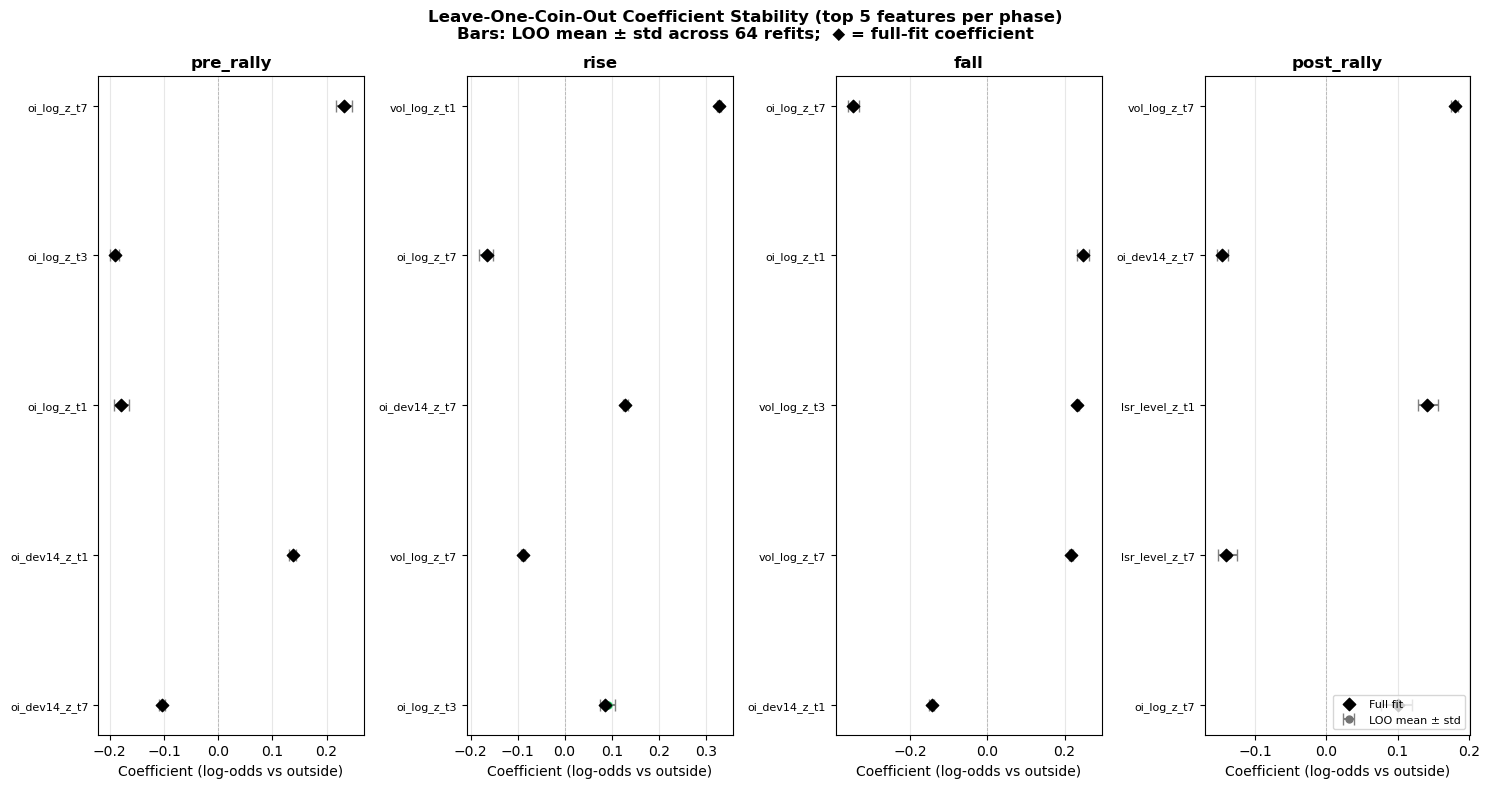

Saved → section5_5_loo_stability_plot.png


In [3]:
# Leave-One-Coin-Out Coefficient Stability Plot

# For the top 5 features per phase (ranked by absolute full-fit coefficient),
# plots LOO mean ± LOO std as a horizontal error bar with the full-fit value
# overlaid as a diamond. Tight clusters indicate the coefficient is robust;
# wide spreads or sign flips indicate one coin disproportionately drives the
# estimate.
#
# Reads:  section3_5_loo_summary.csv (full_coef, loo_mean, loo_std per
#         (phase, feature))
# Output: section5_5_loo_stability_plot.png

df_loo_summary = pd.read_csv("section3_5_loo_summary.csv")
df_loo_summary["abs_full"] = df_loo_summary["full_coef"].abs()

# Top 5 features per phase
top5 = (df_loo_summary
        .sort_values(["phase", "abs_full"], ascending=[True, False])
        .groupby("phase")
        .head(5))

fig, axes = plt.subplots(1, 4, figsize=(15, 8), sharey=False)
fig.suptitle(
    "Leave-One-Coin-Out Coefficient Stability (top 5 features per phase)\n"
    "Bars: LOO mean ± std across 64 refits;  ◆ = full-fit coefficient",
    fontsize=12, fontweight="bold",
)

for ax, phase_code in zip(axes, NON_REF_CLASSES):
    phase_name = PHASE_NAMES[phase_code]
    sub = top5[top5["phase"] == phase_name].reset_index(drop=True)
    if sub.empty:
        ax.set_title(phase_name, fontweight="bold")
        ax.axis("off")
        continue
    y_pos = np.arange(len(sub))
    ax.errorbar(
        sub["loo_mean"], y_pos, xerr=sub["loo_std"],
        fmt="o", color=PHASE_COLORS[phase_name],
        ecolor="gray", elinewidth=1.5, capsize=4, markersize=5,
        label="LOO mean ± std",
    )
    ax.scatter(
        sub["full_coef"], y_pos,
        marker="D", color="black", s=40, zorder=5, label="Full fit",
    )
    ax.axvline(0, color="gray", lw=0.6, ls="--", alpha=0.5)
    ax.set_yticks(y_pos)
    ax.set_yticklabels(sub["feature"], fontsize=8)
    ax.invert_yaxis()
    ax.set_title(phase_name, fontweight="bold")
    ax.set_xlabel("Coefficient (log-odds vs outside)")
    ax.grid(alpha=0.3, axis="x")

axes[-1].legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.savefig("section5_5_loo_stability_plot.png", dpi=150, bbox_inches="tight")
plt.show()

print("Saved → section5_5_loo_stability_plot.png")


The detection rule is now tested against external evidence in the form of a curated registry of well-documented meme-coin rallies inside the panel window. The registry is built independently of the rule from press coverage and academic mentions, so the coverage statistic measures whether the rule recovers the episodes the meme-coin literature treats as canonical (BONK December 2023, WIF early 2024, DOGE November-December 2024, TRUMP and MELANIA January 2025, among others) without having been tuned to do so.

<h4 style="color:green;">Internal validation: Famous Rally Coverage</h4>

In [ ]:
# Validates the rule-based detector against a registry of well-documented meme coin rallies that fall inside the panel window (01/04/2022 → 30/04/2026).
# For each registry entry, check whether any detected episode for that coin has its peak within the expected date window.

# Output: section3_6_famous_rally_coverage.csv

# Famous-rally registry — all entries inside the panel window. (symbol, label, window_start, window_end)
# Windows are intentionally generous so a detected episode peaking inside the window counts as "caught". Edit freely.

FAMOUS_RALLIES = [
    # 2022
    ("DOGE",     "DOGE Oct-Nov 2022 (Musk Twitter buy)", "2022-10-15", "2022-11-30"),

    # 2023
    ("PEPE",     "PEPE launch surge May 2023",          "2023-05-01", "2023-06-15"),
    ("ORDI",     "ORDI late-2023 BRC-20 rally",         "2023-11-01", "2024-03-15"),
    ("BONK",     "BONK December 2023 parabolic surge",  "2023-12-01", "2024-01-31"),
    ("FLOKI",    "FLOKI December 2023 surge",           "2023-11-15", "2024-01-15"),
    ("TURBO",    "TURBO late-2023 surge",               "2023-11-15", "2024-01-15"),

    # 2024, first half
    ("WIF",      "WIF Jan-March 2024 surge",            "2024-01-15", "2024-04-15"),
    ("PEPE",     "PEPE March 2024 second surge",        "2024-02-15", "2024-04-15"),
    ("SHIB",     "SHIB March 2024 surge",               "2024-02-15", "2024-04-15"),
    ("FLOKI",    "FLOKI March 2024 surge",              "2024-02-15", "2024-04-15"),
    ("BOME",     "BOME launch surge March 2024",        "2024-03-01", "2024-05-15"),
    ("DEGEN",    "DEGEN early 2024 surge",              "2024-02-15", "2024-04-30"),

    # 2024, second half
    ("MOG",      "MOG mid-2024 surge",                  "2024-05-01", "2024-08-15"),
    ("POPCAT",   "POPCAT mid-2024 parabolic",           "2024-06-01", "2024-10-15"),
    ("NEIRO",    "NEIRO Aug-Sept 2024 launch surge",    "2024-08-01", "2024-10-15"),
    ("GOAT",     "GOAT Oct 2024 (AI agent narrative)",  "2024-10-01", "2024-11-30"),
    ("ACT",      "ACT October 2024 surge",              "2024-10-01", "2024-11-30"),
    ("MOODENG",  "MOODENG Oct-Nov 2024 surge",          "2024-09-15", "2024-12-15"),
    ("PNUT",     "PNUT November 2024 surge",            "2024-11-01", "2024-12-15"),
    ("DOGE",     "DOGE Nov-Dec 2024 (Trump rally)",     "2024-10-15", "2025-01-15"),
    ("FARTCOIN", "FARTCOIN Nov 2024 - Jan 2025",        "2024-11-01", "2025-02-15"),
    ("AIXBT",    "AIXBT Dec 2024 - Jan 2025",           "2024-12-01", "2025-02-15"),

    # 2025
    ("PIPPIN",   "PIPPIN January 2025 launch",          "2025-01-01", "2025-02-28"),
    ("TRUMP",    "TRUMP coin January 2025 launch",      "2025-01-15", "2025-02-15"),
    ("MELANIA",  "MELANIA coin January 2025 launch",    "2025-01-18", "2025-02-15"),
    ("ANIME",    "ANIME early 2025 launch surge",       "2025-01-15", "2025-03-15"),
]

WINDOW_START
WINDOW_END 

print("=" * 92)
print("Internal Validation: Famous Rally Coverage")
print("=" * 92)
print(f"  Registry entries          : {len(FAMOUS_RALLIES)}")
print(f"  Detected episodes in panel: {len(df_episodes)}")
print(f"  Panel window              : {WINDOW_START_DT.date()} → {WINDOW_END_DT.date()}")
print(f"\n  Coverage check (episode peak inside the registry window = caught)")
print(f"  {'─' * 92}")
print(f"  {'Symbol':<10} {'Event':<40} {'Expected window':<26} {'Status'}")
print(f"  {'─' * 92}")

coverage_rows = []
for symbol, label, w_start, w_end in FAMOUS_RALLIES:
    w_start = pd.Timestamp(w_start)
    w_end   = pd.Timestamp(w_end)

    if w_end < WINDOW_START_DT:
        status, n_in, caught_dates, in_scope = "before panel window", 0, "", False
    elif w_start > WINDOW_END_DT:
        status, n_in, caught_dates, in_scope = "after panel window", 0, "", False
    else:
        in_scope = True
        coin_eps = df_episodes[df_episodes["symbol"] == symbol].copy()
        if coin_eps.empty:
            status, n_in, caught_dates = "coin not in matched universe", 0, ""
        else:
            coin_eps["peak_date"] = pd.to_datetime(coin_eps["peak_date"])
            in_win = coin_eps[(coin_eps["peak_date"] >= w_start) &
                              (coin_eps["peak_date"] <= w_end)]
            n_in = len(in_win)
            if n_in == 0:
                status, caught_dates = "MISSED", ""
            else:
                status = f"caught ({n_in} episode{'s' if n_in > 1 else ''})"
                caught_dates = ", ".join(d.strftime("%Y-%m-%d")
                                          for d in sorted(in_win["peak_date"]))

    coverage_rows.append({
        "symbol"              : symbol,
        "event_label"         : label,
        "window_start"        : w_start.date(),
        "window_end"          : w_end.date(),
        "in_panel_scope"      : in_scope,
        "n_episodes_in_window": n_in,
        "caught_peak_dates"   : caught_dates,
        "status"              : status,
    })

    win_str = f"{w_start.date()} → {w_end.date()}"
    print(f"  {symbol:<10} {label:<40} {win_str:<26} {status}")

df_coverage = pd.DataFrame(coverage_rows)
df_coverage.to_csv("section3_6_famous_rally_coverage.csv", index=False)

# Summary
n_total      = len(df_coverage)
n_in_scope   = df_coverage["in_panel_scope"].sum()
n_caught     = (df_coverage["n_episodes_in_window"] > 0).sum()
n_missed     = (df_coverage["status"] == "MISSED").sum()
n_coin_miss  = (df_coverage["status"] == "coin not in matched universe").sum()
n_out_scope  = n_total - n_in_scope

print(f"\n  Summary")
print(f"  {'─' * 60}")
print(f"  Total registry entries        : {n_total}")
print(f"  Out of panel scope            : {n_out_scope}")
print(f"  Coin not in matched universe  : {n_coin_miss}")
print(f"  In scope, caught by rule      : {n_caught}")
print(f"  In scope, missed              : {n_missed}")
if n_in_scope - n_coin_miss > 0:
    rate = n_caught / (n_in_scope - n_coin_miss)
    print(f"  Coverage rate (testable)      : {rate:.1%}")

print(f"\n  Saved → section3_6_famous_rally_coverage.csv")


<h4 style="color:green;">Detection Rule Threshold Sensitivity Sweep</h4>
Detection in the main analysis fixes the three rule parameters at 35 percent minimum rise, 25 percent minimum drawdown, and a 24-bar lookback. This cell perturbs each parameter one at a time, holding the other two at baseline (rise tested at 30/35/40 percent; drawdown at 20/25/30 percent; lookback at 18/24/30 bars). A full Cartesian grid would yield 27 cells but would obscure which parameter drives which effect; the one-at-a-time design isolates each contribution.

In [ ]:

# Sweeps the three core detection parameters one at a time (holding the
# other two at baseline) to show how rally count and composition vary
# with the threshold choices:
#
#   - MIN_RISE_PCT     (baseline 35.0)
#   - MIN_DRAWDOWN_PCT (baseline 25.0)
#   - LOOKBACK_DAYS    (baseline 24)
#
# Re-runs the Phase 2 detection rule under each setting and summarises
# the resulting episode set.
#
# Output: section3_6_threshold_sensitivity.csv

from scipy.signal import find_peaks

def detect_episodes_with_params(
    df_ohlcv_local,
    min_rise_pct=35.0,
    min_drawdown_pct=25.0,
    lookback_days=24,
    lookforward_days=24,
    peak_distance=5,
):
    """Re-runs Phase 2 detection with custom thresholds. Returns df_episodes."""
    def detect_for_coin(df_coin):
        df = df_coin.sort_values("date").reset_index(drop=True)
        close = df["close"].values.astype(float)
        n = len(df)
        eps = []
        peak_indices, _ = find_peaks(close, distance=peak_distance)
        for p_idx in peak_indices:
            peak_price = close[p_idx]
            lb_start = max(0, p_idx - lookback_days)
            lb_slice = close[lb_start:p_idx]
            if len(lb_slice) == 0:
                continue
            t_idx = lb_start + int(np.argmin(lb_slice))
            trough_price = close[t_idx]
            rise_pct = np.log(peak_price / trough_price) * 100
            if rise_pct < min_rise_pct:
                continue
            lf_end = min(n, p_idx + 1 + lookforward_days)
            lf_slice = close[p_idx + 1: lf_end]
            if len(lf_slice) == 0:
                continue
            drawdown_pct = (peak_price - lf_slice) / peak_price * 100
            hit = np.where(drawdown_pct >= min_drawdown_pct)[0]
            if len(hit) == 0:
                continue
            e_idx = p_idx + 1 + int(hit[0])
            fall_pct = (peak_price - close[e_idx]) / peak_price * 100
            eps.append({
                "trough_idx": t_idx, "peak_idx": p_idx, "end_idx": e_idx,
                "rise_pct": rise_pct, "rise_days": int(p_idx - t_idx),
                "fall_pct": fall_pct, "fall_days": int(e_idx - p_idx),
            })
        # Deduplicate overlapping episodes
        if len(eps) <= 1:
            return eps
        eps = sorted(eps, key=lambda e: e["peak_idx"])
        kept = [eps[0]]
        for ep in eps[1:]:
            last = kept[-1]
            if ep["trough_idx"] <= last["end_idx"]:
                if ep["rise_pct"] > last["rise_pct"]:
                    kept[-1] = ep
            else:
                kept.append(ep)
        return kept

    out = []
    for ticker, df_coin in df_ohlcv_local.groupby("symbol"):
        for ep in detect_for_coin(df_coin):
            ep["symbol"] = ticker
            out.append(ep)
    return pd.DataFrame(out) if out else pd.DataFrame()

def summarise(df_eps):
    if df_eps.empty:
        return dict(n_episodes=0, n_coins=0,
                    rise_mean=np.nan, rise_median=np.nan,
                    fall_mean=np.nan, fall_median=np.nan,
                    rise_days_median=np.nan, fall_days_median=np.nan)
    return dict(
        n_episodes=len(df_eps),
        n_coins=df_eps["symbol"].nunique(),
        rise_mean=df_eps["rise_pct"].mean(),
        rise_median=df_eps["rise_pct"].median(),
        fall_mean=df_eps["fall_pct"].mean(),
        fall_median=df_eps["fall_pct"].median(),
        rise_days_median=df_eps["rise_days"].median(),
        fall_days_median=df_eps["fall_days"].median(),
    )

BASELINE = dict(min_rise_pct=35.0, min_drawdown_pct=25.0, lookback_days=24)
RISE_GRID     = [25.0, 30.0, 35.0, 40.0, 45.0, 50.0]
DRAWDOWN_GRID = [15.0, 20.0, 25.0, 30.0, 35.0]
LOOKBACK_GRID = [14, 21, 24, 30, 45]

print("=" * 92)
print("Detection Rule Threshold Sensitivity Sweep")
print("=" * 92)
print(f"  Baseline: rise≥{BASELINE['min_rise_pct']}%, "
      f"drawdown≥{BASELINE['min_drawdown_pct']}%, "
      f"lookback={BASELINE['lookback_days']}d")
print(f"  One-at-a-time sweep, other two parameters at baseline.")

sweep_rows = []
for label, grid, fixed_keys in [
    ("min_rise_pct",     RISE_GRID,     ("min_drawdown_pct", "lookback_days")),
    ("min_drawdown_pct", DRAWDOWN_GRID, ("min_rise_pct",     "lookback_days")),
    ("lookback_days",    LOOKBACK_GRID, ("min_rise_pct",     "min_drawdown_pct")),
]:
    print(f"\n  Sweeping {label}...")
    print(f"  {'value':<10} {'episodes':>9} {'coins':>6} "
          f"{'rise_med':>9} {'fall_med':>9} {'rise_days':>10} {'fall_days':>10}")
    for v in grid:
        kwargs = {fk: BASELINE[fk] for fk in fixed_keys}
        kwargs[label] = v
        df_eps = detect_episodes_with_params(df_ohlcv, **kwargs)
        s = summarise(df_eps)
        s.update({"parameter": label, "value": v,
                  "is_baseline": v == BASELINE[label]})
        sweep_rows.append(s)
        marker = "  <-- BASELINE" if v == BASELINE[label] else ""
        print(f"  {v:<10} {s['n_episodes']:>9d} {s['n_coins']:>6d} "
              f"{s['rise_median']:>8.1f}% {s['fall_median']:>8.1f}% "
              f"{int(s['rise_days_median']):>10d} {int(s['fall_days_median']):>10d}"
              f"{marker}")

df_sweep = pd.DataFrame(sweep_rows)
df_sweep.to_csv("section3_6_threshold_sensitivity.csv", index=False)
print(f"\n  Saved → section3_6_threshold_sensitivity.csv ({len(df_sweep)} rows)")


<h3 style="color:blue;">Future Work: Google Trends Integration</h3>

The remaining block pulls Google Trends search interest for each coin and aligns it with the detected episodes. The hypothesis it tests, drawing from herd-behaviour theory, is that search-volume spikes should predict the first rally of each coin (the viral moment) more reliably than subsequent rallies once the asset is already known. The code is included here as a scaffold for future-work integration rather than as part of the core empirical claim.


In [ ]:
# Google Trends Scaffold (Future-Work Module)

# Pulls Google Trends interest-over-time per coin, aligns with the episode
# panel, and tests Mostafa's hypothesis: search-volume spikes should
# predict the FIRST rally of each coin (the viral moment) more reliably
# than subsequent rallies.
#
# Two parts:
#   (a) Pull weekly Google Trends 2022-2026 for each coin name
#   (b) Build a "first-rally vs subsequent-rally" comparison panel and
#       fit two small models: with and without Google Trends added to
#       the predictor set.
# Notes:
#   - pytrends has no official API; rate-limited. Run-time ~10-15 min.
#   - Daily Google Trends only resolves over windows ≤9 months; weekly
#     is used over the full panel window.
#   - Coin keyword mapping uses CoinGecko "name" field, falling back to
#     "<ticker> crypto" if name is ambiguous.
#
# Output: section6_google_trends_panel.csv
#         section6_google_trends_first_vs_subsequent.png
#         section6_google_trends_f1_comparison.csv

!pip install --upgrade pytrends --quiet

# Compatibility shim: urllib3 v2 removed `method_whitelist` (renamed to
# `allowed_methods`), but older pytrends installs still pass the old name
# into urllib3.util.retry.Retry. Rename the kwarg transparently so pytrends
# can construct its internal retry object on modern urllib3.
#
# IMPORTANT: this shim is IDEMPOTENT. It stores the truly-original
# Retry.__init__ on the Retry class itself the first time it runs, and
# subsequent re-executions just rebind __init__ to a fresh wrapper that
# delegates to the stored original — never to the previous wrapper. This
# prevents the wrapper-stacking that would otherwise produce RecursionError
# after a few cell re-runs.
#
# If you previously hit RecursionError from an older version of this shim,
# RESTART THE KERNEL once before running this cell — there is no way to
# unwind an already-stacked chain of wrappers from inside the same session.
import urllib3.util.retry as _retry_mod

if not hasattr(_retry_mod.Retry, "_TRUE_ORIGINAL_INIT"):
    _retry_mod.Retry._TRUE_ORIGINAL_INIT = _retry_mod.Retry.__init__

def _retry_init_compat(self, *args, **kwargs):
    if "method_whitelist" in kwargs:
        kwargs["allowed_methods"] = kwargs.pop("method_whitelist")
    return type(self)._TRUE_ORIGINAL_INIT(self, *args, **kwargs)

_retry_mod.Retry.__init__ = _retry_init_compat

from pytrends.request import TrendReq  # Connects to Google Trends API

# Load matched universe and episodes
df_matched  = pd.read_csv("step2_matched_coins.csv")
df_episodes = pd.read_csv("phase2_episodes.csv",
                          parse_dates=["trough_date", "peak_date", "end_date"])

# Build keyword mapping. Edit overrides where ambiguous.
KEYWORD_OVERRIDES = {
    "DOGE": "dogecoin",
    "SHIB": "shiba inu coin",
    "PEPE": "pepe coin",
    "BONK": "bonk coin",
    "FLOKI": "floki coin",
    "WIF": "dogwifhat",
    "TRUMP": "trump coin",
    "LIBRA": "libra crypto",
    "BRETT": "brett coin",
    "MEW": "cat in dogs world",
}
def keyword_for(row):
    sym = row["symbol"]
    if sym in KEYWORD_OVERRIDES:
        return KEYWORD_OVERRIDES[sym]
    if "name" in row and pd.notna(row["name"]):
        return f"{row['name']} crypto"
    return f"{sym} coin"

df_matched["gt_keyword"] = df_matched.apply(keyword_for, axis=1)

# --- (a) Pull Google Trends weekly series for each coin --------------------
pytrends = TrendReq(hl="en-US", tz=360, retries=3, backoff_factor=0.5)
GT_TIMEFRAME = "2022-04-01 2026-04-30"

gt_records = []
errors = []
for i, row in df_matched.iterrows():
    kw = row["gt_keyword"]
    sym = row["symbol"]
    try:
        pytrends.build_payload([kw], timeframe=GT_TIMEFRAME, geo="", gprop="")
        series = pytrends.interest_over_time()
        if series.empty:
            errors.append((sym, kw, "empty"))
            continue
        series = series.reset_index()[["date", kw]].rename(columns={kw: "gt_interest"})
        series["symbol"] = sym
        series["keyword"] = kw
        gt_records.append(series)
        print(f"  [{i+1:>3}/{len(df_matched)}] {sym:<8} '{kw}' "
              f"({len(series)} weeks)")
    except Exception as e:
        errors.append((sym, kw, str(e)))
        print(f"  [{i+1:>3}/{len(df_matched)}] {sym:<8} '{kw}' FAILED: {e}")
    time.sleep(1.5)  # rate-limit

df_gt = pd.concat(gt_records, ignore_index=True) if gt_records else pd.DataFrame()
df_gt.to_csv("section6_google_trends_weekly.csv", index=False)
print(f"\nPulled {df_gt['symbol'].nunique() if len(df_gt) else 0} of "
      f"{len(df_matched)} coins. {len(errors)} errors.")

# --- (b) First-rally vs subsequent-rally comparison ------------------------
# For each coin, rank its episodes by trough_date and tag #1 as 'first',
# the rest as 'subsequent'.
df_episodes_sorted = df_episodes.sort_values(["symbol", "trough_date"]).copy()
df_episodes_sorted["rally_rank"] = (df_episodes_sorted
                                    .groupby("symbol")["trough_date"]
                                    .rank(method="first").astype(int))
df_episodes_sorted["rally_class"] = np.where(
    df_episodes_sorted["rally_rank"] == 1, "first", "subsequent"
)

# Compute pre-trough Google Trends slope (4-week window before trough)
def pre_trough_gt(row):
    sym = row["symbol"]
    trough = pd.Timestamp(row["trough_date"])
    coin_gt = df_gt[df_gt["symbol"] == sym]
    if coin_gt.empty:
        return np.nan
    pre = coin_gt[(coin_gt["date"] >= trough - pd.Timedelta(days=28)) &
                  (coin_gt["date"] <  trough)]
    if len(pre) < 2:
        return np.nan
    y = pre["gt_interest"].values
    x = np.arange(len(y))
    return float(np.polyfit(x, y, 1)[0])  # slope (interest per week)

df_episodes_sorted["gt_pre_slope_4w"] = df_episodes_sorted.apply(pre_trough_gt, axis=1)
df_episodes_sorted.to_csv("section6_google_trends_panel.csv", index=False)

# Boxplot: first vs subsequent
fig, ax = plt.subplots(figsize=(7, 5))
first_vals = df_episodes_sorted.loc[
    df_episodes_sorted["rally_class"] == "first", "gt_pre_slope_4w"
].dropna()
sub_vals = df_episodes_sorted.loc[
    df_episodes_sorted["rally_class"] == "subsequent", "gt_pre_slope_4w"
].dropna()
bp = ax.boxplot([first_vals, sub_vals],
                labels=[f"First (n={len(first_vals)})",
                        f"Subsequent (n={len(sub_vals)})"],
                patch_artist=True, showmeans=True)
for patch, color in zip(bp["boxes"], ["#22c55e", "#94a3b8"]):
    patch.set_facecolor(color)
    patch.set_alpha(0.6)
ax.axhline(0, color="black", lw=0.6, ls="--", alpha=0.5)
ax.set_ylabel("Google Trends slope, 4 weeks pre-trough")
ax.set_title("Pre-Trough Search-Volume Slope:\nFirst Rally vs Subsequent Rallies",
             fontweight="bold")
ax.grid(alpha=0.3, axis="y")

# Welch's t-test annotation
if len(first_vals) > 5 and len(sub_vals) > 5:
    t, p = stats.ttest_ind(first_vals, sub_vals, equal_var=False)
    ax.text(0.5, 0.95, f"Welch's t = {t:.2f}, p = {p:.3f}",
            transform=ax.transAxes, ha="center",
            bbox=dict(facecolor="white", alpha=0.8, edgecolor="gray"))

plt.tight_layout()
plt.savefig("section6_google_trends_first_vs_subsequent.png",
            dpi=150, bbox_inches="tight")
plt.show()

# --- Bonus: refit predictive with Google Trends added as a feature ---------
# Align the weekly GT series onto the daily model panel via forward-fill,
# then add 'gt_interest_t1', 'gt_interest_t7' as features. Compare macro-F1
# with and without to see if GT carries marginal predictive content.
df_panel = pd.read_csv("phase4_model_matrix.csv", parse_dates=["date"])

# Convert weekly GT to daily via ffill within coin
df_gt_daily_chunks = []
for sym, g in df_gt.groupby("symbol"):
    g = g.sort_values("date").set_index("date")
    full = pd.date_range(g.index.min(), g.index.max(), freq="D")
    daily = g.reindex(full).ffill().reset_index().rename(columns={"index": "date"})
    daily["symbol"] = sym
    df_gt_daily_chunks.append(daily[["symbol", "date", "gt_interest"]])
df_gt_daily = pd.concat(df_gt_daily_chunks, ignore_index=True)

df_panel_gt = df_panel.merge(df_gt_daily, on=["symbol", "date"], how="left")
df_panel_gt = df_panel_gt.sort_values(["symbol", "date"])
df_panel_gt["gt_interest_t1"] = df_panel_gt.groupby("symbol")["gt_interest"].shift(1)
df_panel_gt["gt_interest_t7"] = df_panel_gt.groupby("symbol")["gt_interest"].shift(7)

PREDICTORS_BASE = [f"{f}_t{lag}" for lag in LAGS for f in BASE_FEATURES] + ["lsr_observed"]
PREDICTORS_GT   = PREDICTORS_BASE + ["gt_interest_t1", "gt_interest_t7"]

from sklearn.linear_model import LogisticRegression #Implements Logistic Regression models.
from sklearn.model_selection import TimeSeriesSplit #Splits data into chronological training/test sets
#(used for walk-forward validation)
from sklearn.metrics import f1_score #Computes the F1 Score

def walk_forward_f1(df, predictors, n_splits=5):
    sub = df.dropna(subset=predictors + ["target"]).reset_index(drop=True)
    X = sub[predictors].values
    y = sub["target"].astype(int).values
    tscv = TimeSeriesSplit(n_splits=n_splits)
    f1s = []
    for tr, te in tscv.split(X):
        clf = LogisticRegression(class_weight="balanced",
                                 solver="lbfgs", max_iter=2000)
        clf.fit(X[tr], y[tr])
        f1s.append(f1_score(y[te], clf.predict(X[te]), average="macro"))
    return float(np.mean(f1s)), float(np.std(f1s)), len(sub)

f1_base = walk_forward_f1(df_panel_gt, PREDICTORS_BASE)
f1_gt   = walk_forward_f1(df_panel_gt, PREDICTORS_GT)

df_cmp = pd.DataFrame([
    {"spec": "Base (derivatives only)",
     "f1_mean": f1_base[0], "f1_std": f1_base[1], "n_obs": f1_base[2]},
    {"spec": "Base + Google Trends",
     "f1_mean": f1_gt[0],   "f1_std": f1_gt[1],   "n_obs": f1_gt[2]},
])
df_cmp.to_csv("section6_google_trends_f1_comparison.csv", index=False)
print("\nMacro-F1 comparison:")
print(df_cmp.to_string(index=False))

print(f"\nSaved → section6_google_trends_panel.csv")
print(f"Saved → section6_google_trends_first_vs_subsequent.png")
print(f"Saved → section6_google_trends_f1_comparison.csv")
print(f"Saved → section6_google_trends_weekly.csv")


The manifest lists every artifact saved by the notebook (section_*, phase_*, step_* files and meme_coins_filtered.csv) by name, size, and last-modified timestamp. It serves as the final cross-check before submission, allowing each thesis figure or table to be traced directly to the file that produced it.

In [ ]:
# Output Manifest
#
# Lists every section_* and phase_* file in the working directory with size
# and last-modified time. Useful as a final cross-check before submission so
# you can trace each thesis figure or table back to its source artifact.

import os
from glob import glob

PATTERNS = ["section*", "phase*", "step*", "meme_coins_filtered.csv"]

rows = []
seen = set()
for pat in PATTERNS:
    for path in sorted(glob(pat)):
        if path in seen:
            continue
        seen.add(path)
        st = os.stat(path)
        rows.append({
            "file"        : path,
            "size_kb"     : st.st_size / 1024,
            "modified"    : datetime.fromtimestamp(st.st_mtime).strftime("%Y-%m-%d %H:%M"),
        })

df_manifest = pd.DataFrame(rows).sort_values("file").reset_index(drop=True)
print(f"=== Output manifest ({len(df_manifest)} files) ===")
print(df_manifest.to_string(index=False))
df_manifest.to_csv("section_output_manifest.csv", index=False)
print("\nSaved → section_output_manifest.csv")


<h3 style="color:blue;">Data Quality: Issues and Resolution Notes</h3>

<b>Issue 1: Missing LSR for major meme coins (PEPE, SHIB, FLOKI, BONK, MOG, LUNA, CAT, GOAT, PNUT)</b>

For ten coins in the matched universe, the long/short ratio series returned zero observations from the fallback chain even though Binance and Bybit visibly list these markets on the Coinalyze website. This happened because of a multiplier-prefix mismatch in the symbol construction logic. Binance and Bybit list low-priced coins as scaled contracts that is 1000PEPEUSDT_PERP.A, 1000000MOGUSDT_PERP.A, so that one contract represents 1,000 or 1,000,000 underlying tokens. Gate.io, which served as the primary exchange for most coins in the universe, lists the same markets without scaling (PEPE_USDT.Y). The Phase 3 fallback constructed candidate symbols using the unscaled base_asset value inherited from the Gate.io listing, producing strings such as PEPEUSDT_PERP.A that do not exist. Both the index-based lookup and the brute-force exchange loop therefore failed silently. Open interest sometimes succeeded because OKX and HTX list the unscaled variant for some of these coins; long/short ratio data is concentrated on Binance and Bybit, where the scaled prefix is mandatory.

To Solve this issue, the fallback now indexes each Coinalyze listing under both the original base_asset and the multiplier-stripped parameters, so a query for PEPE returns Binance's 1000PEPEUSDT_PERP.A and Bybit's 1000PEPEUSDT.6 alongside the Gate.io entry. The brute-force step has been extended to attempt the unprefixed, 1000-, and 1000000- variants of each exchange code before moving on.

<b>Issue 2: Row count differences across OI, FR, and LSR within the same exchange </b>

For coins where all three derivative series resolved to the same exchange (e.g., JOE, AVA, TUT on Binance), the row counts still differ slightly from the price data collected. Newer coins exhibit larger discrepancies that is BANANAS31 returned 508 days of funding rate but only 405 days of open interest from the same Binance listing. Reason being that Coinalyze ingests open interest, funding rate, and long/short ratio as three independent data streams per exchange, with independent activation dates. For mature coins the three streams come online within one to three days of each other (the lag corresponds to when the first complete UTC daily candle could be formed). For newer or smaller coins the gap can extend to weeks or months, reflecting either staggered rollout on the exchange's side or staggered ingestion on Coinalyze's side. Per Coinalyze's documentation, daily-granularity history is retained indefinitely, so the differences are not the result of a retention cap; they reflect when each metric first became available for that specific market. No mid-series gaps were detected in the collected data.

The differences are characteristic of the data source rather than a defect in the collection pipeline and are therefore documented rather than corrected as part of the data quality criteria. Subsequent analysis will (i) record per-coin start dates for each derivative metric in a provenance table, and (ii) restrict event-window analyses to dates with joint coverage across the metrics required for the test in question.

<b>Issue 3: Selecting the exchange with the longest history per coin per metric </b>

The original collection logic stopped at the first non-empty response, meaning that whenever the Phase 2 primary exchange returned any data the search ended there. Cross-checking individual coins revealed that other listings often carried longer historical windows. For DOGE, the Gate.io primary returned 1,204 funding-rate observations while Bybit's listing extended further back; for several mid-cap coins, Binance held more open-interest history than the originally selected exchange.
What happened? Phase 2 selects one exchange per coin using a coverage-ranked priority order optimised for universe-wide coin availability rather than per-coin historical depth. An exchange that lists many meme coins is not necessarily the same exchange that holds the longest derivative history for any individual coin within that universe.

Resolution: The fallback chain has been replaced with a best-source rule. For each coin and each derivative metric independently, every candidate listing in the market index is queried and the response with the largest number of observations is retained, with ties resolved in favour of the primary exchange. The brute-force exchange loop is preserved as a last resort for coins whose listings the index does not surface. This rule is applied uniformly to open interest, funding rate, and long/short ratio, and the source exchange for each metric is recorded per coin in the output panel.

<b>Issue 4: Four coins did not return some features during data collection. </b>

The coins GME, VINE, LUNA, & ZERE returned partial data (missing OI, LSR)during the data collection process. Hence, we needed to investigate the coins individually to know if there was an issue with the call or the feature simply just did not exist on Coinalyze.

<strong style="color:green;">Note</strong>: The collection window covers 1 April 2022 to 30 April 2026, chosen to align with Coinalyze's 1500-day retention limit on open-interest history. This produces a balanced panel where OHLCV, open interest, funding rate, and long/short ratio cover approximately the same period for the major meme coins.


<b>References</b>

O'Brien, R. M. (2007). A caution regarding rules of thumb for variance inflation factors. Quality & Quantity, 41(5), 673–690.

In [ ]:
# ============================================================================
# Section 5.1 — Chronological distribution of the 363 detected rally episodes
# ----------------------------------------------------------------------------
# Builds monthly and quarterly counts of episodes by peak date, tests the
# specific periods named in the current Section 5.1 draft against the data,
# and identifies the empirically densest quarters. Use the printed output and
# the figure to verify or revise the chronological claim.
#
# Outputs:
#   section5_1_episode_timeline_monthly.csv
#   section5_1_episode_timeline_quarterly.csv
#   section5_1_episode_timeline.png
# ============================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.dates import DateFormatter, MonthLocator

print("=" * 76)
print(" Chronological Distribution of Detected Rally Episodes")
print("=" * 76)

# ── Load episode panel ──────────────────────────────────────────────────────
df_episodes = pd.read_csv(
    "phase2_episodes.csv",
    parse_dates=["trough_date", "peak_date", "end_date"],
)
n_total = len(df_episodes)
print(f" Total episodes : {n_total}")
print(f" Coins covered  : {df_episodes['symbol'].nunique()}")
print(f" First peak     : {df_episodes['peak_date'].min().date()}")
print(f" Last  peak     : {df_episodes['peak_date'].max().date()}")

# ── Monthly counts (by peak date) ───────────────────────────────────────────
df_episodes["peak_month"] = df_episodes["peak_date"].dt.to_period("M")
monthly = (df_episodes.groupby("peak_month")
                       .size()
                       .reset_index(name="n_episodes"))
monthly["peak_month"] = monthly["peak_month"].dt.to_timestamp()

full_range = pd.date_range(start="2022-04-01", end="2026-04-01", freq="MS")
monthly_full = (pd.DataFrame({"peak_month": full_range})
                .merge(monthly, on="peak_month", how="left")
                .fillna({"n_episodes": 0}))
monthly_full["n_episodes"] = monthly_full["n_episodes"].astype(int)
monthly_full["rolling_6m"] = (monthly_full["n_episodes"]
                              .rolling(window=6, center=True, min_periods=1)
                              .mean())
monthly_full.to_csv("section5_1_episode_timeline_monthly.csv", index=False)

# ── Quarterly counts (by peak date) ─────────────────────────────────────────
df_episodes["peak_quarter"] = df_episodes["peak_date"].dt.to_period("Q")
quarterly = (df_episodes.groupby("peak_quarter")
                         .size()
                         .reset_index(name="n_episodes"))
quarterly["share_pct"] = (quarterly["n_episodes"] / n_total * 100).round(1)
quarterly.to_csv("section5_1_episode_timeline_quarterly.csv", index=False)

print(f"\n Quarterly episode counts by peak date")
print(f" {'─' * 60}")
print(f" {'Quarter':<10} {'N':>5} {'Share':>8}")
print(f" {'─' * 60}")
for _, row in quarterly.iterrows():
    print(f" {str(row['peak_quarter']):<10} {int(row['n_episodes']):>5} {row['share_pct']:>7.1f}%")

# ── Test the specific claim in the current Section 5.1 draft ────────────────
periods_claimed = [
    ("Period 1 (claimed): Nov 2022 – May 2023",     "2022-11-01", "2023-05-31"),
    ("Intermediate (claimed): Jun 2023 – Sep 2024", "2023-06-01", "2024-09-30"),
    ("Period 2 (claimed): Oct 2024 – Apr 2026",     "2024-10-01", "2026-04-30"),
]

print(f"\n Test of the chronological claim in the current Section 5.1 draft")
print(f" {'─' * 70}")
print(f" {'Period':<48} {'N':>5} {'Share':>8}")
print(f" {'─' * 70}")
for label, start, end in periods_claimed:
    mask = ((df_episodes["peak_date"] >= pd.Timestamp(start)) &
            (df_episodes["peak_date"] <= pd.Timestamp(end)))
    n_in = int(mask.sum())
    share = n_in / n_total * 100
    print(f" {label:<48} {n_in:>5} {share:>7.1f}%")

# ── Empirical concentrations: top 5 quarters ────────────────────────────────
print(f"\n Top 5 quarters by episode count (empirical, not predefined)")
print(f" {'─' * 60}")
for _, row in quarterly.nlargest(5, "n_episodes").iterrows():
    print(f" {str(row['peak_quarter']):<10} {int(row['n_episodes']):>5} episodes ({row['share_pct']:>4.1f}%)")

# Quietest 4 quarters
print(f"\n Quietest 4 quarters by episode count (empirical)")
print(f" {'─' * 60}")
for _, row in quarterly.nsmallest(4, "n_episodes").iterrows():
    print(f" {str(row['peak_quarter']):<10} {int(row['n_episodes']):>5} episodes ({row['share_pct']:>4.1f}%)")

# ── Plot ────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(13, 5))

shading = [
    ("2022-11-01", "2023-05-31", "#22c55e", "Period 1 (claimed)"),
    ("2023-06-01", "2024-09-30", "#f59e0b", "Intermediate (claimed)"),
    ("2024-10-01", "2026-04-30", "#3b82f6", "Period 2 (claimed)"),
]
for start, end, color, label in shading:
    ax.axvspan(pd.Timestamp(start), pd.Timestamp(end),
               alpha=0.12, color=color, label=label)

ax.bar(monthly_full["peak_month"], monthly_full["n_episodes"],
       width=25, color="#1f4e79", alpha=0.85,
       edgecolor="white", linewidth=0.5,
       label="Episodes per month")

ax.plot(monthly_full["peak_month"], monthly_full["rolling_6m"],
        color="#dc2626", linewidth=2, label="6-month rolling mean")

ax.set_xlabel("Peak date (month)")
ax.set_ylabel("Number of detected rally episodes")
ax.set_title("Chronological distribution of 363 detected rally episodes\n"
             "(monthly count by peak date; shaded bands = periods claimed in Section 5.1)",
             fontsize=11, fontweight="bold")
ax.xaxis.set_major_locator(MonthLocator(bymonth=[1, 7]))
ax.xaxis.set_major_formatter(DateFormatter("%Y-%m"))
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
ax.legend(loc="upper left", fontsize=8, framealpha=0.95, ncol=2)
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
plt.tight_layout()
plt.savefig("section5_1_episode_timeline.png", dpi=150, bbox_inches="tight")
plt.show()

# ── Summary ─────────────────────────────────────────────────────────────────
print(f"\n{'=' * 76}")
print(f" Summary")
print(f"{'=' * 76}")
print(f" Total episodes                       : {n_total}")
print(f" Months with at least one episode     : {(monthly_full['n_episodes'] > 0).sum()}")
print(f" Months with no episodes              : {(monthly_full['n_episodes'] == 0).sum()}")
print(f" Mean episodes per month              : {monthly_full['n_episodes'].mean():.2f}")
print(f" Max episodes in a single month       : {int(monthly_full['n_episodes'].max())}")
top_row = monthly_full.loc[monthly_full['n_episodes'].idxmax()]
print(f" Top month                            : {top_row['peak_month'].strftime('%Y-%m')} "
      f"({int(top_row['n_episodes'])} episodes)")

print(f"\n Saved → section5_1_episode_timeline_monthly.csv")
print(f" Saved → section5_1_episode_timeline_quarterly.csv")
print(f" Saved → section5_1_episode_timeline.png")

In [ ]:
# ============================================================
# VIF — Lagged Predictors (t-1, t-3, t-7)
# ============================================================
import pandas as pd
import numpy as np
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

df_model = pd.read_csv("phase4_model_matrix.csv", parse_dates=["date"])

PREDICTORS = [f"{f}_t{lag}" for lag in [1, 3, 7] for f in [
    "oi_log_z", "oi_logdiff_z", "oi_dev14_z",
    "fr_level_z", "fr_cum7_z", "fr_sign",
    "lsr_level_z", "lsr_dev14_z",
    "vol_log_z", "vol_logdiff_z",
]] + ["lsr_observed"]

X = df_model[PREDICTORS].dropna().reset_index(drop=True)
X_const = sm.add_constant(X, has_constant="add")

vif_rows = []
for i, col in enumerate(X_const.columns):
    if col == "const":
        continue
    try:
        vif = variance_inflation_factor(X_const.values, i)
    except Exception:
        vif = np.nan
    vif_rows.append({"feature": col, "VIF": round(vif, 2)})

df_vif_lagged = (pd.DataFrame(vif_rows)
                 .sort_values("VIF", ascending=False)
                 .reset_index(drop=True))

df_vif_lagged.to_csv("appendix_vif_lagged_predictors.csv", index=False)

print(f"Sample: {len(X):,} rows x {len(PREDICTORS)} lagged features\n")
print(f"{'Feature':<25} {'VIF':>6}  Flag")
print("-" * 40)
for _, row in df_vif_lagged.iterrows():
    v = row["VIF"]
    flag = "[DROP]" if v > 10 else "[WATCH]" if v > 5 else "[OK]"
    print(f"  {row['feature']:<23} {v:>6.2f}  {flag}")

print(f"\nSaved → appendix_vif_lagged_predictors.csv")

In [ ]:
# ============================================================
# Famous Rally Registry — Appendix Table
# ============================================================
import pandas as pd

df_cov = pd.read_csv("section3_6_famous_rally_coverage.csv")

# Clean up for appendix presentation
df_appendix = df_cov[[
    "symbol", "event_label", "window_start", "window_end",
    "n_episodes_in_window", "caught_peak_dates", "status"
]].copy()

df_appendix.columns = [
    "Symbol", "Event", "Window Start", "Window End",
    "Episodes Detected", "Detected Peak Dates", "Status"
]

# Capitalise status for readability
df_appendix["Status"] = df_appendix["Status"].str.replace(
    r"caught \((\d+) episodes?\)", r"Caught (\1)", regex=True
).str.replace("MISSED", "Missed")

df_appendix["Detected Peak Dates"] = df_appendix["Detected Peak Dates"].fillna("—")

df_appendix.to_csv("appendix_famous_rally_registry.csv", index=False)

print(f"Registry entries: {len(df_appendix)}")
n_caught = (df_appendix["Episodes Detected"] > 0).sum()
n_missed = (df_appendix["Status"] == "Missed").sum()
print(f"Caught: {n_caught}  |  Missed: {n_missed}")
print(f"Coverage rate: {n_caught / len(df_appendix):.1%}\n")
print(df_appendix.to_string(index=False))
print(f"\nSaved → appendix_famous_rally_registry.csv")